# 03 — Evaluation

**Objective.** Score the four frozen conditions with the same rules and evaluate the matched 512-versus-768-px oracle-image experiment E1 from its frozen full run (or another saved run named by `VISUALDOC_E1_RUN_DIR`), and evaluate E2 (Qwen3-VL-8B against the frozen GPT-4o-mini cells, section 14) from its frozen full run (or another saved run named by `VISUALDOC_E2_RUN_DIR`). This notebook makes **no API call and runs no model**; it reads saved predictions.

| | |
|---|---|
| **Input** | `predictions/{A,B,C,D}.jsonl` and `manifest.json` (02); E1 design/estimates (02); the frozen E1 full run `experiments/frozen/e1/run_…/` (default) or `VISUALDOC_E1_RUN_DIR`; `render_manifest_e1.csv` (00); `questions.parquet`, `pages.parquet`, page images (00); `retrieval_summary.csv` (01); frozen result files as regression references; E2 spec, `e2/design.json` (02) and the frozen E2 full run `experiments/frozen/e2/run_…/` (default) or `VISUALDOC_E2_RUN_DIR` |
| **Output** | baseline tables and figures plus `evaluation_summary.json`; E1 paired tables, an integrity audit, `data/processed/mmlongbench_doc/e1/per_question.csv` and six figures in `data/processed/mmlongbench_doc/e1/figures/`; for a new live run, `evaluation_summary.json` and a summary figure inside that run directory (never inside `experiments/frozen/`); for E2, `e2/per_question.csv` and four figures in `data/processed/mmlongbench_doc/e2/figures/`, plus `evaluation_summary.json` inside a new live run directory (never inside `experiments/frozen/`) |

## Method

**Scoring** re-implements the rule-based stage of MMLongBench-Doc `eval/eval_score.py` (commit `d73f0dc`), using the **reference** `answer_format`:

| `answer_format` | rule |
|---|---|
| `Int` | exact equality after `int(float(prediction))` |
| `Float` | equal within 1 % relative tolerance, also accepting ×100 or ÷100 (percentage vs fraction) |
| `Str`, `None` | lower-case; strip parenthesised text, quotes, `$`, `%`. Exact match for URLs, dates, phone-like numbers, e-mails, file names; otherwise ANLS with threshold 0.5 |
| `List` | same length required; elements cleaned and sorted; exact join for numeric items, otherwise the **minimum** ANLS over pairs |

$$\text{ANLS}(g, p) = 1 - \frac{\text{Lev}(g,p)}{\max(|g|,|p|)} \ \text{ if this exceeds } 0.5, \text{ else } 0.$$

Deviations from the official code: `ast.literal_eval` instead of `eval` for list strings, and a malformed list string is treated as one string. Kept on purpose: the official `get_clean_string` tries to strip `mile`/`million` suffixes but discards the result, so those suffixes stay. Parity was checked against hand-traced cases, not by running the official file.

**Aggregates** (official definitions). *Accuracy* = mean score. *F1*: recall = answerable score / answerable questions, precision = answerable score / predictions that are not `"Not answerable"`, so F1 penalises missed answers and invented answers to unanswerable questions. A question is **correct** when its score is above 0 (ANLS scores are 0 or above 0.5).

**Citations.** *Validity*: every cited page was supplied. *Correctness*: at least one cited page is annotated evidence (answerable questions).

**Paired comparisons.** Each question is answered under both conditions of a comparison, so it is its own control. Reported: fixed / broken counts and the exact McNemar test on the discordant pairs,
$$p = \min\!\left(1,\ 2 \sum_{i=0}^{\min(f, r)} \binom{f + r}{i} 2^{-(f+r)}\right).$$
McNemar assumes independent questions, but here they are **clustered in 6 documents**, so the p-values are optimistic; the number of documents that improve or worsen is the honest unit.

In [1]:
from collections import Counter
from math import comb, isclose
from pathlib import Path
import ast
import hashlib
import json
import os
import re
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 170)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "mmlongbench_doc"
PREDICTIONS_DIR = PROCESSED_DIR / "predictions"
TESSDATA_DIR = PROJECT_ROOT / "resources" / "tessdata"
FROZEN_TEXT_RUN = PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc" / "text_run_20261119T220858Z_a351a532"
FROZEN_IMAGE_RUN = PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc" / "image_run_20261119T232847Z_65ccf1ef"
PRICES = {"input": 0.15, "output": 0.60}  # assumed USD per 1M tokens for gpt-4o-mini, as in 02

for path in [PROCESSED_DIR / "questions.parquet", PROCESSED_DIR / "pages.parquet", PROCESSED_DIR / "retrieval_summary.csv", PREDICTIONS_DIR / "manifest.json"]:
    assert path.is_file(), f"{path.name} is missing: run notebooks 00, 01 and 02 first"


def read_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]


questions = pd.read_parquet(PROCESSED_DIR / "questions.parquet")
questions["evidence_pages"] = questions["evidence_pages"].map(lambda values: [int(v) for v in values])
questions["evidence_sources"] = questions["evidence_sources"].map(list)
subset = questions[questions["in_subset"]].reset_index(drop=True)
VISUAL_SOURCES = {"Chart", "Figure"}
subset["evidence_group"] = np.where(~subset["answerable"], "unanswerable",
                                    np.where(subset["evidence_sources"].map(lambda s: bool(VISUAL_SOURCES & set(s))), "chart or figure", "text, layout or table only"))
reference = subset.set_index("qid")
pages = pd.read_parquet(PROCESSED_DIR / "pages.parquet")
page_lookup = pages.set_index(["doc_id", "page"])
image_manifest = pd.read_csv(PROCESSED_DIR / "render_manifest.csv").set_index(["doc_id", "page"])

prediction_manifest = json.loads((PREDICTIONS_DIR / "manifest.json").read_text())
records = {name: read_jsonl(PREDICTIONS_DIR / f"{name}.jsonl") for name in "ABCD"}
LABELS = {name: info["label"] for name, info in prediction_manifest["conditions"].items()}
print(f"Predictions written in mode {prediction_manifest['mode']!r} at {prediction_manifest['written_at']} (model {prediction_manifest['model']}):")
pd.DataFrame(prediction_manifest["conditions"]).T[["label", "records", "status", "source"]]

Predictions written in mode 'replay' at 2026-11-22T12:09:14+00:00 (model gpt-4o-mini-2024-07-18):


,label,records,status,source
A,"A. text, retrieved",57,replayed: {'ok': 57},experiments/frozen/mmlongbench_doc/text_run_20261119T220...
B,"B. images, retrieved",57,replayed: {'ok': 57},experiments/frozen/mmlongbench_doc/image_run_20261119T23...
C,"C. text, oracle",40,replayed: {'ok': 40},experiments/frozen/mmlongbench_doc/text_run_20261119T220...
D,"D. images, oracle",40,"replayed: {'ok': 38, 'skipped_context_limit': 2}",experiments/frozen/mmlongbench_doc/image_run_20261119T23...


## 1. Scoring rules, validated before use

In [2]:
def levenshtein_distance(s1, s2):
    if len(s1) > len(s2):
        s1, s2 = s2, s1
    distances = range(len(s1) + 1)
    for i2, c2 in enumerate(s2):
        new_distances = [i2 + 1]
        for i1, c1 in enumerate(s1):
            new_distances.append(distances[i1] if c1 == c2 else 1 + min(distances[i1], distances[i1 + 1], new_distances[-1]))
        distances = new_distances
    return distances[-1]


def anls_compute(groundtruth, prediction, threshold=0.5):
    length = max(len(groundtruth.upper()), len(prediction.upper()))
    anls = 1.0 - (0.0 if length == 0 else levenshtein_distance(groundtruth, prediction) / length)
    return 0.0 if anls <= threshold else anls


def is_float_equal(reference, prediction, include_percentage=False, is_close=False):
    def get_precision(value):
        text = str(value)
        return len(text.split(".")[-1]) if "." in text else 3

    reference = float(str(reference).strip().rstrip("%").strip())
    try:
        prediction = float(str(prediction).strip().rstrip("%").strip())
    except (TypeError, ValueError):
        return False
    for item in ([reference / 100, reference, reference * 100] if include_percentage else [reference]):
        if is_close and isclose(item, prediction, rel_tol=0.01):
            return True
        precision = max(min(get_precision(prediction), get_precision(item)), 2)
        if round(prediction, precision) == round(item, precision):
            return True
    return False


def get_clean_string(s):
    s = str(s).lower().strip()
    # Official quirk kept: the code calls s.rstrip("mile") etc. without assigning the result, so unit suffixes stay.
    s = re.sub(r"\s*\([^)]*\)", "", s).strip()  # remove parenthesised text
    s = re.sub(r"^['\"]|['\"]$", "", s).strip()  # remove surrounding quotes
    s = s.strip().lstrip("$").strip()
    return s.strip().rstrip("%").strip()


EXACT_MATCH_PATTERNS = [
    r"\b\d+(-\d+|\s\d+)?\b",  # phone-like numbers
    r"\b\d{4}[-\s]\d{2}[-\s]\d{2}\b",  # YYYY-MM-DD
    r"\b\d{4}[-\s]\d{2}\b",  # YYYY-MM
    r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}",  # e-mail address
]


def is_exact_match(s):
    return ("https://" in s or s.endswith(".py") or s.endswith("ipynb") or s.startswith("page") or "a.m." in s or "p.m." in s
            or any(re.fullmatch(pattern, s) for pattern in EXACT_MATCH_PATTERNS))


def isfloat(value):
    try:
        float(value)
        return True
    except (TypeError, ValueError):
        return False


def as_list(value):
    if isinstance(value, str) and value.startswith("["):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            pass  # deviation: the official eval() would raise here
    return value if isinstance(value, list) else [value]


def eval_score(gt, pred, answer_type):
    if answer_type == "Int":
        try:
            gt, pred = int(gt), int(float(pred))
        except Exception:  # the official code uses a bare except
            pred = ""
        score = gt == pred
    elif answer_type == "Float":
        try:
            gt, pred = float(get_clean_string(str(gt))), float(get_clean_string(str(pred)))
        except Exception:
            pred = ""
        score = is_float_equal(gt, pred, include_percentage=True, is_close=True)
    elif answer_type in ("Str", "None"):
        gt, pred = get_clean_string(gt), get_clean_string(pred)
        score = gt == pred if is_exact_match(gt) else anls_compute(gt, pred)
    else:  # List
        gt, pred = as_list(gt), as_list(pred)
        if len(gt) != len(pred):
            score = 0.0
        else:
            gt, pred = sorted(get_clean_string(i) for i in gt), sorted(get_clean_string(i) for i in pred)
            score = "-".join(gt) == "-".join(pred) if isfloat(gt[0]) or is_exact_match(gt[0]) else min(anls_compute(g, p) for g, p in zip(gt, pred))
    return float(score)


def accuracy_and_f1(scored):
    accuracy = scored["score"].mean()
    answerable, predicted_answer = scored["answer"] != "Not answerable", scored["pred"] != "Not answerable"
    if answerable.sum() == 0 or predicted_answer.sum() == 0:
        return accuracy, 0.0  # the official code catches this ZeroDivisionError and returns F1 = 0
    recall = scored.loc[answerable, "score"].sum() / answerable.sum()
    precision = scored.loc[answerable, "score"].sum() / predicted_answer.sum()
    return accuracy, (2 * recall * precision / (recall + precision) if recall + precision > 0 else 0.0)

Each case targets one branch of the rules. `expected` was traced by hand from the official source; a mismatch would mean a transcription error or a wrong trace.

In [3]:
SCORING_CASES = [  # reference, prediction, format, expected, what it checks
    ("Less well-off", "less well off", "Str", 1 - 1 / 13, "ANLS partial credit: 1 edit / 13 chars"),
    ("Pew Research Center", "Pew Research Centre", "Str", 1 - 2 / 19, "ANLS: transposition costs 2 edits"),
    ("Latinos", "Asian Americans", "Str", 0.0, "ANLS <= 0.5 is set to 0"),
    ("Not answerable", "Not answerable", "None", 1.0, "correct abstention"),
    ("Not answerable", "The report does not say", "None", 0.0, "abstention must use the exact phrase"),
    ("12", "12.0", "Int", 1.0, "Int: int(float(pred))"),
    ("12", "twelve", "Int", 0.0, "Int: unparseable prediction scores 0"),
    ("18.29%", "18.3", "Float", 1.0, "Float: 1% relative tolerance"),
    ("0.1", "10%", "Float", 1.0, "Float: fraction vs percentage (x100)"),
    ("51%", "49", "Float", 0.0, "Float: outside tolerance"),
    ("['Circle', 'Rectangle']", "['rectangle', 'circle']", "List", 1.0, "List: order and case ignored"),
    ("['White', '10%']", "['White']", "List", 0.0, "List: length mismatch scores 0"),
    ("['2014', '2016']", "['2016', '2014']", "List", 1.0, "List: numeric items use exact join"),
    ("https://www.example.com", "www.example.com", "Str", 0.0, "URL requires exact match"),
    ("2016-06", "2016-06", "Str", 1.0, "YYYY-MM requires exact match"),
    ("$1,200 (approx.)", "1,200", "Str", 1.0, "cleaning drops $ and parenthesised text"),
    ("5 miles", "5", "Str", 0.0, "official quirk: 'miles' is not stripped"),
]
cases = pd.DataFrame(SCORING_CASES, columns=["reference", "prediction", "format", "expected", "checks"])
cases["local"] = [eval_score(r, p, f) for r, p, f in zip(cases["reference"], cases["prediction"], cases["format"])]
assert all(isclose(a, b, abs_tol=1e-9) for a, b in zip(cases["local"], cases["expected"])), "a scoring rule differs from the hand trace"

# A reference answer should score 1.0 against itself; rows where it cannot are unanswerable under the official rules.
questions["self_score"] = [eval_score(r.answer, r.answer, r.answer_format) for r in questions.itertuples()]
unscorable = questions[questions["self_score"] < 1.0]
assert len(unscorable) == 4, "new unscorable references appeared"
toy = pd.DataFrame({"answer": ["A", "B", "Not answerable"], "pred": ["A", "Not answerable", "C"], "score": [1.0, 0.0, 0.0]})
assert all(isclose(x, y) for x, y in zip(accuracy_and_f1(toy), (1 / 3, 0.5)))  # 1 correct, 1 false abstention, 1 invented answer
display(cases[["reference", "prediction", "format", "checks", "local"]].round(4))
print(f"{len(cases)} rule checks and the F1 toy check passed. References that cannot score 1.0 against themselves: {len(unscorable)} of {len(questions)}; "
      f"in the subset: {unscorable.loc[unscorable['in_subset'], 'qid'].tolist()}")

,reference,prediction,format,checks,local
0,Less well-off,less well off,Str,ANLS partial credit: 1 edit / 13 chars,0.9231
1,Pew Research Center,Pew Research Centre,Str,ANLS: transposition costs 2 edits,0.8947
2,Latinos,Asian Americans,Str,ANLS <= 0.5 is set to 0,0.0000
3,Not answerable,Not answerable,None,correct abstention,1.0000
4,Not answerable,The report does not say,None,abstention must use the exact phrase,0.0000
5,12,12.0,Int,Int: int(float(pred)),1.0000
6,12,twelve,Int,Int: unparseable prediction scores 0,0.0000
7,18.29%,18.3,Float,Float: 1% relative tolerance,1.0000
8,0.1,10%,Float,Float: fraction vs percentage (x100),1.0000
9,51%,49,Float,Float: outside tolerance,0.0000


17 rule checks and the F1 toy check passed. References that cannot score 1.0 against themselves: 4 of 1091; in the subset: ['mmlb-0733', 'mmlb-0735']


## 2. Score the four conditions

A metric covers exactly the questions that received a reply. D's two context-limit skips leave its denominator by protocol, so C is also reported on the same 38 questions.

In [4]:
def score_condition(records_list):
    record_frame = pd.DataFrame(records_list)
    # E1 audit records repeat doc_id. Validate and drop duplicated reference columns before merging.
    overlap = (set(record_frame.columns) & set(subset.columns)) - {'qid'}
    for column in overlap:
        expected = subset.set_index('qid').loc[record_frame['qid'], column].tolist()
        observed = record_frame[column].map(list).tolist() if len(record_frame) and isinstance(record_frame[column].iloc[0], (list, np.ndarray)) else record_frame[column].tolist()
        assert observed == expected, f'{column} in prediction records disagrees with the question table'
    frame = subset.merge(record_frame.drop(columns=sorted(overlap)), on="qid", how="inner", validate="one_to_one")
    frame = frame[frame["status"].isin(["ok", "parse_error"])].copy()
    frame["score"] = [eval_score(r.answer, r.pred, r.answer_format) for r in frame.itertuples()]
    frame["correct"] = frame["score"] > 0
    frame["citations_valid"] = [set(c) <= set(s) for c, s in zip(frame["cited_pages"], frame["supplied_pages"])]
    frame["evidence_supplied"] = [bool(set(e) & set(s)) if a else np.nan for e, s, a in zip(frame["evidence_pages"], frame["supplied_pages"], frame["answerable"])]
    frame["cites_evidence"] = [bool(set(c) & set(e)) if a else np.nan for c, e, a in zip(frame["cited_pages"], frame["evidence_pages"], frame["answerable"])]
    frame["predicted_unanswerable"] = frame["pred"].map(lambda p: isinstance(p, str) and p == "Not answerable")
    return frame


def condition_metrics(frame):
    answerable, unanswerable = frame[frame["answerable"]], frame[~frame["answerable"]]
    accuracy, f1 = accuracy_and_f1(frame)
    return {
        "questions (answerable / unanswerable)": f"{len(answerable)} / {len(unanswerable)}",
        "correct answerable": f"{int(answerable['correct'].sum())} / {len(answerable)}",
        "accuracy on answerable": answerable["score"].mean(),
        "accuracy, all questions": accuracy,
        "F1 (official definition)": f1 if len(unanswerable) else np.nan,
        "correct abstention (unanswerable)": unanswerable["score"].mean() if len(unanswerable) else np.nan,
        "false abstention (answerable)": answerable["predicted_unanswerable"].mean(),
        "citation validity": frame["citations_valid"].mean(),
        "cites an evidence page (answerable)": answerable["cites_evidence"].astype(float).mean(),
        "unparseable replies": int((frame["status"] == "parse_error").sum()),
    }


scored = {name: score_condition(records[name]) for name in "ABCD"}
scored["C38"] = scored["C"][scored["C"]["qid"].isin(scored["D"]["qid"])]
TABLE = {"A": LABELS["A"], "B": LABELS["B"], "C": LABELS["C"] + " (40)", "C38": LABELS["C"] + " (38)", "D": LABELS["D"] + " (38)"}
metrics_table = pd.DataFrame({TABLE[n]: condition_metrics(scored[n]) for n in TABLE})
metrics_table.map(lambda v: round(v, 3) if isinstance(v, float) else v)

,"A. text, retrieved","B. images, retrieved","C. text, oracle (40)","C. text, oracle (38)","D. images, oracle (38)"
questions (answerable / unanswerable),40 / 17,40 / 17,40 / 0,38 / 0,38 / 0
correct answerable,7 / 40,7 / 40,9 / 40,9 / 38,11 / 38
accuracy on answerable,0.175,0.175,0.225,0.237,0.289
"accuracy, all questions",0.263,0.228,0.225,0.237,0.289
F1 (official definition),0.165,0.156,NaN,NaN,NaN
correct abstention (unanswerable),0.471,0.353,NaN,NaN,NaN
false abstention (answerable),0.1,0.025,0.075,0.079,0.026
citation validity,1.0,0.895,1.0,1.0,0.921
cites an evidence page (answerable),0.65,0.6,0.875,0.895,0.789
unparseable replies,0,0,0,0,0


In [5]:
# Regression against the frozen result files: every per-question score and the headline counts.
frozen_scores = {
    "A": pd.read_csv(FROZEN_TEXT_RUN / "scored_predictions.csv").set_index("qid")["score"],
    "C": pd.read_csv(FROZEN_TEXT_RUN / "oracle_paired.csv").set_index("qid")["oracle_score"],
    "B": pd.read_csv(FROZEN_IMAGE_RUN / "scored_b_images_retrieved.csv").set_index("qid")["score"],
    "D": pd.read_csv(FROZEN_IMAGE_RUN / "scored_d_images_oracle.csv").set_index("qid")["score"],
}
if prediction_manifest["mode"] == "replay":
    for name, saved in frozen_scores.items():
        now = scored[name].set_index("qid")["score"]
        assert set(now.index) == set(saved.index) and np.allclose(now.loc[saved.index], saved, atol=1e-12), name
    counts = {n: (int(scored[n].loc[scored[n]["answerable"], "correct"].sum()), int(scored[n]["answerable"].sum())) for n in ("A", "B", "C", "C38", "D")}
    assert counts == {"A": (7, 40), "B": (7, 40), "C": (9, 40), "C38": (9, 38), "D": (11, 38)}, counts
    frozen_metrics = json.loads((FROZEN_IMAGE_RUN / "summary.json").read_text())["metrics"]
    for name, key in (("A", "A. text, retrieved"), ("B", "B. images, retrieved")):
        accuracy, f1 = accuracy_and_f1(scored[name])
        assert isclose(accuracy, frozen_metrics[key]["accuracy (all questions)"]) and isclose(f1, frozen_metrics[key]["F1 (official definition)"])
    print("Regression passed: all per-question scores equal the frozen files; answerable correct A 7/40, B 7/40, C 9/40 (9/38), D 11/38; "
          "accuracy and F1 for A and B equal the frozen summary.")
else:
    print("Predictions are not the frozen replay: regression against the frozen results is not applicable.")

Regression passed: all per-question scores equal the frozen files; answerable correct A 7/40, B 7/40, C 9/40 (9/38), D 11/38; accuracy and F1 for A and B equal the frozen summary.


## 3. Retrieval versus reading: where the errors sit

Retrieval quality comes from 01. Combining it with the answers separates "the evidence was not supplied" from "the evidence was supplied and misread". The groups are defined by how much evidence BM25 put in its top 5.

In [6]:
retrieval_summary = pd.read_csv(PROCESSED_DIR / "retrieval_summary.csv", index_col="k")
print("Retrieval (01): BM25 Recall@5 {:.3f}, Hit@5 {:.3f} on 40 answerable questions.".format(
    retrieval_summary.loc[5, "BM25 Recall@k"], retrieval_summary.loc[5, "BM25 Hit@k"]))

retrieved = {r["qid"]: r["supplied_pages"] for r in records["A"]}
recall5 = {q: len(set(reference.loc[q, "evidence_pages"]) & set(retrieved[q])) / len(set(reference.loc[q, "evidence_pages"]))
           for q in subset.loc[subset["answerable"], "qid"]}
GROUPS = ["all evidence in top 5", "some evidence in top 5", "no evidence in top 5"]
retrieval_group = {q: GROUPS[0] if r == 1 else GROUPS[1] if r > 0 else GROUPS[2] for q, r in recall5.items()}
for frame in scored.values():
    frame["retrieval_group"] = frame["qid"].map(retrieval_group).fillna("unanswerable")

by_group = pd.DataFrame({TABLE[n]: scored[n][scored[n]["answerable"]].groupby("retrieval_group")["score"].mean() for n in ("A", "B", "C", "D")}).reindex(GROUPS)
by_group.insert(0, "questions", pd.Series(retrieval_group).value_counts().reindex(GROUPS))
display(by_group.round(3))

for reader, (retrieved_name, oracle_name) in {"text": ("A", "C38"), "images": ("B", "D")}.items():
    same = scored[retrieved_name][scored[retrieved_name]["qid"].isin(scored["D"]["qid"])]
    acc_r, acc_o = same["score"].mean(), scored[oracle_name]["score"].mean()
    print(f"{reader:>6} reader, 38 questions: error {1 - acc_r:.3f} = fixed by supplying the evidence {acc_o - acc_r:+.3f} "
          f"+ remaining with the evidence in context {1 - acc_o:.3f}")

Retrieval (01): BM25 Recall@5 0.689, Hit@5 0.800 on 40 answerable questions.


,questions,"A. text, retrieved","B. images, retrieved","C. text, oracle (40)","D. images, oracle (38)"
retrieval_group,,,,,
all evidence in top 5,24,0.250,0.292,0.250,0.292
some evidence in top 5,8,0.000,0.000,0.125,0.000
no evidence in top 5,8,0.125,0.000,0.250,0.571


  text reader, 38 questions: error 0.816 = fixed by supplying the evidence +0.053 + remaining with the evidence in context 0.763
images reader, 38 questions: error 0.816 = fixed by supplying the evidence +0.105 + remaining with the evidence in context 0.711


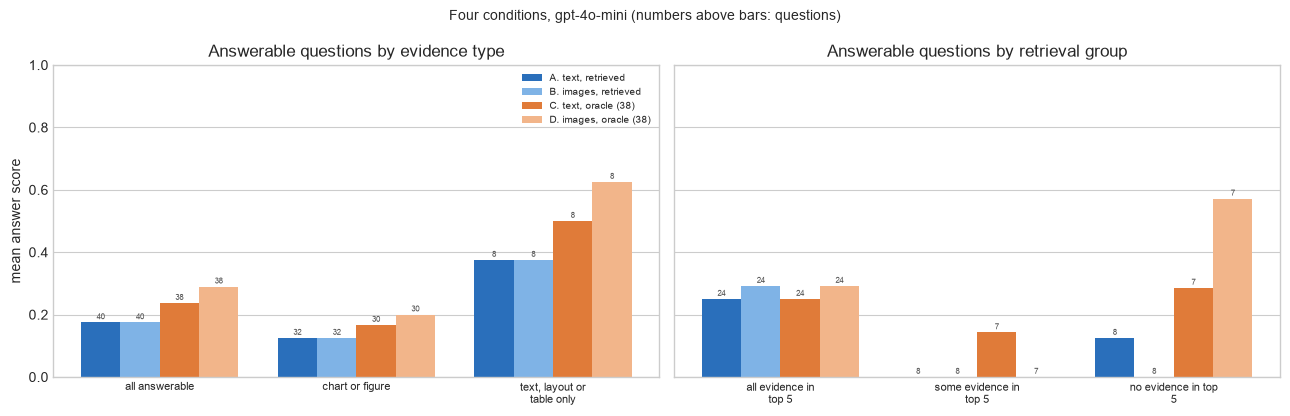

In [7]:
colors = {"A": "#2A6FBB", "B": "#7FB3E6", "C": "#E07B39", "D": "#F2B58A"}
panels = {"evidence type": ["all answerable", "chart or figure", "text, layout or table only"], "retrieval group": GROUPS}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (panel, groups) in zip(axes, panels.items()):
    x = np.arange(len(groups))
    for i, name in enumerate("ABCD"):
        frame = scored["C38" if name == "C" else name]
        frame = frame[frame["answerable"]]
        selected = [frame if g == "all answerable" else frame[frame["evidence_group" if panel == "evidence type" else "retrieval_group"] == g] for g in groups]
        bars = ax.bar(x - 0.3 + 0.2 * i, [s["score"].mean() if len(s) else np.nan for s in selected], width=0.2, color=colors[name],
                      label=LABELS[name] + (" (38)" if name in "CD" else ""))
        for bar, s in zip(bars, selected):
            ax.annotate(f"{len(s)}", (bar.get_x() + bar.get_width() / 2, np.nan_to_num(bar.get_height()) + 0.01), ha="center", fontsize=6, color="#555555")
    ax.set_xticks(x, [textwrap.fill(g, 18) for g in groups], fontsize=8)
    ax.set(title=f"Answerable questions by {panel}", ylim=(0, 1))
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("mean answer score")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle("Four conditions, gpt-4o-mini (numbers above bars: questions)", fontsize=10)
plt.tight_layout()
plt.show()

- **Text: reading is the bottleneck, not retrieval.** Supplying the evidence fixes only 2 text answers (0.184 → 0.237 on 38 questions); 0.763 of the error remains with the evidence in context.
- **Images benefit more from correct pages:** 4 fixed, 0 broken (0.184 → 0.289). All 4 image fixes are questions with **no** evidence in the BM25 top 5: once the image reader receives the page, it reads it.
- Chart and figure questions stay hard in every condition. Group sizes are 4–30 questions, so the bars show where errors sit, not precise estimates.

## 4. Image legibility per document

Resolution is a candidate cause of image failures. Tesseract OCR of the **exact image sent to the model** measures the share of the words of the text the text condition received for the same page. Three pages per document are sampled, evenly spaced among the pages B and D received. Tesseract is not gpt-4o-mini, so this is a pessimistic **proxy**, but it is a measurement.

In [8]:
WORD_PATTERN = re.compile(r"[a-z]{4,}")


def recovered_fraction(ocr_text, reference_text):
    reference_words = set(WORD_PATTERN.findall(str(reference_text).lower()))
    return len(set(WORD_PATTERN.findall(ocr_text.lower())) & reference_words) / len(reference_words) if reference_words else np.nan


def model_png(doc_id, page_number):
    return (PROJECT_ROOT / image_manifest.loc[(doc_id, page_number), "image_path"]).read_bytes()


def ocr_png(png):
    with pymupdf.open("pdf", pymupdf.Pixmap(png).pdfocr_tobytes(language="eng", tessdata=str(TESSDATA_DIR))) as ocr_pdf:
        return ocr_pdf[0].get_text()


image_pages = pd.DataFrame(sorted({(reference.loc[r["qid"], "doc_id"], p) for n in "BD" for r in records[n] for p in r["supplied_pages"]}), columns=["doc_id", "page"])
sample = pd.concat([g.iloc[np.unique(np.linspace(0, len(g) - 1, 3).round().astype(int))] for _, g in image_pages.groupby("doc_id")])
sample["text source"] = ["OCR 150 dpi" if page_lookup.loc[(d, p), "ocr_used"] else "native" for d, p in zip(sample["doc_id"], sample["page"])]
sample["recovered"] = [recovered_fraction(ocr_png(model_png(d, p)), page_lookup.loc[(d, p), "text"]) for d, p in zip(sample["doc_id"], sample["page"])]
legibility = sample.groupby("doc_id")["recovered"].median().rename("legibility (OCR proxy)")
legibility_table = legibility.to_frame().assign(**{"image px": [f"{image_manifest.loc[(d, 1), 'width_px']} × {image_manifest.loc[(d, 1), 'height_px']}" for d in legibility.index]})
legibility_table.round(2)

,legibility (OCR proxy),image px
doc_id,,
2210.02442v1.pdf,0.05,512 × 663
PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,0.40,512 × 663
bdf54dxa.pdf,0.06,512 × 663
earlybird-110722143746-phpapp02_95.pdf,0.96,683 × 512
germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf,0.83,911 × 512
watch_d.pdf,0.92,512 × 725


The slide decks and the watch manual remain legible at model resolution (0.83–0.96), the PG report is middling (0.40), and the academic paper and the guidebook `bdf54dxa` (text drawn as vector outlines, see 00) are nearly illegible to OCR (0.05, 0.06), while the text conditions read them from native text or 150-dpi OCR. A loss of image accuracy on those two documents is a **resolution effect**, not evidence that images are worse in general.

## 5. Paired comparisons

Every comparison merges two scored conditions **on `qid`** (inner join, one-to-one), so each row is one question under both conditions. Comparison 0 (text, retrieved → oracle) validates the code: it must reproduce 2 fixed (`mmlb-0359`, `mmlb-0740`) and 0 broken.

In [9]:
PAIR_KEYS = ["qid", "doc_id", "answerable", "evidence_group", "retrieval_group", "answer", "answer_format", "evidence_pages"]
PAIR_VALUES = ["pred", "score", "correct", "cited_pages", "supplied_pages", "evidence_supplied", "predicted_unanswerable", "citations_valid", "cites_evidence"]


def paired_frame(a, b):
    left = a[PAIR_KEYS + PAIR_VALUES].rename(columns={c: f"{c}_a" for c in PAIR_VALUES})
    right = b[["qid"] + PAIR_VALUES].rename(columns={c: f"{c}_b" for c in PAIR_VALUES})
    paired = left.merge(right, on="qid", how="inner", validate="one_to_one")
    paired["score_diff"] = paired["score_b"] - paired["score_a"]
    a_ok, b_ok = paired["correct_a"].astype(bool), paired["correct_b"].astype(bool)
    paired["transition"] = np.select([~a_ok & b_ok, a_ok & ~b_ok, a_ok & b_ok], ["fixed", "broken", "both correct"], "both wrong")
    return paired


def mcnemar_exact_p(fixed, broken):
    n = fixed + broken
    return 1.0 if n == 0 else min(1.0, 2 * sum(comb(n, i) for i in range(min(fixed, broken) + 1)) / 2**n)


assert mcnemar_exact_p(0, 0) == 1.0 and mcnemar_exact_p(2, 0) == 0.5 and isclose(mcnemar_exact_p(5, 1), 2 * 7 / 64)


def paired_summary(paired):
    t = paired["transition"].value_counts()
    fixed, broken = int(t.get("fixed", 0)), int(t.get("broken", 0))
    per_document = paired.groupby("doc_id")["score_diff"].mean()
    return {
        "questions / documents": f"{len(paired)} / {paired['doc_id'].nunique()}",
        "accuracy A": paired["score_a"].mean(), "accuracy B": paired["score_b"].mean(),
        "difference B − A": paired["score_b"].mean() - paired["score_a"].mean(),
        "fixed (A wrong → B right)": fixed, "broken (A right → B wrong)": broken,
        "both correct / both wrong": f"{int(t.get('both correct', 0))} / {int(t.get('both wrong', 0))}",
        "exact McNemar p (ignores clustering)": mcnemar_exact_p(fixed, broken),
        "documents better / worse / equal": f"{int((per_document > 0).sum())} / {int((per_document < 0).sum())} / {int((per_document == 0).sum())}",
    }


A, B, C, D = (scored[n] for n in "ABCD")
answerable = lambda frame: frame[frame["answerable"]]
COMPARISONS = {
    "0. reference — text: retrieved → oracle": (answerable(A), C),
    "1. retrieved pages: text → images (answerable)": (answerable(A), answerable(B)),
    "1b. retrieved pages: text → images (all questions)": (A, B),
    "2. oracle pages: text → images": (scored["C38"], D),
    "3. images: retrieved → oracle": (B[B["qid"].isin(D["qid"])], D),
}
PAIRED = {name: paired_frame(a, b) for name, (a, b) in COMPARISONS.items()}
paired_table = pd.DataFrame({name: paired_summary(p) for name, p in PAIRED.items()})
assert set(PAIRED["0. reference — text: retrieved → oracle"].query("transition == 'fixed'")["qid"]) == {"mmlb-0359", "mmlb-0740"}
if prediction_manifest["mode"] == "replay":  # regression against the frozen paired summary
    frozen_paired = json.loads((FROZEN_IMAGE_RUN / "summary.json").read_text())["paired"]
    for name, summary in paired_table.items():
        for key, value in summary.items():
            assert (isclose(value, frozen_paired[name][key]) if isinstance(value, float) else value == frozen_paired[name][key]), (name, key)
    print("Paired summaries identical to the frozen run.")
paired_table.map(lambda v: round(v, 3) if isinstance(v, float) else v)

Paired summaries identical to the frozen run.


,0. reference — text: retrieved → oracle,1. retrieved pages: text → images (answerable),1b. retrieved pages: text → images (all questions),2. oracle pages: text → images,3. images: retrieved → oracle
questions / documents,40 / 6,40 / 6,57 / 6,38 / 6,38 / 6
accuracy A,0.175,0.175,0.263,0.237,0.184
accuracy B,0.225,0.175,0.228,0.289,0.289
difference B − A,0.05,0.0,-0.035,0.053,0.105
fixed (A wrong → B right),2,3,3,6,4
broken (A right → B wrong),0,3,5,4,0
both correct / both wrong,7 / 31,4 / 30,10 / 39,5 / 23,7 / 27
exact McNemar p (ignores clustering),0.5,1.0,0.727,0.754,0.125
documents better / worse / equal,2 / 0 / 4,1 / 3 / 2,1 / 4 / 1,2 / 3 / 1,2 / 0 / 4


In [10]:
def subgroup_table(paired, by):
    table = paired.groupby(by).agg(questions=("qid", "size"), accuracy_A=("score_a", "mean"), accuracy_B=("score_b", "mean"),
                                   fixed=("transition", lambda t: int((t == "fixed").sum())), broken=("transition", lambda t: int((t == "broken").sum())))
    table["difference"] = table["accuracy_B"] - table["accuracy_A"]
    return table.round(3)


for name in ("1. retrieved pages: text → images (answerable)", "2. oracle pages: text → images"):
    display(Markdown(f"**{name}** — subgroups (exploratory: small n, clustered in documents)"))
    by_document = subgroup_table(PAIRED[name], "doc_id")
    by_document.insert(0, "legibility", by_document.index.map(legibility).round(2))
    display(by_document.rename(index=lambda d: d[:30]))
    display(subgroup_table(PAIRED[name], "evidence_group"))

primary = PAIRED["1. retrieved pages: text → images (answerable)"]
print("Comparison 1, the questions that changed:")
primary.loc[primary["transition"].isin(["fixed", "broken"]), ["qid", "doc_id", "evidence_group", "answer", "pred_a", "pred_b", "transition"]].assign(doc_id=lambda f: f["doc_id"].str[:14])

**1. retrieved pages: text → images (answerable)** — subgroups (exploratory: small n, clustered in documents)

,legibility,questions,accuracy_A,accuracy_B,fixed,broken,difference
doc_id,,,,,,,
2210.02442v1.pdf,0.05,6,0.000,0.000,0,0,0.000
PG_2020.05.21_International-Co,0.40,7,0.286,0.286,0,0,0.000
bdf54dxa.pdf,0.06,5,0.200,0.000,0,1,-0.200
earlybird-110722143746-phpapp0,0.96,7,0.143,0.000,0,1,-0.143
germanwingsdigitalcrisisanalys,0.83,11,0.091,0.364,3,0,0.273
watch_d.pdf,0.92,4,0.500,0.250,0,1,-0.250


,questions,accuracy_A,accuracy_B,fixed,broken,difference
evidence_group,,,,,,
chart or figure,32,0.125,0.125,2,2,0.0
"text, layout or table only",8,0.375,0.375,1,1,0.0


**2. oracle pages: text → images** — subgroups (exploratory: small n, clustered in documents)

,legibility,questions,accuracy_A,accuracy_B,fixed,broken,difference
doc_id,,,,,,,
2210.02442v1.pdf,0.05,6,0.000,0.000,0,0,0.000
PG_2020.05.21_International-Co,0.40,7,0.429,0.286,0,1,-0.143
bdf54dxa.pdf,0.06,5,0.200,0.000,0,1,-0.200
earlybird-110722143746-phpapp0,0.96,5,0.200,0.400,2,1,0.200
germanwingsdigitalcrisisanalys,0.83,11,0.182,0.545,4,0,0.364
watch_d.pdf,0.92,4,0.500,0.250,0,1,-0.250


,questions,accuracy_A,accuracy_B,fixed,broken,difference
evidence_group,,,,,,
chart or figure,30,0.167,0.200,4,3,0.033
"text, layout or table only",8,0.500,0.625,2,1,0.125


Comparison 1, the questions that changed:


,qid,doc_id,evidence_group,answer,pred_a,pred_b,transition
0,mmlb-0033,earlybird-1107,chart or figure,63,63,64,broken
9,mmlb-0096,watch_d.pdf,"text, layout or table only",2,2,1,broken
11,mmlb-0313,bdf54dxa.pdf,chart or figure,2,2,1,broken
24,mmlb-0729,germanwingsdig,"text, layout or table only",41,71,41,fixed
26,mmlb-0732,germanwingsdig,chart or figure,5,3,5,fixed
31,mmlb-0739,germanwingsdig,chart or figure,4,3,4,fixed


## 6. Citations

An invalid citation names a page that was not supplied. For image replies, a candidate explanation is that the model cites the page number **printed on the page** instead of the `[Page N]` tag; in the PG report and in `bdf54dxa` the printed number is the physical number minus one (verified by looking at the pages, not computed here). The table checks, mechanically, whether each invalid cited page is exactly one below a supplied page.

In [11]:
citation_table = pd.DataFrame({
    LABELS[n]: {
        "replies": len(scored[n]),
        "citation validity": scored[n]["citations_valid"].mean(),
        "cites an evidence page (answerable)": answerable(scored[n])["cites_evidence"].astype(float).mean(),
        "correct answer without citing evidence": int((answerable(scored[n])["correct"] & ~answerable(scored[n])["cites_evidence"].astype(bool)).sum()),
        "replies with an invalid citation": int((~scored[n]["citations_valid"]).sum()),
    } for n in "ABCD"})
display(citation_table.map(lambda v: round(v, 3) if isinstance(v, float) else v))

invalid = pd.concat([scored[n].assign(condition=n)[~scored[n]["citations_valid"]] for n in "ABCD"])
invalid["invalid pages"] = [sorted(set(c) - set(s)) for c, s in zip(invalid["cited_pages"], invalid["supplied_pages"])]
invalid["every invalid page = a supplied page − 1"] = [all(p + 1 in s for p in bad) for bad, s in zip(invalid["invalid pages"], invalid["supplied_pages"])]
invalid[["condition", "qid", "doc_id", "supplied_pages", "cited_pages", "invalid pages", "every invalid page = a supplied page − 1"]].assign(doc_id=lambda f: f["doc_id"].str[:14])

,"A. text, retrieved","B. images, retrieved","C. text, oracle","D. images, oracle"
replies,57.00,57.000,40.000,38.000
citation validity,1.00,0.895,1.000,0.921
cites an evidence page (answerable),0.65,0.600,0.875,0.789
correct answer without citing evidence,1.00,1.000,0.000,1.000
replies with an invalid citation,0.00,6.000,0.000,3.000


,condition,qid,doc_id,supplied_pages,cited_pages,invalid pages,every invalid page = a supplied page − 1
17,B,mmlb-0316,bdf54dxa.pdf,"[47, 33, 46, 49, 14]",[13],[13],True
18,B,mmlb-0317,bdf54dxa.pdf,"[12, 14, 46, 26, 44]",[13],[13],True
26,B,mmlb-0358,PG_2020.05.21_,"[9, 14, 5, 8, 15]",[7],[7],True
27,B,mmlb-0359,PG_2020.05.21_,"[7, 11, 14, 8, 5]","[7, 10, 13]","[10, 13]",True
30,B,mmlb-0362,PG_2020.05.21_,"[5, 16, 14, 6, 13]","[15, 5]",[15],True
49,B,mmlb-0763,2210.02442v1.p,"[2, 3, 1, 8, 7]","[2, 4, 8]",[4],False
13,D,mmlb-0317,bdf54dxa.pdf,"[12, 14, 46, 26, 15]",[13],[13],True
21,D,mmlb-0362,PG_2020.05.21_,"[5, 16, 14, 6, 12]","[15, 11]","[11, 15]",True
35,D,mmlb-0763,2210.02442v1.p,"[2, 3, 1, 8, 7]","[2, 4, 8]",[4],False


- Text replies never cite an unsupplied page; image replies do so 9 times (6 in B, 3 in D).
- In **7 of the 9** replies (9 of the 11 invalid page numbers) every invalid page is exactly one below a supplied page, consistent with the printed-page explanation. The two exceptions are the same academic-paper question (`mmlb-0763`, page 4 cited with pages 1–3, 7 and 8 supplied). The archived notebook 15 summarised this as "8 of 9"; the mechanical count here is 7 of 9.
- Because of this, "cites an evidence page" underestimates image grounding: a reply can point at the right page under the wrong number.

## 7. Abstention

On the 17 unanswerable questions the only correct reply is `"Not answerable"`; on answerable questions that reply is a false abstention.

In [12]:
abstention = pd.DataFrame({
    LABELS[n]: {
        "correct abstention (unanswerable)": f"{int(scored[n].loc[~scored[n]['answerable'], 'correct'].sum())} / {int((~scored[n]['answerable']).sum())}" if n in "AB" else "—",
        "false abstention (answerable)": f"{int(answerable(scored[n])['predicted_unanswerable'].sum())} / {len(answerable(scored[n]))}",
        "false abstention with evidence supplied": int((answerable(scored[n])["predicted_unanswerable"] & answerable(scored[n])["evidence_supplied"].astype(bool)).sum()),
    } for n in "ABCD"})
display(abstention)
both = PAIRED["1b. retrieved pages: text → images (all questions)"]
print("Unanswerable questions where text abstained but images answered:")
both[~both["answerable"] & both["correct_a"] & ~both["correct_b"]][["qid", "pred_a", "pred_b", "cited_pages_b"]]

,"A. text, retrieved","B. images, retrieved","C. text, oracle","D. images, oracle"
correct abstention (unanswerable),8 / 17,6 / 17,—,—
false abstention (answerable),4 / 40,1 / 40,3 / 40,1 / 38
false abstention with evidence supplied,4,1,3,1


Unanswerable questions where text abstained but images answered:


,qid,pred_a,pred_b,cited_pages_b
5,mmlb-0038,Not answerable,Deutsche Bank Private Equity,[19]
56,mmlb-0770,Not answerable,The map by pseudo-labels has a larger confidence variance.,[22]


## 8. Error categorization

Some failure types can be assigned **mechanically**; others need a person to look at the page and the reply.

| failure type | identified by | automatic? |
|---|---|---|
| retrieval failure | answerable, no evidence page among the supplied pages | yes |
| abstention error | `"Not answerable"` with evidence supplied, or an answer to an unanswerable question | yes |
| text-representation failure (candidate) | same pages: text wrong, image right; stronger when the reference string is absent from the received text | candidate |
| visual-reading failure (candidate) | same pages: text right, image wrong | candidate |
| reasoning, citation, annotation | evidence supplied and readable, interpretation wrong; or a scoring/annotation problem | manual review |

`answer_in_text` (non-list answers only): does the normalised reference string occur, as whole tokens, in the text the text condition received for the supplied evidence pages? "Absent" does not prove an OCR failure, because many answers are computed; "present" shows the text did carry the answer.

In [13]:
def normalize_text(text):
    return re.sub(r"\s+", " ", str(text).lower()).strip()


def answer_in_supplied_text(row):
    if not row.answerable or row.answer_format == "List":
        return np.nan
    text = " ".join(normalize_text(page_lookup.loc[(row.doc_id, p), "text"]) for p in row.supplied_pages if p in set(row.evidence_pages))
    pattern = re.compile(r"(?<![0-9a-z])" + re.escape(normalize_text(row.answer)) + r"(?![0-9a-z])")
    return bool(text) and bool(pattern.search(text))


def outcome_category(row):
    if not row.answerable:
        return "correct abstention" if row.correct else "answered an unanswerable question"
    if row.correct:
        return "correct"
    if not row.evidence_supplied:
        return "retrieval failure (no evidence page supplied)"
    return "false abstention (evidence supplied)" if row.predicted_unanswerable else "wrong answer (evidence supplied)"


for frame in scored.values():
    frame["outcome"] = [outcome_category(r) for r in frame.itertuples()]
    frame["answer_in_text"] = [answer_in_supplied_text(r) for r in frame.itertuples()]
display(pd.DataFrame({LABELS[n]: scored[n]["outcome"].value_counts() for n in "ABCD"}).fillna(0).astype(int))

text_wrong = A[A["outcome"].isin(["false abstention (evidence supplied)", "wrong answer (evidence supplied)"])]
print("Condition A, wrong with the evidence supplied — was the reference string in the text the model received?")
display(text_wrong.groupby(["evidence_group", text_wrong["answer_in_text"].map({True: "present", False: "absent"}).fillna("n/a (list)")]).size().rename("questions").to_frame())

in_text = A.set_index("qid")["answer_in_text"]


def diagnostic(row):
    if not row.evidence_supplied_a:
        return "retrieval failure (no evidence supplied to either)"
    if row.correct_a and row.correct_b:
        return "both correct"
    if not row.correct_a and row.correct_b:
        return "fixed by images; answer string was in the text" if in_text.get(row.qid) is True else "text-representation failure (candidate)"
    if row.correct_a and not row.correct_b:
        return "visual-reading failure (candidate)"
    return "both wrong with evidence: visual reading or reasoning (manual review)"


primary["diagnostic"] = [diagnostic(r) for r in primary.itertuples()]
pd.crosstab(primary["diagnostic"], primary["evidence_group"], margins=True)

,"A. text, retrieved","B. images, retrieved","C. text, oracle","D. images, oracle"
outcome,,,,
answered an unanswerable question,9,11,0,0
correct,7,7,9,11
correct abstention,8,6,0,0
false abstention (evidence supplied),4,1,3,1
retrieval failure (no evidence page supplied),7,8,0,0
wrong answer (evidence supplied),22,24,28,26


Condition A, wrong with the evidence supplied — was the reference string in the text the model received?


questions
evidence_group             answer_in_text           
chart or figure            absent                 13
                           n/a (list)              1
                           present                11
text, layout or table only absent                  1

evidence_group,chart or figure,"text, layout or table only",All
diagnostic,,,
both correct,2,2,4
both wrong with evidence: visual reading or reasoning (manual review),23,0,23
fixed by images; answer string was in the text,2,0,2
retrieval failure (no evidence supplied to either),4,4,8
text-representation failure (candidate),0,1,1
visual-reading failure (candidate),1,1,2
All,32,8,40


### Manual review

Labels were assigned after looking at the rendered evidence pages, the OCR text and every reply, in two passes: 10 cases on 2026-11-20 (9 queued questions and `mmlb-0313`, outside the queue) and the 19 remaining queued questions on 2026-11-21. The queue holds every comparison-1 question that is a candidate or needs review.

Each case has **one primary label**, the failure judged decisive; secondary contributing factors (a partial retrieval miss, small print, a questionable reference) are recorded only in the explanation and are not counted. The 29 cases were selected by the queue, so their label counts are not error rates for the benchmark.

In [14]:
MANUAL_REVIEW_CATEGORIES = ("retrieval", "text representation", "visual reading", "reasoning or aggregation", "citation", "abstention", "annotation or scoring issue")
# First pass, 2026-11-20: 9 queued questions and mmlb-0313 (outside the queue).
ORIGINAL_REVIEWS = {
    "mmlb-0355": ("reasoning or aggregation", "The 'Less' bar for Liberal (56 %) is legible in the 512 x 663 image, but both readers answered with the chart's headline instead of comparing the bars."),
    "mmlb-0731": ("visual reading", "The early Lufthansa logo (p.7) is a ~12-px yellow Twitter avatar in the 911 x 512 image; the model reported only the later logo (p.8) and merged the two periods."),
    "mmlb-0736": ("annotation or scoring issue", "The slide says 'Within the first 4 hours: Airbus.com incorporates a pop-up notification'; the reference 3 comes from the small caption 'Hour 3'. Both readers answered 4."),
    "mmlb-0729": ("text representation", "The table on p.16 reads Germanwings 24, Lufthansa 12, Airbus 5 (legible in the image); OCR read Lufthansa '42', so the text model summed 71. The image model summed 41 correctly."),
    "mmlb-0033": ("visual reading", "Image answer 64 instead of 63 = $236M − $173M: the two values sit in a small highlighted table at 683 x 512 px; the OCR text carried both numbers and the text model was right."),
    "mmlb-0034": ("annotation or scoring issue", "Image answer 'Europe IPO index value was greater.' is right in substance but scores 0 under the Str rule because it is a sentence; the text model abstained."),
    "mmlb-0095": ("visual reading", "The image model read only '2.5' from the red label '2.5–3 cm' in the drawing (≈ 62 dpi); the text model abstained because the label is not in the text layer."),
    "mmlb-0041": ("reasoning or aggregation", "Both readers answered 350, the value in the slide title, although the chart shows the lines meeting near 300; even '300' would score 0 against the reference '300 million'."),
    "mmlb-0096": ("visual reading", "Text answered 2 correctly from pp.9–10; the image model answered 1 and cited p.24, a page about workout detection, in both B and D."),
    # Description corrected after review: bdf54dxa is outlined vector text, not a scan (00, page anatomy). The label is unchanged.
    "mmlb-0313": ("visual reading", "Guidebook with outlined text (OCR proxy 0.06 at model resolution): the image model answered 1, the text model 2 from OCR at 150 dpi. The question cites printed page 10 = physical page 11."),
}
queue = primary[primary["diagnostic"].str.contains("candidate|manual review|answer string was in the text")].copy()

In [15]:
# Second pass, 2026-11-21: the 19 queued questions left pending after the first pass.
SUPPLEMENTARY_REVIEWS = {
    "mmlb-0035": (
        "retrieval",
        "Document-wide counting question. BM25 retrieved only 1 of 13 "
        "annotated evidence pages. Text oracle also failed despite "
        "receiving all evidence pages, suggesting an additional "
        "aggregation limitation."
    ),

    "mmlb-0094": (
        "reasoning or aggregation",
        "Page 15 illustrates 8 incorrect blood-pressure postures "
        "(3 top, 2 middle, 3 bottom). Text models counted 5 and "
        "image models counted 6 despite receiving the correct page."
    ),

    "mmlb-0315": (
        "visual reading",
        "Physical page 14 contains four basket-adjustment diagrams. "
        "Two contain left-pointing arrows, but both image conditions "
        "answered 0. Small visual details may contribute."
    ),

    "mmlb-0317": (
        "visual reading",
        "The adjustment figures contain one upward-pointing arrow "
        "on physical page 15. Both image conditions answered 4 "
        "despite receiving the correct evidence. They also cited "
        "page 13, which was not supplied."
    ),

    "mmlb-0318": (
        "reasoning or aggregation",
        "All conditions received physical page 24. Text models "
        "returned [600, 450] and image models returned 450, "
        "apparently confusing cabinet widths with the requested "
        "100 mm clearance. The reference dimension should be "
        "verified on the original high-resolution PDF."
    ),

    "mmlb-0359": (
        "retrieval",
        "The correct difference is 52% - 39% = 13 percentage points. "
        "BM25 retrieved page 11 but missed page 12. Text oracle "
        "answered correctly after receiving both pages, while "
        "image oracle still failed."
    ),

    "mmlb-0360": (
        "reasoning or aggregation",
        "The U.S. partisan gap is 44 points and the U.K. gap is "
        "9 points, giving 35. All conditions received the evidence. "
        "Text models answered 34 and image models answered 9, "
        "apparently failing to compare the two gaps correctly."
    ),

    "mmlb-0362": (
        "reasoning or aggregation",
        "Positive ratings are 47% for the U.S. and 46% for WHO, "
        "a difference of 1 percentage point. Retrieved conditions "
        "missed page 12, but both oracle conditions still answered "
        "24 despite receiving the relevant pages."
    ),

    "mmlb-0363": (
        "reasoning or aggregation",
        "WHO distrust among ages 65+ is 26% + 23% = 49%; EU distrust "
        "among postgraduates is 5% + 15% = 20%. The difference is "
        "29 points. All conditions received both pages but failed "
        "to combine and compare the correct categories."
    ),

    "mmlb-0732": (
        "text representation",
        "All conditions received the Airbus-related evidence pages "
        "7, 11 and 14. Image models correctly counted 5 figures, "
        "while text models counted 3. Extracted text did not "
        "adequately preserve the visual structure for counting."
    ),

    "mmlb-0733": (
        "annotation or scoring issue",
        "The reference is '14:04 CET', but answer_format is 'Int'. "
        "The integer scorer cannot correctly evaluate a time string. "
        "Text models answered '17:05 CET' and image models abstained. "
        "Small chart labels may also contribute."
    ),

    "mmlb-0735": (
        "annotation or scoring issue",
        "Page 8 states that Germanwings recolored its Facebook "
        "logo within 120 minutes. All models answered No, consistent "
        "with the document, but the reference is 'yes'. "
        "The declared Int format is also incompatible with Yes/No."
    ),

    "mmlb-0737": (
        "visual reading",
        "Page 18 reports 18 blog mentions in a small infographic. "
        "Image models answered 8, likely missing the leading digit. "
        "Text models answered 61, apparently selecting a number "
        "associated with total mentions instead."
    ),

    "mmlb-0739": (
        "text representation",
        "Page 11 contains one Lufthansa.com screenshot and page 13 "
        "contains three, giving four instances. Image models "
        "correctly answered 4, while text models answered 3. "
        "The text representation lost relevant visual grouping."
    ),

    "mmlb-0762": (
        "reasoning or aggregation",
        "The question requires comparing the meanings of figures "
        "across pages 2, 16 and 20. Retrieved conditions missed "
        "pages 16 and 20, but oracle conditions also failed. "
        "The reference count of 2 requires further visual checking."
    ),

    "mmlb-0763": (
        "reasoning or aggregation",
        "All conditions received Figure 4 on page 7. The task "
        "requires comparing strategies with the random baseline "
        "for CIFAR-10-LT. Text models counted 6 and image models "
        "counted 5 versus the reference of 4. Small chart details "
        "may contribute; the reference count was not independently "
        "verified from the low-resolution screenshot."
    ),

    "mmlb-0765": (
        "reasoning or aggregation",
        "Figures on pages 4 and 17 identify VAAL as having poor "
        "label diversity, including missing or sparse classes. "
        "All models selected Random. Retrieved conditions missed "
        "page 4, but oracle conditions also failed."
    ),

    "mmlb-0766": (
        "reasoning or aggregation",
        "The annotated evidence identifies three numbered figures "
        "containing line charts: Figure 5 and Figures 13 and 14. "
        "All models answered 5. Retrieved conditions missed page 24, "
        "but oracle conditions also failed. The question is "
        "ambiguous about figures versus individual subplots."
    ),

    "mmlb-0769": (
        "visual reading",
        "Page 22 compares PathMNIST confidence distributions. "
        "The ground-truth map shows a wider apparent confidence "
        "spread than the pseudo-label map. All models selected "
        "pseudo-labels despite receiving the correct page. "
        "The figure does not provide numerical variance values."
    ),
}

# Build MANUAL_REVIEW afresh from the two passes (never update in place), so re-running this cell gives the same result.
relabelled = sorted(set(ORIGINAL_REVIEWS) & set(SUPPLEMENTARY_REVIEWS))
assert not relabelled, f"Labelled in both passes: {relabelled}"
MANUAL_REVIEW = {**ORIGINAL_REVIEWS, **SUPPLEMENTARY_REVIEWS}
assert all(category in MANUAL_REVIEW_CATEGORIES and explanation.strip() for category, explanation in MANUAL_REVIEW.values())

queue["manual_label"] = queue["qid"].map(lambda qid: MANUAL_REVIEW.get(qid, ("pending", ""))[0])
pending = queue.loc[queue["manual_label"] == "pending", "qid"].tolist()
outside_queue = sorted(set(MANUAL_REVIEW) - set(queue["qid"]))
assert len(queue) == 28 and not pending, f"Unreviewed queued questions: {pending}"
assert len(MANUAL_REVIEW) == 29 and outside_queue == ["mmlb-0313"], outside_queue
print(f"Manual review complete: {len(MANUAL_REVIEW)} cases = {len(queue)} queued (0 pending) + {outside_queue} outside the queue.")

primary_label = pd.Series({qid: category for qid, (category, _) in MANUAL_REVIEW.items()})
display(pd.DataFrame({"queued (28)": primary_label[primary_label.index.isin(queue["qid"])].value_counts(),
                      "all reviewed (29)": primary_label.value_counts()})
        .reindex(MANUAL_REVIEW_CATEGORIES, fill_value=0).fillna(0).astype(int).rename_axis("primary label"))
queue[["qid", "evidence_group", "answer", "pred_a", "pred_b", "diagnostic", "manual_label"]]

Manual review complete: 29 cases = 28 queued (0 pending) + ['mmlb-0313'] outside the queue.


,queued (28),all reviewed (29)
primary label,,
retrieval,2,2
text representation,3,3
visual reading,8,9
reasoning or aggregation,11,11
citation,0,0
abstention,0,0
annotation or scoring issue,4,4


,qid,evidence_group,answer,pred_a,pred_b,diagnostic,manual_label
0,mmlb-0033,chart or figure,63,63,64,visual-reading failure (candidate),visual reading
1,mmlb-0034,chart or figure,Europe IPO,Not answerable,Europe IPO index value was greater.,both wrong with evidence: visual reading or reasoning (m...,annotation or scoring issue
2,mmlb-0035,chart or figure,13,Not answerable,2,both wrong with evidence: visual reading or reasoning (m...,retrieval
6,mmlb-0041,chart or figure,300 million,350,350,both wrong with evidence: visual reading or reasoning (m...,reasoning or aggregation
7,mmlb-0094,chart or figure,8,5,6,both wrong with evidence: visual reading or reasoning (m...,reasoning or aggregation
8,mmlb-0095,chart or figure,2.5-3cm,Not answerable,2.5,both wrong with evidence: visual reading or reasoning (m...,visual reading
9,mmlb-0096,"text, layout or table only",2,2,1,visual-reading failure (candidate),visual reading
12,mmlb-0315,chart or figure,2,0.0,0.00,both wrong with evidence: visual reading or reasoning (m...,visual reading
13,mmlb-0317,chart or figure,1,Not answerable,4.0,both wrong with evidence: visual reading or reasoning (m...,visual reading
14,mmlb-0318,chart or figure,100,"[600, 450]",450,both wrong with evidence: visual reading or reasoning (m...,reasoning or aggregation


**mmlb-0729** · `germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf` · format `Int` · sources ['Table']

**Question:** How many Tweets are attributed to Germanwings, Lufthansa, and Airbus in total?

**Reference:** `41` · **evidence pages:** [16]

- **A. text, retrieved:** `71` (score 0.00) · cited [16] · supplied [7, 16, 19, 18, 4]

- **B. images, retrieved:** `41` (score 1.00) · cited [16] · supplied [7, 16, 19, 18, 4]

- **C. text, oracle:** `71` (score 0.00) · cited [16] · supplied [7, 16, 19, 18, 4]

- **D. images, oracle:** `41` (score 1.00) · cited [16] · supplied [7, 16, 19, 18, 4]

**Manual review:** text representation — The table on p.16 reads Germanwings 24, Lufthansa 12, Airbus 5 (legible in the image); OCR read Lufthansa '42', so the text model summed 71. The image model summed 41 correctly.

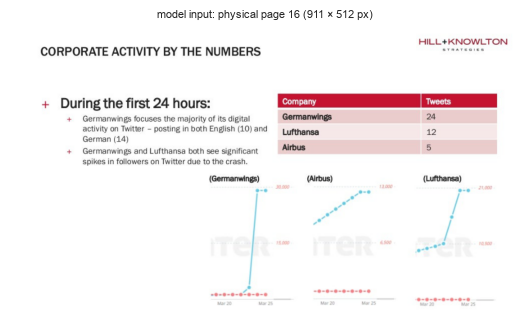

text condition, page 16: hill+knowlton corporate activity by the numbers roane nee + during the first 24 hours: + germanwings focuses the majority of its digital germanwings 24 activity on twitter - posting in both english (10) and lufthansa 42 german (14) + germanwings and lufthansa both see significant airbus 5 spikes in 


**mmlb-0033** · `earlybird-110722143746-phpapp02_95.pdf` · format `Int` · sources ['Chart', 'Table']

**Question:** How many more millions of dollars was the median exit valuation in the USA compared to Europe at the time of the presentation?

**Reference:** `63` · **evidence pages:** [6]

- **A. text, retrieved:** `63` (score 1.00) · cited [6] · supplied [6, 27, 2, 26, 30]

- **B. images, retrieved:** `64` (score 0.00) · cited [6] · supplied [6, 27, 2, 26, 30]

- **C. text, oracle:** `63` (score 1.00) · cited [6] · supplied [6, 27, 2, 26, 30]

- **D. images, oracle:** `64` (score 0.00) · cited [6] · supplied [6, 27, 2, 26, 30]

**Manual review:** visual reading — Image answer 64 instead of 63 = $236M − $173M: the two values sit in a small highlighted table at 683 x 512 px; the OCR text carried both numbers and the text model was right.

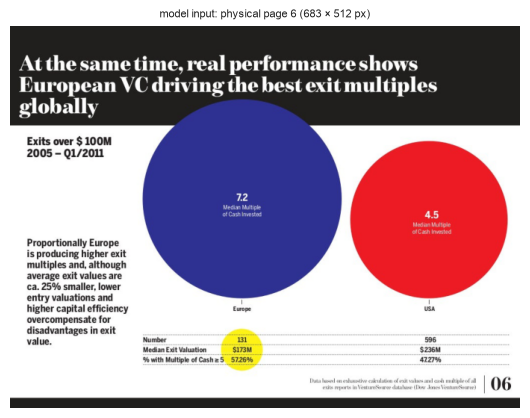

text condition, page 6: at the same time,e real performancegg shows european vca | drivingee the best exito multiplese globally exits over $ 100m 2005 - q1/2011 7.2 median multiple of cash invested 45 median multiple of cash invested proportionally europe is producing higher exit multiples and, although average exit values


In [16]:
def show_case(qid, max_pages=2):
    # Question, reference and every prediction; then the evidence pages as the image model saw them, with the text the text model got.
    row = reference.loc[qid]
    lines = [f"**{qid}** · `{row['doc_id']}` · format `{row['answer_format']}` · sources {row['evidence_sources']}",
             f"**Question:** {row['question']}", f"**Reference:** `{row['answer']}` · **evidence pages:** {row['evidence_pages']}"]
    for name in "ABCD":
        match = scored[name][scored[name]["qid"] == qid]
        if len(match):
            r = match.iloc[0]
            lines.append(f"- **{LABELS[name]}:** `{r['pred']}` (score {r['score']:.2f}) · cited {r['cited_pages']} · supplied {r['supplied_pages']}")
    if qid in MANUAL_REVIEW:
        lines.append(f"**Manual review:** {MANUAL_REVIEW[qid][0]} — {MANUAL_REVIEW[qid][1]}")
    display(Markdown("\n\n".join(lines)))
    shown = list(row["evidence_pages"])[:max_pages]
    fig, axes = plt.subplots(1, len(shown), figsize=(5.4 * len(shown), 4.6), squeeze=False)
    for ax, page_number in zip(axes[0], shown):
        pixmap = pymupdf.Pixmap(model_png(row["doc_id"], page_number))
        ax.imshow(np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.height, pixmap.width, pixmap.n))
        ax.set_title(f"model input: physical page {page_number} ({pixmap.width} × {pixmap.height} px)", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    for page_number in shown:
        print(f"text condition, page {page_number}: {normalize_text(page_lookup.loc[(row['doc_id'], page_number), 'text'])[:300]}")


# One fix by images (an OCR digit error) and one break (a small table at slide resolution), chosen from the manual review.
for qid in ("mmlb-0729", "mmlb-0033"):
    show_case(qid)

## 9. Cost and tokens

Tokens are the `usage` the API returned for each reply; cost uses the assumed list prices. Image replies served from the response cache in the original run were paid once (when first sent), so "live cost" is what the run actually spent.

In [17]:
def usage(name):
    frame = pd.DataFrame([r for r in records[name] if r["status"] in ("ok", "parse_error")])
    source = frame["source"] if "source" in frame else pd.Series(None, index=frame.index, dtype=object)
    live = frame[source.fillna("live") == "live"]  # the text runs had no cache and predate the 'source' field: all live
    cost = lambda f: (f["prompt_tokens"].sum() * PRICES["input"] + f["completion_tokens"].sum() * PRICES["output"]) / 1e6
    return {"replies": len(frame), "live / cached replies": f"{len(live)} / {len(frame) - len(live)}",
            "prompt tokens per reply (median)": int(frame["prompt_tokens"].median()), "prompt tokens (total)": int(frame["prompt_tokens"].sum()),
            "completion tokens (total)": int(frame["completion_tokens"].sum()), "cost of all replies (USD)": round(cost(frame), 4),
            "live cost (USD)": round(cost(live), 4), "accuracy on answerable": round(answerable(scored[name])["score"].mean(), 3)}


cost_table = pd.DataFrame({LABELS[n]: usage(n) for n in "ABCD"})
ratio = cost_table.loc["prompt tokens (total)", LABELS["B"]] / cost_table.loc["prompt tokens (total)", LABELS["A"]]
print(f"Images use {ratio:.1f}× the prompt tokens of text on the same 57 questions and pages.")
cost_table

Images use 37.5× the prompt tokens of text on the same 57 questions and pages.


,"A. text, retrieved","B. images, retrieved","C. text, oracle","D. images, oracle"
replies,57,57,40,38
live / cached replies,57 / 0,52 / 5,40 / 0,13 / 25
prompt tokens per reply (median),1484,71035,1510,71036
prompt tokens (total),107988,4049223,73170,2699537
completion tokens (total),1191,1254,903,846
cost of all replies (USD),0.0169,0.6081,0.0115,0.4054
live cost (USD),0.0169,0.5548,0.0115,0.1387
accuracy on answerable,0.175,0.175,0.225,0.289


## 10. Hypotheses

In [18]:
def hypothesis_status(name, statement, by_evidence=False):
    # Observed direction only: 40 clustered questions cannot confirm a hypothesis.
    paired = PAIRED[name]
    if by_evidence:
        gains = paired.groupby("evidence_group")["score_diff"].mean()
        difference = gains.get("chart or figure", np.nan) - gains.get("text, layout or table only", np.nan)
        evidence = f"gain chart/figure {gains.get('chart or figure', np.nan):+.3f} vs text-only {gains.get('text, layout or table only', np.nan):+.3f}"
    else:
        s = paired_summary(paired)
        difference = s["difference B − A"]
        evidence = (f"{s['accuracy A']:.3f} → {s['accuracy B']:.3f}; fixed {s['fixed (A wrong → B right)']}, broken {s['broken (A right → B wrong)']}; "
                    f"McNemar p {s['exact McNemar p (ignores clustering)']:.2f}; documents better/worse/equal {s['documents better / worse / equal']}")
    status = "direction consistent (exploratory)" if difference > 0 else "direction NOT consistent" if difference < 0 else "no difference observed"
    return {"hypothesis": statement, "evidence": evidence, "status": status}


hypotheses = pd.DataFrame([
    hypothesis_status("1. retrieved pages: text → images (answerable)", "H1: images > text on the same retrieved pages"),
    hypothesis_status("1. retrieved pages: text → images (answerable)", "H2: image gain larger on chart/figure than on text-only questions", by_evidence=True),
    hypothesis_status("2. oracle pages: text → images", "H3: images > text on the oracle pages"),
])
with pd.option_context("display.max_colwidth", 150):
    display(hypotheses)

,hypothesis,evidence,status
0,H1: images > text on the same retrieved pages,"0.175 → 0.175; fixed 3, broken 3; McNemar p 1.00; documents better/worse/equal 1 / 3 / 2",no difference observed
1,H2: image gain larger on chart/figure than on text-only questions,gain chart/figure +0.000 vs text-only +0.000,no difference observed
2,H3: images > text on the oracle pages,"0.237 → 0.289; fixed 6, broken 4; McNemar p 0.75; documents better/worse/equal 2 / 3 / 1",direction consistent (exploratory)


## 11. E1 resolution experiment

E1 is scored only from an immutable run directory produced by 02. By default this is the frozen copy of the full run in `experiments/frozen/e1/` (byte-identical to the original, see its `SHA256SUMS`); `VISUALDOC_E1_RUN_DIR` selects another saved run. The primary outcome is the **paired answer-accuracy difference** for `main_r1`; mean benchmark-score difference is secondary. Full mode also requires `control_r2`, an independent 512-px repeat on the same questions, so observed resolution gain can be compared with run-to-run variability.

The uncertainty interval resamples whole documents, preserving within-document clustering. With only six document clusters it is descriptive and unstable, not a confirmatory confidence statement. The notebook therefore also reports every document and leave-one-document-out sensitivity. The exact McNemar p-value is a familiar paired diagnostic but ignores document clustering.

The pre-specified visual-reading subgroup is loaded by question ID from the frozen spec. Pilot responses validate technical feasibility only: they are parsed and integrity-checked, but no accuracy-improvement table or figure is produced.

Latency uses live API time (or its recorded cache origin) and never cache lookup time. Citation validity is conditioned on making a citation, avoiding the vacuous value of empty citation lists. Token counts validate billing-accounting expectations only; they do not reveal the model's internal visual resolution.

,condition,label,eligible_questions,matched_questions,matched_mean_estimated_input_tokens,matched_max_estimated_input_tokens
0,E1_512,512 px control,40,37,21629.0,42691
1,E1_768,768 px treatment,40,37,45829.0,110695


,calls,estimated_input_tokens,cost_upper_usd
mode,,,
full,113,3336272,0.5276
pilot,18,558618,0.0881
smoke,2,40040,0.0065


Offline E1 readiness: 37/40 matched questions; documented exclusions {'mmlb-0035': 13, 'mmlb-0036': 5, 'mmlb-0039': 10}. Feasibility and cost are not model-performance results.


Mocked E1 evaluation interface, synthetic control flips and decision boundaries passed (not project results).


,full saved-run execution
planned_calls,113
successful_calls,113
prompt_tokens,3336385
completion_tokens,2355
cached_prompt_tokens,364800
observed_token_list_cost_usd,0.501871
mean_live_api_latency_s,1.605566
served_models,[gpt-4o-mini-2024-07-18]
system_fingerprints,[fp_9483e83037]
truncated_responses,0


,questions,documents,correct,answer_accuracy,mean_answer_score,false_abstention_rate,citation_coverage,citation_validity_given_citation,evidence_citation_rate,mean_input_tokens,mean_output_tokens,mean_cost_upper_usd,total_cost_upper_usd,mean_recorded_live_api_latency_s,live_calls,cache_hits
condition,,,,,,,,,,,,,,,,
main_512,37,6,10,0.2703,0.2703,0.0,0.973,0.9444,0.9459,21630.2432,20.9730,0.0033,0.1205,1.4595,37,0
main_768,37,6,16,0.4324,0.4247,0.0,1.000,0.8919,0.9459,45829.8649,21.0000,0.0069,0.2548,1.9464,37,0
control_r2,37,6,11,0.2973,0.2973,0.0,0.973,0.9444,0.9459,21630.2432,20.7027,0.0033,0.1205,1.4025,37,0


... (2 outputs left out)

,questions,correct_512,correct_768,accuracy_512,accuracy_768,accuracy_difference,mean_score_difference
doc_id,,,,,,,
2210.02442v1.pdf,6,0,0,0.0000,0.0000,0.0000,0.0000
PG_2020.05.21_International-Cooperation-CO,7,2,3,0.2857,0.4286,0.1429,0.1429
bdf54dxa.pdf,5,0,1,0.0000,0.2000,0.2000,0.2000
earlybird-110722143746-phpapp02_95.pdf,4,1,2,0.2500,0.5000,0.2500,0.2500
germanwingsdigitalcrisisanalysis-150403064,11,5,6,0.4545,0.5455,0.0909,0.0909
watch_d.pdf,4,2,4,0.5000,1.0000,0.5000,0.4286


,predefined visual-reading subgroup
predefined_qids,"[mmlb-0033, mmlb-0095, mmlb-0096, mmlb-0313, mmlb-0315, ..."
questions,9
paired_accuracy_difference,0.444444
selected_mechanism_subgroup_not_generalizable,True


,predefined accuracy-cost decision
verdict,adopt_768_for_this_model_and_population
criteria,"{'accuracy_gain': True, 'exceeds_control_correctness_cha..."
observed_mean_input_token_ratio_descriptive_only,2.118786
observed_incremental_cost_per_additional_correct_answer_usd,0.022385
rule,"{'status': 'engineering adoption rule, not a confirmator..."


Existing E1 figures preserved; rerun did not overwrite them.


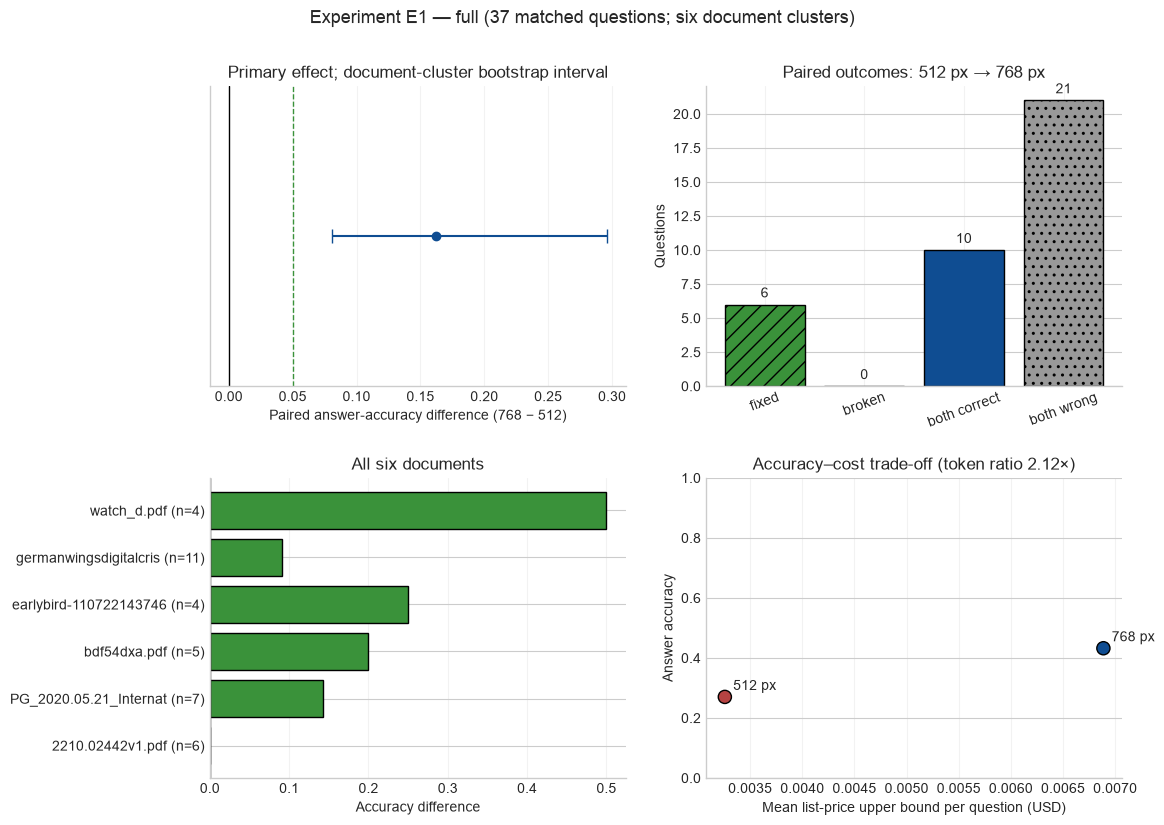

E1 evaluation saved or verified at /Users/macbookair/Documents/ENSAE/side project/Multimodal-Document-Intelligence/experiments/frozen/e1/run_20261121T131525011829Z_29c92c8a_full/evaluation_summary.json


In [19]:
E1_DIR = PROCESSED_DIR / "e1"
for required in ("design.json", "request_estimates.csv", "cost_plan.csv"):
    assert (E1_DIR / required).is_file(), f"{required} missing: run notebook 02 in offline mode first"
e1_design = json.loads((E1_DIR / "design.json").read_text())
e1_estimates = pd.read_csv(E1_DIR / "request_estimates.csv")
e1_cost_plan = pd.read_csv(E1_DIR / "cost_plan.csv")
e1_spec_path = PROJECT_ROOT / "experiments" / "specs" / "e1_image_resolution_v1.json"
e1_spec_bytes = e1_spec_path.read_bytes()
e1_spec = json.loads(e1_spec_bytes)
e1_spec_sha256 = hashlib.sha256(e1_spec_bytes).hexdigest()
assert e1_design["spec_sha256"] == e1_spec_sha256

e1_offline = e1_estimates.groupby(["condition", "label"]).agg(
    eligible_questions=("qid", "size"), matched_questions=("matched_feasible", "sum"),
    matched_mean_estimated_input_tokens=("prompt_tokens", lambda values: values[e1_estimates.loc[values.index, "matched_feasible"]].mean()),
    matched_max_estimated_input_tokens=("prompt_tokens", lambda values: values[e1_estimates.loc[values.index, "matched_feasible"]].max()),
).reset_index()
display(e1_offline.round({"matched_mean_estimated_input_tokens": 0}))
e1_mode_costs = e1_cost_plan.groupby("mode").agg(calls=("calls", "sum"),
    estimated_input_tokens=("estimated_input_tokens", "sum"), cost_upper_usd=("cost_upper_usd", "sum"))
display(e1_mode_costs.round({"cost_upper_usd": 4}))
print(f"Offline E1 readiness: {e1_design['matched_feasible_questions']}/{e1_design['questions_total']} matched questions; "
      f"documented exclusions {e1_design['excluded_context_qids']}. Feasibility and cost are not model-performance results.")

# Interface test only: mocked E1 responses exercise scoring and a one-to-one paired merge.
mock_qid = e1_spec['technical_smoke']['qid']
mock_source = next(record for record in records['D'] if record['qid'] == mock_qid).copy()
mock_pages = reference.loc[mock_qid, 'evidence_pages']
mock_512 = {**mock_source, 'status': 'ok', 'pred': 'Not answerable', 'cited_pages': [], 'supplied_pages': mock_pages}
mock_768 = {**mock_source, 'status': 'ok', 'pred': reference.loc[mock_qid, 'answer'],
            'cited_pages': mock_pages[:1], 'supplied_pages': mock_pages}
mock_control = score_condition([mock_512])
mock_treatment = score_condition([mock_768])
mock_pair = mock_control[['qid', 'correct']].rename(columns={'correct': 'correct_512'}).merge(
    mock_treatment[['qid', 'correct']].rename(columns={'correct': 'correct_768'}), on='qid', validate='one_to_one')
assert len(mock_pair) == 1 and not mock_pair.loc[0, 'correct_512'] and mock_pair.loc[0, 'correct_768']


def apply_e1_decision(accuracy_gain, control_change_rate, incremental_cost_per_correct, rules):
    criteria = {
        "accuracy_gain": accuracy_gain >= rules["minimum_primary_accuracy_gain"],
        "exceeds_control_correctness_change_rate": accuracy_gain > control_change_rate,
        "incremental_cost_per_additional_correct": (
            incremental_cost_per_correct <= rules["maximum_incremental_cost_per_additional_correct_answer_usd"]),
    }
    if all(criteria.values()):
        verdict = "adopt_768_for_this_model_and_population"
    elif accuracy_gain <= 0:
        verdict = "retain_512"
    else:
        verdict = "inconclusive"
    return {"verdict": verdict, "criteria": criteria}


# Synthetic boundary checks validate the predeclared rule without using E1 outcomes.
rules = e1_spec["decision_rule"]
synthetic_decisions = {
    "adopt": apply_e1_decision(3 / 37, 1 / 37, 0.08, rules),
    "retain": apply_e1_decision(0.0, 1 / 37, np.inf, rules),
    "inconclusive": apply_e1_decision(2 / 37, 2 / 37, 0.08, rules),
}
assert {name: result["verdict"] for name, result in synthetic_decisions.items()} == {
    "adopt": "adopt_768_for_this_model_and_population",
    "retain": "retain_512",
    "inconclusive": "inconclusive",
}
# Synthetic correctness flips exercise the exact fixed/broken/change-rate arithmetic used by the full control repeat.
synthetic_control = pd.DataFrame({
    "correct_r1": [False, True, False, True, False],
    "correct_r2": [True, False, True, True, False],
})
synthetic_fixed = int((~synthetic_control["correct_r1"] & synthetic_control["correct_r2"]).sum())
synthetic_broken = int((synthetic_control["correct_r1"] & ~synthetic_control["correct_r2"]).sum())
synthetic_changed = synthetic_fixed + synthetic_broken
assert (synthetic_fixed, synthetic_broken, synthetic_changed) == (2, 1, 3)
assert np.isclose(synthetic_changed / len(synthetic_control), 0.6)
assert np.isclose((synthetic_fixed - synthetic_broken) / len(synthetic_control), 0.2)
print('Mocked E1 evaluation interface, synthetic control flips and decision boundaries passed (not project results).')

FROZEN_E1_DIR = PROJECT_ROOT / "experiments" / "frozen" / "e1"
FROZEN_E1_RUN = FROZEN_E1_DIR / "run_20261121T131525011829Z_29c92c8a_full"
e1_run_value = os.getenv("VISUALDOC_E1_RUN_DIR", "").strip() or str(FROZEN_E1_RUN)
e1_results = None
if not (PROJECT_ROOT / e1_run_value).is_dir():  # an absolute value replaces PROJECT_ROOT
    raise FileNotFoundError(f"E1 run directory not found: {e1_run_value}. Restore experiments/frozen/e1/ from git or set VISUALDOC_E1_RUN_DIR.")
else:
    e1_run_dir = Path(e1_run_value)
    if not e1_run_dir.is_absolute():
        e1_run_dir = PROJECT_ROOT / e1_run_dir
    assert e1_run_dir.is_dir(), f"E1 run directory not found: {e1_run_dir}"
    e1_settings = json.loads((e1_run_dir / "settings.json").read_text())
    e1_completion = json.loads((e1_run_dir / "completion.json").read_text())
    e1_spec_snapshot_bytes = (e1_run_dir / "spec_snapshot.json").read_bytes()
    e1_plan = json.loads((e1_run_dir / "execution_plan.json").read_text())
    e1_log = read_jsonl(e1_run_dir / "execution_log.jsonl")
    e1_smoke_gate = json.loads((e1_run_dir / "smoke_gate.json").read_text())

    assert e1_settings["spec_sha256"] == e1_spec_sha256 and e1_settings["spec_id"] == e1_spec["spec_id"]
    assert hashlib.sha256(e1_spec_snapshot_bytes).hexdigest() == e1_spec_sha256
    assert e1_settings["model"] == prediction_manifest["model"] == e1_spec["model"]["requested_snapshot"]
    assert e1_settings["image_prompt_hash"] == prediction_manifest["image_prompt_hash"] == e1_spec["model"]["image_prompt_hash"]
    assert e1_settings["temperature"] == 0.0 and e1_settings["max_output_tokens"] == 400
    assert e1_smoke_gate["passed"] and e1_completion["smoke_gate_passed"], "Essential smoke verification failed; empirical results are blocked"
    assert len(e1_log) == len(e1_plan), "Execution log is incomplete"
    assert [record["execution_index"] for record in e1_log] == [item["execution_index"] for item in e1_plan]
    assert sum(int(record.get("attempts", 0)) for record in e1_log) <= e1_settings["max_api_attempts"]
    assert all(record.get("request_images_verified") and record.get("token_accounting", {}).get("ok") for record in e1_log), (
        "Every saved response must retain verified image bytes and passing token accounting")
    assert all(record.get("response_valid") for record in e1_log), (
        "Every saved response must pass model, parsing, completeness, image and token checks")
    assert all(record["cache_provenance"]["namespace"] == f"{e1_settings['run_id']}:{record['replicate_id']}" for record in e1_log)

    mode = e1_settings["mode"]
    run_usage = {
        "planned_calls": len(e1_plan),
        "successful_calls": sum(record["status"] == "ok" for record in e1_log),
        "prompt_tokens": int(sum(record.get("prompt_tokens") or 0 for record in e1_log)),
        "completion_tokens": int(sum(record.get("completion_tokens") or 0 for record in e1_log)),
        "cached_prompt_tokens": int(sum(record.get("cached_prompt_tokens") or 0 for record in e1_log)),
        "observed_token_list_cost_usd": float((
            sum(record.get("prompt_tokens") or 0 for record in e1_log) * PRICES["input"] +
            sum(record.get("completion_tokens") or 0 for record in e1_log) * PRICES["output"]) / 1e6),
        "mean_live_api_latency_s": float(np.mean([record["api_latency_s"] for record in e1_log if record.get("api_latency_s") is not None])),
        "served_models": sorted({record.get("served_model") for record in e1_log}),
        "system_fingerprints": sorted({record.get("system_fingerprint") for record in e1_log if record.get("system_fingerprint")}),
        "truncated_responses": sum(record.get("finish_reason") != "stop" for record in e1_log),
        "unparseable_responses": sum(record.get("status") == "parse_error" for record in e1_log),
    }
    display(pd.Series(run_usage, name="full saved-run execution").to_frame())
    if mode == "smoke":
        display(pd.DataFrame([{"condition": record["condition"], "status": record["status"],
                               "expected_prompt_tokens": record["token_accounting"]["expected_prompt_tokens"],
                               "observed_prompt_tokens": record["token_accounting"]["observed_prompt_tokens"],
                               "served_model": record["served_model"], "system_fingerprint": record.get("system_fingerprint")}
                              for record in e1_log]))
        e1_results = {"mode": "smoke", "technical_gate_passed": True, "performance_reported": False}
    else:
        def load_e1_predictions(replicate_id, condition):
            path = e1_run_dir / f"predictions_{replicate_id}_{condition}.jsonl"
            assert path.is_file(), f"Missing expected output: {path.name}"
            return read_jsonl(path)

        e1_records = {
            "main_512": load_e1_predictions("main_r1", "E1_512"),
            "main_768": load_e1_predictions("main_r1", "E1_768"),
        }
        if mode == "full":
            e1_records["control_r2"] = load_e1_predictions("control_r2", "E1_512")
        assert all(record["status"] in {"ok", "parse_error"} for values in e1_records.values() for record in values)
        assert [record["qid"] for record in e1_records["main_512"]] == [record["qid"] for record in e1_records["main_768"]]
        expected_qids = e1_spec["pilot"]["qids"] if mode == "pilot" else e1_spec["population"]["matched_qids"]
        assert set(record["qid"] for record in e1_records["main_512"]) == set(expected_qids)
        if mode == "full":
            assert set(record["qid"] for record in e1_records["control_r2"]) == set(expected_qids)
            assert len(e1_records["control_r2"]) == len(expected_qids)
        for control_record in e1_records["main_512"]:
            treatment_record = next(record for record in e1_records["main_768"] if record["qid"] == control_record["qid"])
            expected_pages = reference.loc[control_record["qid"], "evidence_pages"]
            assert control_record["supplied_pages"] == treatment_record["supplied_pages"] == expected_pages
            assert control_record["image_sha256"] != treatment_record["image_sha256"]
            assert control_record["requested_model"] == treatment_record["requested_model"] == e1_settings["model"]
        if mode == "full":
            for repeat_record in e1_records["control_r2"]:
                main_record = next(record for record in e1_records["main_512"] if record["qid"] == repeat_record["qid"])
                assert repeat_record["supplied_pages"] == main_record["supplied_pages"]
                assert repeat_record["image_sha256"] == main_record["image_sha256"]
                assert repeat_record["requested_model"] == main_record["requested_model"] == e1_settings["model"]

        main_log = [record for record in e1_log if record["replicate_id"] == "main_r1"]
        for offset in range(0, len(main_log), 2):
            pair = main_log[offset:offset + 2]
            assert len(pair) == 2 and pair[0]["qid"] == pair[1]["qid"]
            assert {record["condition"] for record in pair} == {"E1_512", "E1_768"}
            assert [record["within_pair_order"] for record in pair] == [1, 2]

        e1_scored = {name: score_condition(values) for name, values in e1_records.items()}
        control = e1_scored["main_512"]
        treatment = e1_scored["main_768"]
        e1_pair = control[["qid", "doc_id", "evidence_group", "score", "correct"]].rename(
            columns={"score": "score_512", "correct": "correct_512"}).merge(
            treatment[["qid", "score", "correct"]].rename(columns={"score": "score_768", "correct": "correct_768"}),
            on="qid", validate="one_to_one")
        e1_pair["accuracy_diff"] = e1_pair["correct_768"].astype(float) - e1_pair["correct_512"].astype(float)
        e1_pair["score_diff"] = e1_pair["score_768"] - e1_pair["score_512"]
        e1_pair["transition"] = np.select(
            [~e1_pair["correct_512"] & e1_pair["correct_768"], e1_pair["correct_512"] & ~e1_pair["correct_768"],
             e1_pair["correct_512"] & e1_pair["correct_768"]],
            ["fixed", "broken", "both correct"], "both wrong")

        def document_cluster_ci(frame, value_column):
            groups = [group[value_column].to_numpy(dtype=float) for _, group in frame.groupby("doc_id")]
            rng = np.random.default_rng(e1_spec["uncertainty"]["bootstrap_seed"])
            draws = e1_spec["uncertainty"]["bootstrap_draws"]
            boot = np.empty(draws)
            for draw in range(draws):
                chosen = rng.integers(0, len(groups), size=len(groups))
                boot[draw] = np.concatenate([groups[index] for index in chosen]).mean()
            return tuple(np.quantile(boot, [0.025, 0.975]))

        def leave_one_document_out(frame, value_column):
            return {doc_id: frame.loc[frame["doc_id"] != doc_id, value_column].mean()
                    for doc_id in e1_spec["population"]["documents"]}

        transitions = e1_pair["transition"].value_counts().reindex(
            ["fixed", "broken", "both correct", "both wrong"], fill_value=0)
        fixed, broken = int(transitions["fixed"]), int(transitions["broken"])
        primary = {
            "questions": len(e1_pair), "documents": e1_pair["doc_id"].nunique(),
            "paired_answer_accuracy_difference": e1_pair["accuracy_diff"].mean(),
            "paired_net_additional_correct_answers": fixed - broken,
            "paired_correctness_changed_questions": fixed + broken,
            "paired_correctness_changed_percentage": 100 * (fixed + broken) / len(e1_pair),
            "document_cluster_bootstrap_95_interval": document_cluster_ci(e1_pair, "accuracy_diff"),
            "leave_one_document_out": leave_one_document_out(e1_pair, "accuracy_diff"),
            "fixed": fixed, "broken": broken,
            "exact_mcnemar_p_ignores_clustering": mcnemar_exact_p(fixed, broken),
        }
        secondary = {
            "paired_mean_benchmark_score_difference": e1_pair["score_diff"].mean(),
            "document_cluster_bootstrap_95_interval": document_cluster_ci(e1_pair, "score_diff"),
        }

        if mode == "pilot":
            technical_summary = pd.DataFrame([{
                "condition": name, "records": len(frame), "parsed_successfully": int((frame["status"] == "ok").sum()),
                "parse_errors": int((frame["status"] == "parse_error").sum()),
                "truncated_or_incomplete": sum(record.get("finish_reason") != "stop" for record in e1_records[name]),
                "served_model_mismatches": sum(record.get("served_model") != e1_settings["model"] for record in e1_records[name]),
                "token_accounting_failures": sum(not record.get("token_accounting", {}).get("ok", False) for record in e1_records[name]),
                "image_verification_failures": sum(not record.get("request_images_verified", False) for record in e1_records[name]),
                "documents_represented": frame["doc_id"].nunique(),
                "live_calls": sum(record["source"] == "live" for record in e1_records[name]),
                "cache_hits": sum(record["source"] == "cache" for record in e1_records[name]),
            } for name, frame in e1_scored.items()])
            display(technical_summary)
            display(Markdown("**Pilot gate passed. Accuracy effects are deliberately suppressed: these eight selected questions validate technical feasibility, not statistical improvement.**"))
            e1_results = {"mode": "pilot", "technical_gate_passed": True, "performance_reported": False,
                          "records": technical_summary.to_dict(orient="records")}
        else:
            repeat = e1_scored["control_r2"]
            repeat_pair = control[["qid", "doc_id", "correct", "score"]].rename(
                columns={"correct": "correct_r1", "score": "score_r1"}).merge(
                repeat[["qid", "correct", "score"]].rename(columns={"correct": "correct_r2", "score": "score_r2"}),
                on="qid", validate="one_to_one")
            repeat_pair["accuracy_diff"] = repeat_pair["correct_r2"].astype(float) - repeat_pair["correct_r1"].astype(float)
            repeat_pair["transition"] = np.select(
                [~repeat_pair["correct_r1"] & repeat_pair["correct_r2"],
                 repeat_pair["correct_r1"] & ~repeat_pair["correct_r2"],
                 repeat_pair["correct_r1"] & repeat_pair["correct_r2"]],
                ["fixed", "broken", "both correct"], "both wrong")
            repeat_transitions = repeat_pair["transition"].value_counts().reindex(
                ["fixed", "broken", "both correct", "both wrong"], fill_value=0)
            control_fixed = int(repeat_transitions["fixed"])
            control_broken = int(repeat_transitions["broken"])
            control_changed = control_fixed + control_broken
            repeated_control = {
                "questions": len(repeat_pair),
                "correctness_changed_questions": control_changed,
                "correctness_changed_percentage": 100 * control_changed / len(repeat_pair),
                "correctness_change_rate_for_decision": control_changed / len(repeat_pair),
                "fixed_main_r1_wrong_control_r2_correct": control_fixed,
                "broken_main_r1_correct_control_r2_wrong": control_broken,
                "net_additional_correct_r2_minus_r1": control_fixed - control_broken,
                "net_accuracy_difference_r2_minus_r1": repeat_pair["accuracy_diff"].mean(),
                "interpretation": "Observed sensitivity margin from two replicates; not a precise stochastic-uncertainty estimate.",
            }

            metric_rows = []
            for name, frame in e1_scored.items():
                source_records = e1_records[name]
                aligned = frame.set_index("qid")
                # Conservative list-price bound: server-side cached-token discounts, if any, are not assumed.
                aligned["inference_cost_upper_usd"] = (aligned["prompt_tokens"] * PRICES["input"] + aligned["completion_tokens"] * PRICES["output"]) / 1e6
                cited = frame[frame["cited_pages"].map(bool)]
                origin_latencies = [record.get("api_latency_s") if record["source"] == "live" else record.get("origin_api_latency_s")
                                    for record in source_records]
                metric_rows.append({
                    "condition": name, "questions": len(frame), "documents": frame["doc_id"].nunique(),
                    "correct": int(frame["correct"].sum()), "answer_accuracy": frame["correct"].mean(),
                    "mean_answer_score": frame["score"].mean(), "false_abstention_rate": frame["predicted_unanswerable"].mean(),
                    "citation_coverage": frame["cited_pages"].map(bool).mean(),
                    "citation_validity_given_citation": cited["citations_valid"].mean() if len(cited) else np.nan,
                    "evidence_citation_rate": frame["cites_evidence"].astype(float).mean(),
                    "mean_input_tokens": aligned["prompt_tokens"].mean(), "mean_output_tokens": aligned["completion_tokens"].mean(),
                    "mean_cost_upper_usd": aligned["inference_cost_upper_usd"].mean(), "total_cost_upper_usd": aligned["inference_cost_upper_usd"].sum(),
                    "mean_recorded_live_api_latency_s": float(np.mean([value for value in origin_latencies if value is not None])),
                    "live_calls": sum(record["source"] == "live" for record in source_records),
                    "cache_hits": sum(record["source"] == "cache" for record in source_records),
                })
            e1_metrics = pd.DataFrame(metric_rows).set_index("condition")

            by_document = e1_pair.groupby("doc_id").agg(
                questions=("qid", "size"), correct_512=("correct_512", "sum"), correct_768=("correct_768", "sum"),
                accuracy_512=("correct_512", "mean"), accuracy_768=("correct_768", "mean"),
                accuracy_difference=("accuracy_diff", "mean"), mean_score_difference=("score_diff", "mean"))
            by_document = by_document.reindex(e1_spec["population"]["documents"])
            by_document["questions"] = by_document["questions"].fillna(0).astype(int)

            subgroup_qids = set(e1_spec["visual_reading_subgroup"]["qids"])
            visual_subgroup = e1_pair[e1_pair["qid"].isin(subgroup_qids)]
            subgroup_summary = {
                "predefined_qids": e1_spec["visual_reading_subgroup"]["qids"],
                "questions": len(visual_subgroup), "paired_accuracy_difference": visual_subgroup["accuracy_diff"].mean(),
                "selected_mechanism_subgroup_not_generalizable": True,
            }

            rules = e1_spec["decision_rule"]
            token_ratio = e1_metrics.loc["main_768", "mean_input_tokens"] / e1_metrics.loc["main_512", "mean_input_tokens"]
            additional_correct = int(e1_metrics.loc["main_768", "correct"] - e1_metrics.loc["main_512", "correct"])
            incremental_cost = e1_metrics.loc["main_768", "total_cost_upper_usd"] - e1_metrics.loc["main_512", "total_cost_upper_usd"]
            incremental_cost_per_correct = incremental_cost / additional_correct if additional_correct > 0 else np.inf
            decision = apply_e1_decision(
                primary["paired_answer_accuracy_difference"],
                repeated_control["correctness_change_rate_for_decision"],
                incremental_cost_per_correct, rules)
            decision.update({"observed_mean_input_token_ratio_descriptive_only": token_ratio,
                        "observed_incremental_cost_per_additional_correct_answer_usd": incremental_cost_per_correct,
                        "rule": rules})

            display(e1_metrics.round(4))
            display(pd.Series(primary, name="primary: paired 768 - 512").to_frame())
            display(pd.Series(repeated_control, name="run-to-run control variability").to_frame())
            display(by_document.round(4).rename(index=lambda value: value[:42]))
            display(pd.Series(subgroup_summary, name="predefined visual-reading subgroup").to_frame())
            display(pd.Series(decision, name="predefined accuracy-cost decision").to_frame())

            PALETTE = {"control": "#B64342", "treatment": "#0F4D92", "gain": "#3A923A", "loss": "#CC6677", "neutral": "#999999"}
            plt.rcParams.update({"font.family": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"], "font.size": 10,
                                 "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                                 "svg.fonttype": "none"})
            fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
            estimate = primary["paired_answer_accuracy_difference"]
            interval = primary["document_cluster_bootstrap_95_interval"]
            axes[0, 0].errorbar([estimate], [0], xerr=[[estimate - interval[0]], [interval[1] - estimate]],
                                fmt="o", color=PALETTE["treatment"], capsize=5)
            axes[0, 0].axvline(0, color="black", linewidth=1)
            axes[0, 0].axvline(rules["minimum_primary_accuracy_gain"], color=PALETTE["gain"], linestyle="--", linewidth=1)
            axes[0, 0].set(xlabel="Paired answer-accuracy difference (768 − 512)", yticks=[],
                           title="Primary effect; document-cluster bootstrap interval")

            outcome_order = ["fixed", "broken", "both correct", "both wrong"]
            bars = axes[0, 1].bar(outcome_order, transitions[outcome_order],
                                  color=[PALETTE["gain"], PALETTE["loss"], PALETTE["treatment"], PALETTE["neutral"]],
                                  edgecolor="black", hatch=["//", "\\", "", ".."])
            axes[0, 1].bar_label(bars, padding=3)
            axes[0, 1].set(ylabel="Questions", title="Paired outcomes: 512 px → 768 px")
            axes[0, 1].tick_params(axis="x", rotation=20)

            doc_plot = by_document.reset_index()
            axes[1, 0].barh(np.arange(len(doc_plot)), doc_plot["accuracy_difference"], color=np.where(
                doc_plot["accuracy_difference"].fillna(0) >= 0, PALETTE["gain"], PALETTE["loss"]), edgecolor="black")
            axes[1, 0].axvline(0, color="black", linewidth=1)
            axes[1, 0].set_yticks(np.arange(len(doc_plot)), [f"{doc[:22]} (n={n})" for doc, n in zip(doc_plot["doc_id"], doc_plot["questions"])])
            axes[1, 0].set(xlabel="Accuracy difference", title="All six documents")

            axes[1, 1].scatter(e1_metrics.loc[["main_512", "main_768"], "mean_cost_upper_usd"],
                               e1_metrics.loc[["main_512", "main_768"], "answer_accuracy"],
                               s=90, c=[PALETTE["control"], PALETTE["treatment"]], edgecolor="black")
            for name in ("main_512", "main_768"):
                axes[1, 1].annotate(name.replace("main_", "") + " px", (e1_metrics.loc[name, "mean_cost_upper_usd"],
                    e1_metrics.loc[name, "answer_accuracy"]), xytext=(6, 5), textcoords="offset points")
            axes[1, 1].set(xlabel="Mean list-price upper bound per question (USD)", ylabel="Answer accuracy", ylim=(0, 1),
                           title=f"Accuracy–cost trade-off (token ratio {token_ratio:.2f}×)")
            for axis in axes.flat:
                axis.grid(axis="x", alpha=0.25)
            fig.suptitle(f"Experiment E1 — full ({len(e1_pair)} matched questions; six document clusters)", fontsize=13)
            fig.tight_layout(pad=2)
            figure_png = e1_run_dir / "e1_summary.png"
            figure_pdf = e1_run_dir / "e1_summary.pdf"
            if not figure_png.exists() and not figure_pdf.exists() and not e1_run_dir.resolve().is_relative_to(FROZEN_E1_DIR.resolve()):
                fig.savefig(figure_png, dpi=300, bbox_inches="tight")
                fig.savefig(figure_pdf, bbox_inches="tight")
            else:
                print("Existing E1 figures preserved; rerun did not overwrite them.")
            plt.show()

            e1_results = {
                "run_dir": str(e1_run_dir.relative_to(PROJECT_ROOT)) if e1_run_dir.is_relative_to(PROJECT_ROOT) else str(e1_run_dir),
                "mode": "full", "performance_reported": True, "execution": run_usage,
                "primary": primary, "secondary": secondary,
                "repeated_control": repeated_control, "metrics": e1_metrics.reset_index().to_dict(orient="records"),
                "transitions": transitions.to_dict(), "all_documents": by_document.reset_index().to_dict(orient="records"),
                "visual_reading_subgroup": subgroup_summary, "decision": decision,
                "uncertainty_qualification": e1_spec["uncertainty"]["qualification"],
            }

    if e1_results is not None:
        evaluation_path = e1_run_dir / "evaluation_summary.json"
        serialized = json.dumps(e1_results, indent=2, default=lambda value: value.item() if hasattr(value, "item") else value)
        if evaluation_path.exists():
            # run_dir records where the run was evaluated; the frozen copy lives elsewhere but must agree on everything else.
            saved_evaluation, new_evaluation = json.loads(evaluation_path.read_text()), json.loads(serialized)
            saved_evaluation.pop("run_dir", None), new_evaluation.pop("run_dir", None)
            assert saved_evaluation == new_evaluation, "Existing evaluation differs; refusing to overwrite"
        else:
            assert not e1_run_dir.resolve().is_relative_to(FROZEN_E1_DIR.resolve()), "experiments/frozen/ is never written to"
            evaluation_path.write_text(serialized)
        print("E1 evaluation saved or verified at", evaluation_path)

## 12. E1 integrity audit

The numbers above are only as good as the saved run. This section re-derives the run's bookkeeping from the raw files instead of trusting `completion.json`.

**Request fingerprint versus cache key.** A *request fingerprint* is the SHA-256 of the request with every image replaced by its hash: it identifies *what was asked*. Two identical requests share it, wherever and whenever they are sent. A *cache key* is $\mathrm{SHA256}(\text{run id} : \text{replicate id} : \text{fingerprint})$: it identifies *which answer slot* a reply fills. The repeated 512-px control sends exactly the same requests as `main_r1`, so its fingerprints must be equal while its cache keys must differ. Otherwise the "repeat" could silently reuse the first reply and the run-to-run variability would be zero by construction.

Checks: file checksums of the frozen copy; all 113 planned calls present exactly once in plan order; prediction files equal to their log records; cache keys recomputed; identical fingerprints but distinct cache keys between the two 512-px replicates; no cache hit; image hashes equal to the current render manifests; the frozen baseline unchanged. Fingerprints are also rebuilt from the images and prompt in 02 (offline mode), which owns request construction.

In [20]:
assert e1_results is not None and e1_results["mode"] == "full", "Sections 12-13 need a full E1 run"
E1_FIG_DIR = E1_DIR / "figures"
E1_FIG_DIR.mkdir(parents=True, exist_ok=True)
e1_run_id = e1_settings["run_id"]
E1_QIDS = e1_spec["population"]["matched_qids"]
E1_SOURCES = {"main_512": ("main_r1", "E1_512"), "main_768": ("main_r1", "E1_768"), "control_r2": ("control_r2", "E1_512")}
log_by_key = {(r["replicate_id"], r["qid"], r["condition"]): r for r in e1_log}
cache_entries = read_jsonl(e1_run_dir / "response_cache.jsonl")
cache_by_key = {entry["cache_key"]: entry for entry in cache_entries}
e1_manifests = {"E1_512": image_manifest,
                "E1_768": pd.read_csv(PROCESSED_DIR / "render_manifest_e1.csv").set_index(["doc_id", "page"])}


def verify_sha256sums(folder, prefix=""):
    lines = [line.split(maxsplit=1) for line in (folder / "SHA256SUMS").read_text().splitlines() if line.strip()]
    selected = [(digest, name) for digest, name in lines if name.startswith(prefix)]
    return len(selected) > 0 and all(hashlib.sha256((folder / name).read_bytes()).hexdigest() == digest for digest, name in selected)


def same_request(a, b):
    return log_by_key[a]["fingerprint"] == log_by_key[b]["fingerprint"]


def same_cache_key(a, b):
    return log_by_key[a]["cache_provenance"]["cache_key"] == log_by_key[b]["cache_provenance"]["cache_key"]


expected_composition = Counter({("technical_smoke", "E1_512"): 1, ("technical_smoke", "E1_768"): 1,
                                ("main_r1", "E1_512"): 37, ("main_r1", "E1_768"): 37, ("control_r2", "E1_512"): 37})
e1_audit = {
    "frozen copy matches its SHA256SUMS": (verify_sha256sums(FROZEN_E1_DIR, FROZEN_E1_RUN.name + "/")
                                           if e1_run_dir.resolve() == FROZEN_E1_RUN.resolve() else None),
    "113 planned calls: 2 smoke + 37 x 512 + 37 x 768 + 37 x 512 repeat": (
        len(e1_plan) == len(e1_log) == 113 and Counter((r["replicate_id"], r["condition"]) for r in e1_log) == expected_composition),
    "log follows the plan order exactly": all(
        all(r[k] == p[k] for k in ("replicate_id", "qid", "condition", "pair_index", "within_pair_order", "execution_index"))
        for r, p in zip(e1_log, e1_plan)),
    "no duplicated (replicate, question, condition)": len(log_by_key) == len(e1_log),
    "each replicate covers the 37 matched questions once": all(
        sorted(r["qid"] for r in e1_log if (r["replicate_id"], r["condition"]) == source) == sorted(E1_QIDS)
        for source in E1_SOURCES.values()),
    "all 113 live, one attempt, parsed, not truncated": all(
        r["source"] == "live" and r["attempts"] == 1 and r["status"] == "ok" and r["finish_reason"] == "stop" for r in e1_log),
    "prediction files equal their log records": all(
        e1_records[name] == [r for r in e1_log if (r["replicate_id"], r["condition"]) == source] for name, source in E1_SOURCES.items()),
    "cache key = SHA-256(run:replicate:fingerprint), all 113": all(
        hashlib.sha256(f"{e1_run_id}:{r['replicate_id']}:{r['fingerprint']}".encode()).hexdigest() == r["cache_provenance"]["cache_key"]
        for r in e1_log),
    "one cache entry per call, same reply and usage": len(cache_entries) == len(cache_by_key) == 113 and all(
        all(cache_by_key[r["cache_provenance"]["cache_key"]][field] == r[field]
            for field in ("raw_response", "prompt_tokens", "completion_tokens", "system_fingerprint", "fingerprint", "replicate_id"))
        for r in e1_log),
    "512 repeat: same fingerprint as main_r1 (37/37)": all(same_request(("main_r1", q, "E1_512"), ("control_r2", q, "E1_512")) for q in E1_QIDS),
    "512 repeat: different cache key from main_r1 (37/37)": not any(same_cache_key(("main_r1", q, "E1_512"), ("control_r2", q, "E1_512")) for q in E1_QIDS),
    "512 and 768 requests differ (37/37)": not any(same_request(("main_r1", q, "E1_512"), ("main_r1", q, "E1_768")) for q in E1_QIDS),
    "no reply reused from a cache": not any(r["cache_provenance"]["hit"] for r in e1_log),
    "logged image hashes equal the current render manifests": all(
        r["image_sha256"] == [e1_manifests[r["condition"]].loc[(r["doc_id"], page), "sha256"] for page in r["supplied_pages"]] for r in e1_log),
    "one served snapshot and one system fingerprint": len({r["served_model"] for r in e1_log}) == 1 and len({r["system_fingerprint"] for r in e1_log}) == 1,
    "frozen baseline A-D unchanged (SHA256SUMS)": verify_sha256sums(PROJECT_ROOT / "experiments" / "frozen" / "mmlongbench_doc"),
}
display(pd.Series(e1_audit, name="passed").to_frame())
assert all(value is not False for value in e1_audit.values()), "E1 integrity audit failed"
print(f"E1 integrity audit: {sum(v is True for v in e1_audit.values())} checks passed"
      + ("" if e1_audit["frozen copy matches its SHA256SUMS"] is not None else " (checksum check skipped: not the frozen copy)") + ".")

,passed
frozen copy matches its SHA256SUMS,True
113 planned calls: 2 smoke + 37 x 512 + 37 x 768 + 37 x 512 repeat,True
log follows the plan order exactly,True
"no duplicated (replicate, question, condition)",True
each replicate covers the 37 matched questions once,True
"all 113 live, one attempt, parsed, not truncated",True
prediction files equal their log records,True
"cache key = SHA-256(run:replicate:fingerprint), all 113",True
"one cache entry per call, same reply and usage",True
512 repeat: same fingerprint as main_r1 (37/37),True


E1 integrity audit: 16 checks passed.


**A limitation the audit exposes.** OpenAI caches long identical prompt prefixes on its side (`cached_prompt_tokens`). This is not our response cache, and it does not reuse replies. Below, the repeated control is split by whether the provider reported cached prompt tokens. If cached requests reproduce the first reply more often, the repeat measures run-to-run variability *with* provider caching, which may be a lower bound on cold-start variability. Cache use also coincides with a shorter delay since the first request, so the split is descriptive only.

In [21]:
variability_rows = []
for q in E1_QIDS:
    r1, r2, hi = (log_by_key[("main_r1", q, "E1_512")], log_by_key[("control_r2", q, "E1_512")], log_by_key[("main_r1", q, "E1_768")])
    variability_rows.append({
        "qid": q, "repeat_used_provider_prompt_cache": (r2["cached_prompt_tokens"] or 0) > 0,
        "repeat_minutes_after_run_1": (pd.Timestamp(r2["request_started_at"]) - pd.Timestamp(r1["request_completed_at"])).total_seconds() / 60,
        "repeat_reply_identical": r1["raw_response"] == r2["raw_response"], "repeat_answer_identical": r1["pred"] == r2["pred"],
        "768_reply_identical": r1["raw_response"] == hi["raw_response"], "768_answer_identical": r1["pred"] == hi["pred"],
    })
e1_variability = pd.DataFrame(variability_rows).set_index("qid")
display(e1_variability.groupby("repeat_used_provider_prompt_cache").agg(
    questions=("repeat_reply_identical", "size"), reply_identical=("repeat_reply_identical", "sum"),
    answer_identical=("repeat_answer_identical", "sum"), median_minutes_after_run_1=("repeat_minutes_after_run_1", "median")).round(1))
print("Total cached prompt tokens by replicate:",
      {f"{rep}/{cond}": int(sum((r["cached_prompt_tokens"] or 0) for r in e1_log if (r["replicate_id"], r["condition"]) == (rep, cond)))
       for rep, cond in sorted({(r["replicate_id"], r["condition"]) for r in e1_log})})

,questions,reply_identical,answer_identical,median_minutes_after_run_1
repeat_used_provider_prompt_cache,,,,
False,17,10,13,21.1
True,20,18,19,10.1


Total cached prompt tokens by replicate: {'control_r2/E1_512': 336000, 'main_r1/E1_512': 8704, 'main_r1/E1_768': 20096, 'technical_smoke/E1_512': 0, 'technical_smoke/E1_768': 0}


### Per-question table and regression references

One row per matched question with all three replies, scores, citations, tokens and latency. It is saved for the figures and frozen with the result package. The counts asserted below are the E1 regression references; a change must be explained, not silenced.

In [22]:
def e1_column(name, column):
    return e1_scored[name].set_index("qid").loc[E1_QIDS, column]


e1_table = pd.DataFrame({
    "doc_id": e1_column("main_512", "doc_id"),
    "visual_reading_subgroup": [q in set(e1_spec["visual_reading_subgroup"]["qids"]) for q in E1_QIDS],
    "answer_format": e1_column("main_512", "answer_format"), "reference": e1_column("main_512", "answer"),
    "evidence_pages": e1_column("main_512", "supplied_pages").map(json.dumps),
}, index=pd.Index(E1_QIDS, name="qid"))
for name, suffix in (("main_512", "512_r1"), ("control_r2", "512_r2"), ("main_768", "768_r1")):
    e1_table[f"pred_{suffix}"] = e1_column(name, "pred").map(json.dumps)
    e1_table[f"score_{suffix}"] = e1_column(name, "score").round(6)
    e1_table[f"correct_{suffix}"] = e1_column(name, "correct")
    e1_table[f"cited_{suffix}"] = e1_column(name, "cited_pages").map(json.dumps)
    e1_table[f"citation_valid_{suffix}"] = e1_column(name, "citations_valid")
    e1_table[f"input_tokens_{suffix}"] = e1_column(name, "prompt_tokens")
    e1_table[f"output_tokens_{suffix}"] = e1_column(name, "completion_tokens")
    e1_table[f"latency_s_{suffix}"] = e1_column(name, "api_latency_s")
e1_table["transition_512_to_768"] = e1_pair.set_index("qid").loc[E1_QIDS, "transition"]
e1_table["repeat_transition"] = repeat_pair.set_index("qid").loc[E1_QIDS, "transition"]
e1_table_csv = e1_table.to_csv()
(E1_DIR / "per_question.csv").write_text(e1_table_csv)
frozen_table = FROZEN_E1_DIR / "tables" / "per_question.csv"
if frozen_table.is_file() and e1_run_dir.resolve() == FROZEN_E1_RUN.resolve():
    assert frozen_table.read_text() == e1_table_csv, "Per-question table differs from the frozen package"

# E1 regression references (frozen full run 20261121T131525011829Z_29c92c8a).
assert [int(e1_table[f"correct_{s}"].sum()) for s in ("512_r1", "512_r2", "768_r1")] == [10, 11, 16]
assert e1_table["transition_512_to_768"].value_counts().to_dict() == {"both wrong": 21, "both correct": 10, "fixed": 6}
assert e1_table["repeat_transition"].value_counts().to_dict() == {"both wrong": 26, "both correct": 10, "fixed": 1}
assert decision["verdict"] == "adopt_768_for_this_model_and_population"
changed = e1_table[(e1_table["correct_512_r1"] != e1_table["correct_768_r1"]) | (e1_table["correct_512_r1"] != e1_table["correct_512_r2"])]
display(changed[["doc_id", "answer_format", "reference", "pred_512_r1", "pred_512_r2", "pred_768_r1", "score_768_r1",
                 "cited_768_r1", "evidence_pages"]].rename(columns=lambda c: c.replace("_", " ")))
print("E1 regression references hold: 10/37, 11/37 (repeat), 16/37; 6 fixed, 0 broken; 1 repeat flip; adopt_768.")

,doc id,answer format,reference,pred 512 r1,pred 512 r2,pred 768 r1,score 768 r1,cited 768 r1,evidence pages
qid,,,,,,,,,
mmlb-0033,earlybird-110722143746-phpapp02_95.pdf,Int,63,64,64,63,1.000000,[6],[6]
mmlb-0094,watch_d.pdf,Int,8,6,6,8,1.000000,[15],[15]
mmlb-0095,watch_d.pdf,Str,2.5-3cm,2.5,2.5,"""2.5-3""",0.714286,[6],[6]
mmlb-0313,bdf54dxa.pdf,Int,2,5,2,2,1.000000,[10],[11]
mmlb-0359,PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,Float,13%,5,11,13,1.000000,"[10, 11]","[11, 12]"
mmlb-0737,germanwingsdigitalcrisisanalysis-150403064828-conversion...,Int,18,8,8,18,1.000000,[18],[18]


E1 regression references hold: 10/37, 11/37 (repeat), 16/37; 6 fixed, 0 broken; 1 repeat flip; adopt_768.


## 13. E1 results in six figures

All figures read the per-question table above (37 questions, 6 documents, one paired run plus one 512-px repeat). They show counts beside proportions, because one question moves accuracy by 0.027. No interval in them is a confirmatory confidence interval. The document-cluster bootstrap resamples only six clusters, and McNemar's exact p = 0.031 ignores clustering. Figures are written to `data/processed/mmlongbench_doc/e1/figures/` (PNG at 300 dpi and PDF). Their copies in the frozen package are documented there.

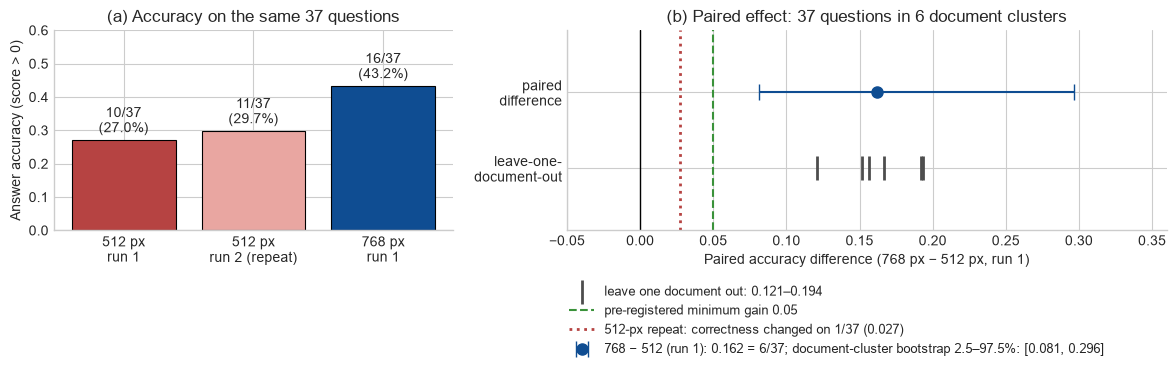

In [23]:
E1_COLORS = {"512_r1": "#B64342", "512_r2": "#E9A6A1", "768_r1": "#0F4D92", "neutral": "#CFCECE",
             "gain": "#3A923A", "dark": "#4D4D4D", "fixed": "#8BCF8B", "both_correct": "#AFC8E6"}
E1_RUN_LABELS = {"512_r1": "512 px, run 1", "512_r2": "512 px, run 2 (repeat)", "768_r1": "768 px, run 1"}
DOC_SHORT = {"2210.02442v1.pdf": "2210.02442 (paper)", "PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf": "Pew COVID report",
             "bdf54dxa.pdf": "bdf54dxa", "earlybird-110722143746-phpapp02_95.pdf": "Earlybird slides",
             "germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf": "Germanwings slides", "watch_d.pdf": "watch_d"}
N_E1 = len(e1_table)


def save_e1_figure(fig, name):
    fig.savefig(E1_FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(E1_FIG_DIR / f"{name}.pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
    plt.show()


# Figure 1: accuracy per condition and the paired difference.
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.5]})
runs = ["512_r1", "512_r2", "768_r1"]
correct_counts = [int(e1_table[f"correct_{run}"].sum()) for run in runs]
bars = ax_a.bar(range(3), np.array(correct_counts) / N_E1, color=[E1_COLORS[r] for r in runs], edgecolor="black", linewidth=0.8)
for index, count in enumerate(correct_counts):
    ax_a.text(index, count / N_E1 + 0.012, f"{count}/{N_E1}\n({count / N_E1:.1%})", ha="center", va="bottom")
ax_a.set_xticks(range(3), ["512 px\nrun 1", "512 px\nrun 2 (repeat)", "768 px\nrun 1"])
ax_a.set(ylabel="Answer accuracy (score > 0)", ylim=(0, 0.6), title="(a) Accuracy on the same 37 questions")
estimate, (low, high) = primary["paired_answer_accuracy_difference"], primary["document_cluster_bootstrap_95_interval"]
ax_b.errorbar([estimate], [1.0], xerr=[[estimate - low], [high - estimate]], fmt="o", ms=8, capsize=6, color=E1_COLORS["768_r1"],
              label=f"768 − 512 (run 1): {estimate:.3f} = 6/37; document-cluster bootstrap 2.5–97.5%: [{low:.3f}, {high:.3f}]")
lodo = list(primary["leave_one_document_out"].values())
ax_b.scatter(lodo, [0.45] * len(lodo), marker="|", s=300, linewidths=2, color=E1_COLORS["dark"],
             label=f"leave one document out: {min(lodo):.3f}–{max(lodo):.3f}")
ax_b.axvline(0, color="black", linewidth=1)
ax_b.axvline(rules["minimum_primary_accuracy_gain"], color=E1_COLORS["gain"], linestyle="--", linewidth=1.5, label="pre-registered minimum gain 0.05")
ax_b.axvline(repeated_control["correctness_change_rate_for_decision"], color=E1_COLORS["512_r1"], linestyle=":", linewidth=2,
             label="512-px repeat: correctness changed on 1/37 (0.027)")
ax_b.set(yticks=[1.0, 0.45], yticklabels=["paired\ndifference", "leave-one-\ndocument-out"], ylim=(0, 1.45), xlim=(-0.05, 0.36),
         xlabel="Paired accuracy difference (768 px − 512 px, run 1)", title="(b) Paired effect: 37 questions in 6 document clusters")
ax_b.legend(loc="upper center", bbox_to_anchor=(0.45, -0.22), ncol=1, fontsize=9)
fig.tight_layout(pad=1.5)
save_e1_figure(fig, "fig1_accuracy")

**Reading figure 1.** At 768 px, 16 of 37 questions are correct against 10 of 37 at 512 px. A second, identical 512-px run gives 11 of 37. The paired difference, 6/37 = 0.162, sits above both the pre-registered 0.05 minimum and the 0.027 repeat margin. It stays at or above 0.121 whichever document is removed. The bootstrap range [0.081, 0.296] describes how the six documents vary. It is not a population confidence interval: with six clusters, the 2.5% bound comes from resampling the least favourable documents and is unstable.

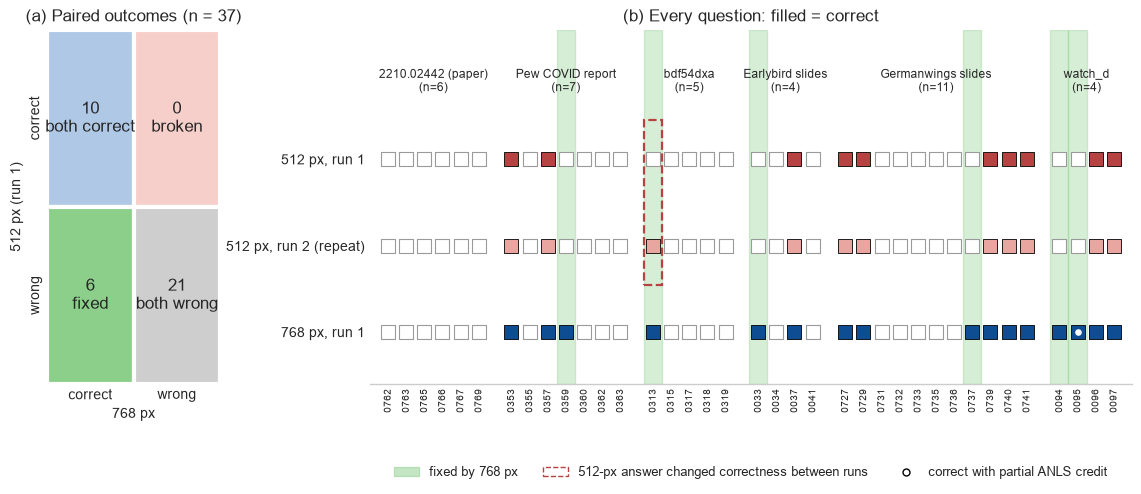

In [24]:
# Figure 2: paired outcomes, as a 2 x 2 table and per question.
fig = plt.figure(figsize=(14, 4.6))
grid = fig.add_gridspec(1, 2, width_ratios=[1, 4.4], wspace=0.32)
ax_t, ax_q = fig.add_subplot(grid[0]), fig.add_subplot(grid[1])
cells = {("correct", "correct"): ("both correct", E1_COLORS["both_correct"]), ("correct", "wrong"): ("broken", "#F6CFCB"),
         ("wrong", "correct"): ("fixed", E1_COLORS["fixed"]), ("wrong", "wrong"): ("both wrong", E1_COLORS["neutral"])}
counts_2x2 = e1_table["transition_512_to_768"].value_counts()
for row, state_512 in enumerate(["correct", "wrong"]):
    for col, state_768 in enumerate(["correct", "wrong"]):
        label, color = cells[(state_512, state_768)]
        ax_t.add_patch(plt.Rectangle((col, 1 - row), 1, 1, facecolor=color, edgecolor="white", linewidth=3))
        ax_t.text(col + 0.5, 1.5 - row, f"{int(counts_2x2.get(label, 0))}\n{label}", ha="center", va="center", fontsize=12)
ax_t.set(xlim=(0, 2), ylim=(0, 2), xticks=[0.5, 1.5], yticks=[1.5, 0.5], xlabel="768 px", ylabel="512 px (run 1)",
         title="(a) Paired outcomes (n = 37)")
ax_t.set_xticklabels(["correct", "wrong"]); ax_t.set_yticklabels(["correct", "wrong"], rotation=90, va="center")
ax_t.tick_params(length=0)
for spine in ax_t.spines.values():
    spine.set_visible(False)

ordered = e1_table.reset_index().sort_values(["doc_id", "qid"]).reset_index(drop=True)
x_positions, x, previous_doc, doc_spans = [], 0.0, None, []
for doc in ordered["doc_id"]:
    if previous_doc is not None and doc != previous_doc:
        x += 0.8
    x_positions.append(x); previous_doc = doc; x += 1
ordered["x"] = x_positions
for row_index, run in enumerate(runs):
    y = 2 - row_index
    correct = ordered[f"correct_{run}"]
    ax_q.scatter(ordered.loc[correct, "x"], [y] * correct.sum(), marker="s", s=95, color=E1_COLORS[run], edgecolor="black", linewidth=0.6)
    ax_q.scatter(ordered.loc[~correct, "x"], [y] * (~correct).sum(), marker="s", s=95, facecolor="white", edgecolor="#9A9A9A", linewidth=0.8)
    partial = ordered[(ordered[f"score_{run}"] > 0) & (ordered[f"score_{run}"] < 1)]
    ax_q.scatter(partial["x"], [y] * len(partial), marker="o", s=14, color="white", zorder=3)
for _, item in ordered[ordered["transition_512_to_768"] == "fixed"].iterrows():
    ax_q.axvspan(item["x"] - 0.5, item["x"] + 0.5, color=E1_COLORS["fixed"], alpha=0.35, zorder=0)
for _, item in ordered[ordered["repeat_transition"].isin(["fixed", "broken"])].iterrows():
    ax_q.add_patch(plt.Rectangle((item["x"] - 0.5, 0.55), 1, 1.9, fill=False, edgecolor=E1_COLORS["512_r1"], linewidth=1.6, linestyle="--"))
for doc, group in ordered.groupby("doc_id", sort=False):
    ax_q.text(group["x"].mean(), 2.75, f"{DOC_SHORT[doc]}\n(n={len(group)})", ha="center", va="bottom", fontsize=8.5)
ax_q.set_xticks(ordered["x"], ordered["qid"].str.replace("mmlb-", ""), rotation=90, fontsize=7.5)
ax_q.set_yticks([2, 1, 0], [E1_RUN_LABELS[r] for r in runs])
ax_q.set(ylim=(-0.6, 3.5), xlim=(-1, ordered["x"].max() + 1), title="(b) Every question: filled = correct")
ax_q.spines["left"].set_visible(False); ax_q.tick_params(axis="y", length=0); ax_q.grid(False)
legend_handles = [plt.Rectangle((0, 0), 1, 1, color=E1_COLORS["fixed"], alpha=0.5, label="fixed by 768 px"),
                  plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor=E1_COLORS["512_r1"], linestyle="--", label="512-px answer changed correctness between runs"),
                  plt.Line2D([], [], marker="o", color="white", markeredgecolor="black", linestyle="", markersize=5, label="correct with partial ANLS credit")]
ax_q.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=9)
save_e1_figure(fig, "fig2_paired_outcomes")

**Reading figure 2.** Every change between resolutions goes the same way: 6 fixed, 0 broken, 10 correct in both, 21 wrong in both. The fixes are small printed values in charts, figures and slides: a valuation difference from a slide chart (`0033`), a blog count on a slide (`0737`), a count of illustrated postures (`0094`) and a measurement (`0095`, partial ANLS credit: "2.5-3" against "2.5-3cm") in a watch guidebook, a step number in a manual's figure (`0313`), and a percentage difference from a report chart (`0359`). Two fixes need caution. `0313` is also fixed by the identical 512-px repeat (dashed box), so its fix is within run-to-run variation. `0359` gave different wrong 512-px answers in the two runs (5, then 11). Four fixes (`0033`, `0094`, `0095`, `0737`) have the same wrong 512-px answer in both runs. They are the most robust evidence that resolution, not chance, changed the answer. Under a stricter rule counting only score = 1 (not the frozen rule), the gain would be 5/37.

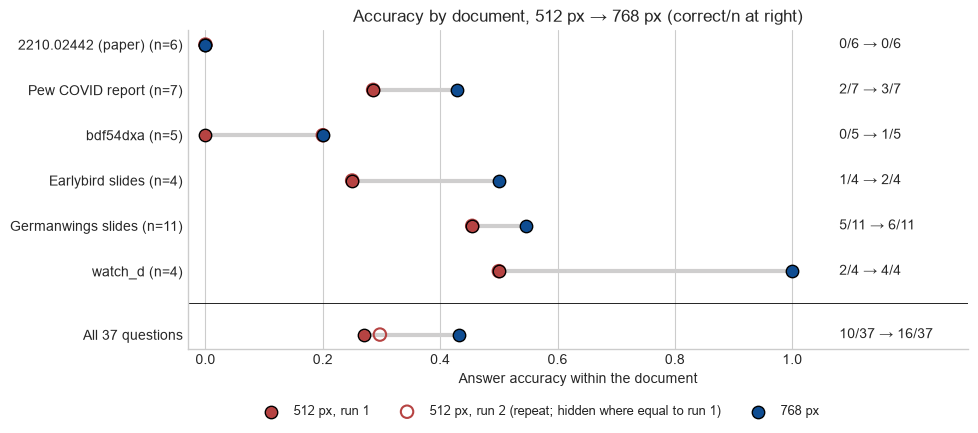

In [25]:
# Figure 3: results by document.
fig, ax = plt.subplots(figsize=(10, 4.6))
doc_order = list(e1_spec["population"]["documents"])
doc_frame = e1_table.groupby("doc_id").agg(n=("correct_512_r1", "size"), c512=("correct_512_r1", "sum"),
                                           c512b=("correct_512_r2", "sum"), c768=("correct_768_r1", "sum")).loc[doc_order]
overall = pd.DataFrame({"n": [N_E1], "c512": [doc_frame["c512"].sum()], "c512b": [doc_frame["c512b"].sum()], "c768": [doc_frame["c768"].sum()]},
                       index=["All 37 questions"])
plot_frame = pd.concat([doc_frame.rename(index=DOC_SHORT), overall])
y_values = np.arange(len(plot_frame))[::-1].astype(float)
y_values[-1] -= 0.4
for y, (label, item) in zip(y_values, plot_frame.iterrows()):
    a512, b512, a768 = item["c512"] / item["n"], item["c512b"] / item["n"], item["c768"] / item["n"]
    ax.plot([a512, a768], [y, y], color=E1_COLORS["neutral"], linewidth=3, zorder=1)
    ax.scatter([a512], [y], s=80, color=E1_COLORS["512_r1"], edgecolor="black", zorder=3, label="512 px, run 1" if y == y_values[0] else None)
    ax.scatter([b512], [y], s=80, facecolor="none", edgecolor=E1_COLORS["512_r1"], linewidth=1.5, zorder=2, label="512 px, run 2 (repeat; hidden where equal to run 1)" if y == y_values[0] else None)
    ax.scatter([a768], [y], s=80, color=E1_COLORS["768_r1"], edgecolor="black", zorder=3, label="768 px" if y == y_values[0] else None)
    ax.text(1.08, y, f"{int(item['c512'])}/{int(item['n'])} → {int(item['c768'])}/{int(item['n'])}", va="center", fontsize=10)
ax.axhline(y_values[-1] + 0.7, color="black", linewidth=0.6)
ax.set_yticks(y_values, [f"{label} (n={int(n)})" if label != "All 37 questions" else label for label, n in zip(plot_frame.index, plot_frame["n"])])
ax.set(xlim=(-0.03, 1.3), xticks=np.linspace(0, 1, 6), xlabel="Answer accuracy within the document",
       title="Accuracy by document, 512 px → 768 px (correct/n at right)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.14), ncol=3, fontsize=9)
ax.grid(axis="y", visible=False)
fig.tight_layout(pad=1.5)
save_e1_figure(fig, "fig3_by_document")

**Reading figure 3.** Five of six documents improve, one stays level, none gets worse. The gains are one or two questions per document. `watch_d` goes from 2/4 to 4/4. The arXiv paper `2210.02442` stays at 0/6 at both resolutions: its failures are mostly counting and reasoning over figures and charts (manual review, section 8), which more pixels do not fix. With 4–11 questions per document, per-document accuracies are anecdotal. The figure shows *breadth* (the effect is not driven by one document), not a per-document effect size.

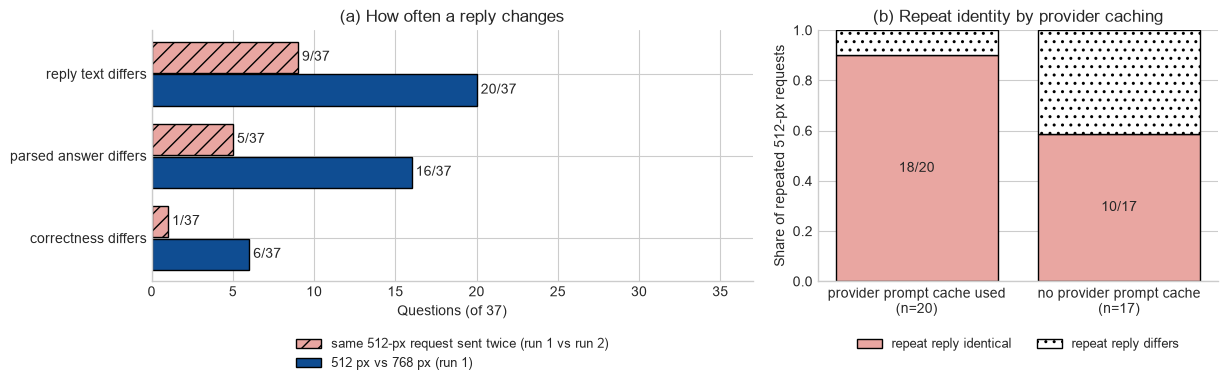

In [26]:
# Figure 4: run-to-run variability of the identical 512-px request versus the resolution change.
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
levels = ["reply text differs", "parsed answer differs", "correctness differs"]
repeat_counts = [int((~e1_variability["repeat_reply_identical"]).sum()), int((~e1_variability["repeat_answer_identical"]).sum()),
                 int((e1_table["correct_512_r1"] != e1_table["correct_512_r2"]).sum())]
resolution_counts = [int((~e1_variability["768_reply_identical"]).sum()), int((~e1_variability["768_answer_identical"]).sum()),
                     int((e1_table["correct_512_r1"] != e1_table["correct_768_r1"]).sum())]
y = np.arange(len(levels))[::-1]
bars_repeat = ax_a.barh(y + 0.2, repeat_counts, height=0.38, color=E1_COLORS["512_r2"], edgecolor="black", hatch="//",
                        label="same 512-px request sent twice (run 1 vs run 2)")
bars_resolution = ax_a.barh(y - 0.2, resolution_counts, height=0.38, color=E1_COLORS["768_r1"], edgecolor="black",
                            label="512 px vs 768 px (run 1)")
ax_a.bar_label(bars_repeat, labels=[f"{v}/37" for v in repeat_counts], padding=3)
ax_a.bar_label(bars_resolution, labels=[f"{v}/37" for v in resolution_counts], padding=3)
ax_a.set_yticks(y, levels)
ax_a.set(xlim=(0, 37), xlabel="Questions (of 37)", title="(a) How often a reply changes")
ax_a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=1, fontsize=9)
split = e1_variability.groupby("repeat_used_provider_prompt_cache").agg(n=("repeat_reply_identical", "size"),
                                                                        same=("repeat_reply_identical", "sum")).reindex([True, False])
labels_b = [f"provider prompt cache used\n(n={split.loc[True, 'n']})", f"no provider prompt cache\n(n={split.loc[False, 'n']})"]
ax_b.bar(labels_b, split["same"] / split["n"], color=E1_COLORS["512_r2"], edgecolor="black", label="repeat reply identical")
ax_b.bar(labels_b, 1 - split["same"] / split["n"], bottom=split["same"] / split["n"], color="white", edgecolor="black", hatch="..",
         label="repeat reply differs")
for index, (flag, item) in enumerate(split.iterrows()):
    ax_b.text(index, item["same"] / item["n"] / 2, f"{int(item['same'])}/{int(item['n'])}", ha="center", va="center")
ax_b.set(ylim=(0, 1), ylabel="Share of repeated 512-px requests", title="(b) Repeat identity by provider caching")
ax_b.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9)
fig.tight_layout(pad=1.5)
save_e1_figure(fig, "fig4_repeat_variability")

**Reading figure 4.** At temperature 0, the identical 512-px request produced a different reply text for 9/37 questions and a different parsed answer for 5/37. Correctness changed for only 1/37 (`0313`), because most changes went from one wrong answer to another. The decision rule uses correctness changes, as pre-registered. The answer-level instability (5/37) is still worth keeping in mind: it is larger than the correctness margin suggests. Changing resolution moved 16/37 answers and 6/37 correctness outcomes, several times the repeat's rate at every level. Panel (b): repeats that hit OpenAI's prompt cache reproduced the reply more often (18/20) than those that did not (10/17). The repeat therefore probably *underestimates* cold-start variability. With n = 20 and 17, and with cache use confounded with timing, this is an observation, not an estimate.

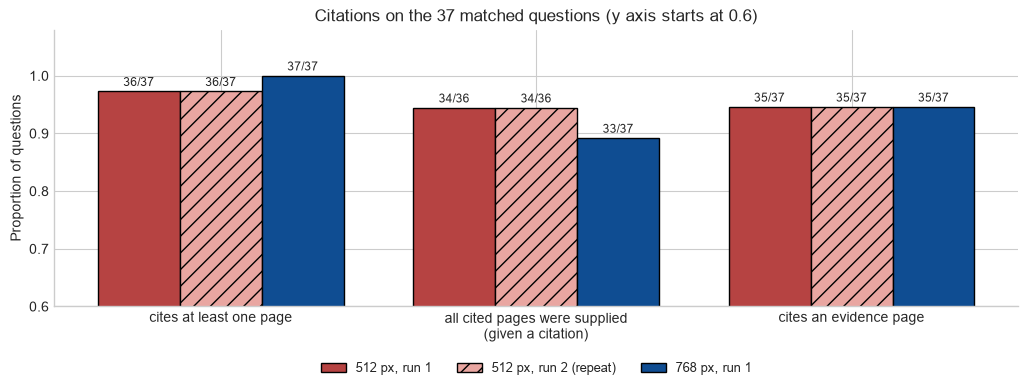

,qid,run,supplied,cited,every invalid page is one below a supplied page
0,mmlb-0313,"512 px, run 1",[11],[10],True
1,mmlb-0362,"512 px, run 1","[12, 16]","[12, 15]",True
2,mmlb-0313,"512 px, run 2 (repeat)",[11],[10],True
3,mmlb-0362,"512 px, run 2 (repeat)","[12, 16]","[12, 15]",True
4,mmlb-0313,"768 px, run 1",[11],[10],True
5,mmlb-0315,"768 px, run 1",[14],[13],True
6,mmlb-0359,"768 px, run 1","[11, 12]","[10, 11]",True
7,mmlb-0362,"768 px, run 1","[12, 16]","[12, 15]",True


In [27]:
# Figure 5: citation coverage and validity.
fig, ax = plt.subplots(figsize=(10.5, 4.2))
metric_specs = [("cites at least one page", lambda s: e1_table[f"cited_{s}"].map(json.loads).map(bool), None),
                ("all cited pages were supplied\n(given a citation)", lambda s: e1_table[f"citation_valid_{s}"],
                 lambda s: e1_table[f"cited_{s}"].map(json.loads).map(bool)),
                ("cites an evidence page", lambda s: pd.Series([bool(set(json.loads(c)) & set(json.loads(e)))
                                                               for c, e in zip(e1_table[f"cited_{s}"], e1_table["evidence_pages"])], index=e1_table.index), None)]
width = 0.26
for offset, run in zip((-width, 0, width), runs):
    values, labels = [], []
    for _, numerator, denominator in metric_specs:
        mask = denominator(run) if denominator else pd.Series(True, index=e1_table.index)
        hits, total = int(numerator(run)[mask].sum()), int(mask.sum())
        values.append(hits / total); labels.append(f"{hits}/{total}")
    bars = ax.bar(np.arange(len(metric_specs)) + offset, values, width=width, color=E1_COLORS[run], edgecolor="black",
                  hatch="//" if run == "512_r2" else None, label=E1_RUN_LABELS[run])
    ax.bar_label(bars, labels=labels, padding=2, fontsize=8.5)
ax.set_xticks(np.arange(len(metric_specs)), [name for name, _, _ in metric_specs])
ax.set(ylim=(0.6, 1.08), ylabel="Proportion of questions", title="Citations on the 37 matched questions (y axis starts at 0.6)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, fontsize=9)
fig.tight_layout(pad=1.5)
save_e1_figure(fig, "fig5_citations")
invalid = [{"qid": q, "run": E1_RUN_LABELS[s], "supplied": e1_table.loc[q, "evidence_pages"], "cited": e1_table.loc[q, f"cited_{s}"]}
           for s in runs for q in e1_table.index if not e1_table.loc[q, f"citation_valid_{s}"]]
invalid_frame = pd.DataFrame(invalid)
invalid_frame["every invalid page is one below a supplied page"] = [
    all(page + 1 in json.loads(s) for page in set(json.loads(c)) - set(json.loads(s))) for s, c in zip(invalid_frame["supplied"], invalid_frame["cited"])]
display(invalid_frame)

**Reading figure 5.** Citation validity falls from 34/36 to 33/37 (94.4% → 89.2%) because of two questions. `0315` had no citation at 512 px and cites page 13 for supplied page 14 at 768 px. `0359` is answered correctly at 768 px but cites pages 10–11 for supplied pages 11–12. All eight invalid citations, at both resolutions, are exactly one page below a supplied page. This is the "printed page number instead of `[Page N]` tag" failure already found in the baseline (section 6), not a new failure type. A plausible but untested mechanism is that page numbers printed on the page become legible at 768 px. Evidence-page citation is unchanged (35/37 in all runs). Because E1 supplies only evidence pages, these numbers cannot show whether resolution helps the model *choose* among distractor pages.

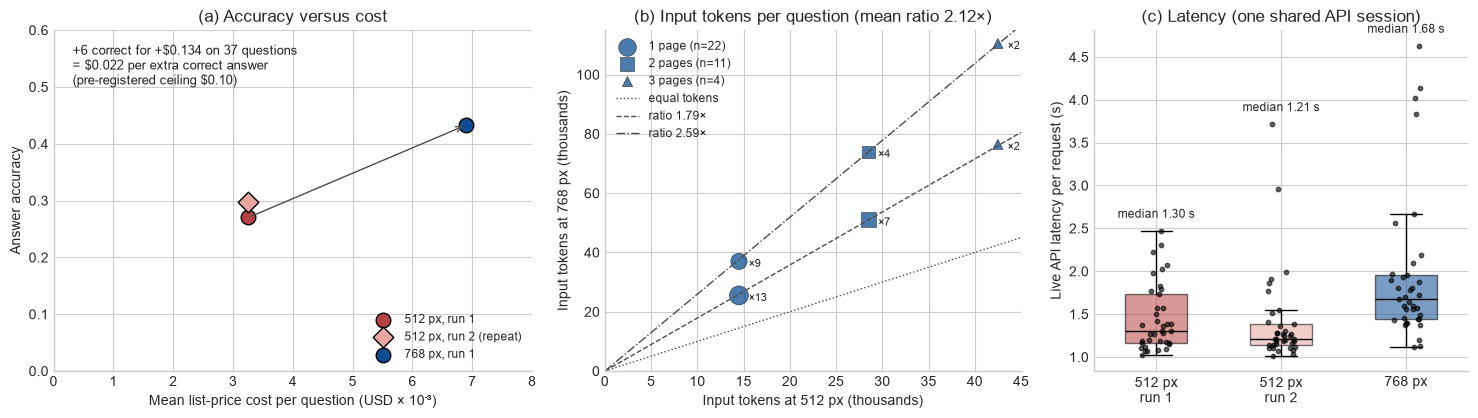

Mean list-price cost per question: 512 px $0.00326, 768 px $0.00689; mean latency 512 px 1.46 s, 768 px 1.95 s.


In [28]:
# Figure 6: accuracy versus computational cost.
fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.15, 1, 0.9]})
price = lambda tokens_in, tokens_out: (tokens_in * PRICES["input"] + tokens_out * PRICES["output"]) / 1e6
cost = {run: price(e1_table[f"input_tokens_{run}"], e1_table[f"output_tokens_{run}"]) for run in runs}
for run in runs:
    ax_a.scatter(cost[run].mean() * 1000, e1_table[f"correct_{run}"].mean(), s=110, color=E1_COLORS[run], edgecolor="black",
                 marker="o" if run != "512_r2" else "D", label=E1_RUN_LABELS[run], zorder=3)
ax_a.annotate("", xy=(cost["768_r1"].mean() * 1000, e1_table["correct_768_r1"].mean()),
              xytext=(cost["512_r1"].mean() * 1000, e1_table["correct_512_r1"].mean()), arrowprops={"arrowstyle": "->", "color": E1_COLORS["dark"]})
extra_cost = cost["768_r1"].sum() - cost["512_r1"].sum()
ax_a.text(0.04, 0.96, f"+6 correct for +${extra_cost:.3f} on 37 questions\n= ${extra_cost / 6:.3f} per extra correct answer\n(pre-registered ceiling $0.10)",
          transform=ax_a.transAxes, va="top", fontsize=9)
ax_a.set(xlabel="Mean list-price cost per question (USD × 10⁻³)", ylabel="Answer accuracy", ylim=(0, 0.6), xlim=(0, 8),
         title="(a) Accuracy versus cost")
ax_a.legend(loc="lower right", fontsize=8.5)
pages_count = e1_table["evidence_pages"].map(lambda value: len(json.loads(value)))
# Pages of the same shape give the same image tokens; points within 500 tokens are drawn once with their question count.
token_points = e1_table.assign(pages=pages_count, x_k=(e1_table["input_tokens_512_r1"] / 500).round() / 2,
                               y_k=(e1_table["input_tokens_768_r1"] / 500).round() / 2).groupby(["pages", "x_k", "y_k"]).size().rename("n").reset_index()
for n_pages, marker in zip(sorted(pages_count.unique()), ["o", "s", "^"]):
    points = token_points[token_points["pages"] == n_pages]
    ax_b.scatter(points["x_k"], points["y_k"], marker=marker, s=30 + 12 * points["n"],
                 color=E1_COLORS["768_r1"], alpha=0.75, edgecolor="black", linewidth=0.4,
                 label=f"{n_pages} page{'s' if n_pages > 1 else ''} (n={int((pages_count == n_pages).sum())})")
    for _, point in points.iterrows():
        ax_b.annotate(f"×{int(point['n'])}", (point["x_k"], point["y_k"]),
                      xytext=(7, -4), textcoords="offset points", fontsize=8)
limit = np.array([0, 45])
ax_b.plot(limit, limit, color=E1_COLORS["dark"], linewidth=1, linestyle=":", label="equal tokens")
ratio = decision["observed_mean_input_token_ratio_descriptive_only"]
per_question_ratio = e1_table["input_tokens_768_r1"] / e1_table["input_tokens_512_r1"]
for value, style in ((per_question_ratio.min(), "--"), (per_question_ratio.max(), "-.")):
    ax_b.plot(limit, value * limit, color=E1_COLORS["dark"], linewidth=1, linestyle=style, label=f"ratio {value:.2f}×")
ax_b.set(xlim=(0, 45), ylim=(0, 115), xlabel="Input tokens at 512 px (thousands)", ylabel="Input tokens at 768 px (thousands)",
         title=f"(b) Input tokens per question (mean ratio {ratio:.2f}×)")
ax_b.legend(loc="upper left", fontsize=8.5)
latency = [e1_table[f"latency_s_{run}"] for run in runs]
box = ax_c.boxplot([values.to_numpy() for values in latency], widths=0.5, patch_artist=True, showfliers=False, medianprops={"color": "black"})
for patch, run in zip(box["boxes"], runs):
    patch.set_facecolor(E1_COLORS[run]); patch.set_alpha(0.55)
rng_jitter = np.random.default_rng(0)
for index, values in enumerate(latency, start=1):
    ax_c.scatter(index + rng_jitter.uniform(-0.12, 0.12, len(values)), values, s=10, color="black", alpha=0.6, zorder=3)
    ax_c.text(index, values.max() + 0.15, f"median {values.median():.2f} s", ha="center", fontsize=8.5)
ax_c.set_xticks([1, 2, 3], ["512 px\nrun 1", "512 px\nrun 2", "768 px"])
ax_c.set(ylabel="Live API latency per request (s)", title="(c) Latency (one shared API session)")
fig.tight_layout(pad=1.5)
save_e1_figure(fig, "fig6_accuracy_cost")
print(f"Mean list-price cost per question: 512 px ${cost['512_r1'].mean():.5f}, 768 px ${cost['768_r1'].mean():.5f}; "
      f"mean latency 512 px {latency[0].mean():.2f} s, 768 px {latency[2].mean():.2f} s.")

**Reading figure 6.** 768 px costs 2.12× the input tokens on average (21.6k → 45.8k per question; up to 110.7k for three-page questions, close to the 128k context). The ratio is not one number. It is 1.79× for pages that go from 2 to 4 high-detail tiles and 2.59× for wide (16:9) slides that go from 2 to 6 tiles (×n marks how many questions share a point). Mean list-price cost rises from $0.0033 to $0.0069 per question. Six extra correct answers cost $0.134 in total, $0.022 each, 4.5× below the pre-registered $0.10 ceiling. Median latency rises from about 1.3 s to 1.7 s per request. Costs are list-price upper bounds: provider caching discounted part of the input, so the true bill is somewhat lower (about $0.47 instead of $0.50 for the whole run, if cached input is billed at half price). Latency was measured in one session on one day and depends on load.

**What E1 shows.** For GPT-4o-mini on annotated evidence pages, 768-px renders fixed six answers and broke none. The fixes are small printed digits, counts and labels that are illegible at 512 px. The pre-registered rule says *adopt 768 px* for this model and question set. **What remains unsolved:** 21 of 37 questions are wrong at both resolutions, dominated by counting, aggregation and chart-reasoning failures that resolution does not address. **Trade-offs:** twice the tokens, cost and context use (the three questions with 5–13 evidence pages could not be run at 768 px), slightly higher latency, and more off-by-one citations.

## 14. E2 evaluation — Qwen3-VL-8B against frozen GPT-4o-mini

E2 is scored only from an immutable run directory produced by notebook 02 (paid OpenRouter calls). By default this is the frozen full run in `experiments/frozen/e2/`, a byte-identical copy checked against its `SHA256SUMS`. `VISUALDOC_E2_RUN_DIR` selects another saved run instead. No API call is made here.

**Comparator.** The GPT-4o-mini cells are the frozen E1 replies (`E1_512` and `E1_768` from `main_r1`, plus the 512-px repeat `control_r2`). Their file hashes are checked against the E2 spec, and their regression counts (10, 16, 11 of 37) are asserted. They are scored by the same `score_condition` and `eval_score` as every other condition in this notebook. Nothing in the scorer changes for E2.

**Primary outcome.** The paired accuracy difference on the 37 questions:
$$\Delta = \frac{1}{37}\sum_i \big(\text{correct}_{Q768,i} - \text{correct}_{G768,i}\big),$$
reported with fixed and broken counts. Secondary outcomes:

- mean benchmark-score difference;
- strict accuracy (score = 1 only);
- the Qwen 512 → 768 effect;
- the **model × resolution interaction**, the per-question contrast
  $$d_i = (c_{Q768,i} - c_{Q512,i}) - (c_{G768,i} - c_{G512,i});$$
- citations (coverage, validity given a citation, evidence citation, and off-by-one citations, where every invalid page equals a supplied page minus one);
- results by document and on the frozen visual-reading subgroup;
- repeat variability;
- latency, memory and cost.

**Decision rule** (spec, fixed before any generation). Adopt Qwen@768 only if all three hold:

- $\Delta \ge 0.05$;
- $\Delta > \max(1/37,\ \text{Qwen repeat correctness-change rate})$;
- broken ≤ fixed / 2.

Retain GPT-4o-mini@768 if $\Delta \le 0$; otherwise the result is inconclusive. The GPT-4o-mini repeat margin was measured at 512 px only and is assumed to hold at 768 px. That assumption is stated, not tested.

**What is not valid.** Frozen condition D used five pages padded with BM25 distractors at 512 px, so it is never paired with E2. Cost compares OpenRouter's reported actual cost for Qwen with OpenAI list-price upper bounds for GPT-4o-mini. It is descriptive only. The run validation also requires every reply to come from the pinned provider with the expected prompt-token count. That is the only available evidence about the hosted model's version and image preprocessing, and it is not proof.

**Uncertainty.** Document-cluster bootstrap (6 clusters), leave-one-document-out, and exact McNemar (which ignores clustering): all descriptive. With 37 questions, one question is 0.027.

In [29]:
# E2 inputs: the tracked spec, the offline design from 02, and the frozen GPT-4o-mini comparator (hash-checked).
import tempfile

E2_DIR = PROCESSED_DIR / "e2"
FROZEN_E2_DIR = PROJECT_ROOT / "experiments" / "frozen" / "e2"
FROZEN_E2_RUN = FROZEN_E2_DIR / "run_20261122T120924635816Z_4f2e1369_full"
assert (E2_DIR / "design.json").is_file(), "e2/design.json missing: run notebook 02 (E2 offline mode) first"
e2_spec_bytes = (PROJECT_ROOT / "experiments" / "specs" / "e2_stronger_vlm_v2.json").read_bytes()
e2_spec = json.loads(e2_spec_bytes)
e2_spec_sha256 = hashlib.sha256(e2_spec_bytes).hexdigest()
e2_design = json.loads((E2_DIR / "design.json").read_text())
assert e2_design["spec_sha256"] == e2_spec_sha256, "the E2 spec changed after notebook 02 ran: rerun 02"
E2_QIDS = e2_spec["population"]["matched_qids"]
E2_DOCS = e2_spec["population"]["documents"]
e2_rules = e2_spec["decision_rule"]
E2_COMPARATOR_RUN = PROJECT_ROOT / e2_spec["comparator"]["frozen_run_dir"]
for name, digest in e2_spec["comparator"]["file_sha256"].items():
    assert hashlib.sha256((E2_COMPARATOR_RUN / name).read_bytes()).hexdigest() == digest, f"frozen E1 file changed: {name}"
e2_comparator = {"G512": read_jsonl(E2_COMPARATOR_RUN / "predictions_main_r1_E1_512.jsonl"),
                 "G768": read_jsonl(E2_COMPARATOR_RUN / "predictions_main_r1_E1_768.jsonl"),
                 "G512_r2": read_jsonl(E2_COMPARATOR_RUN / "predictions_control_r2_E1_512.jsonl")}
assert {k: int(score_condition(v)["correct"].sum()) for k, v in e2_comparator.items()} == {"G512": 10, "G768": 16, "G512_r2": 11}
E2_CELLS = {"G512": "GPT-4o-mini, 512 px", "G768": "GPT-4o-mini, 768 px", "G512_r2": "GPT-4o-mini, 512 px repeat",
            "Q512": "Qwen3-VL-8B, 512 px", "Q768": "Qwen3-VL-8B, 768 px", "Q768_r2": "Qwen3-VL-8B, 768 px repeat"}


def e2_transition(before, after):
    return np.select([~before & after, before & ~after, before & after], ["fixed", "broken", "both correct"], "both wrong")


def e2_off_by_one(cited, supplied):
    # Every cited page that was not supplied is exactly one below a supplied page: the printed page number, not the [Page N] tag.
    invalid = set(cited) - set(supplied)
    return bool(invalid) and all(page + 1 in set(supplied) for page in invalid)


def e2_cluster_ci(values, docs):
    groups = [values[docs == doc] for doc in E2_DOCS]
    rng = np.random.default_rng(e2_spec["uncertainty"]["bootstrap_seed"])
    boot = np.array([np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))]).mean()
                     for _ in range(e2_spec["uncertainty"]["bootstrap_draws"])])
    return tuple(float(x) for x in np.quantile(boot, [0.025, 0.975]))


def apply_e2_decision(gain, gpt_repeat_rate, qwen_repeat_rate, fixed, broken, rules):
    margin = max(gpt_repeat_rate, qwen_repeat_rate)
    criteria = {"paired gain >= 0.05": gain >= rules["minimum_primary_accuracy_gain"],
                "paired gain > max repeat change rate": gain > margin,
                "broken <= fixed / 2": broken <= rules["maximum_broken_to_fixed_ratio"] * fixed}
    verdict = ("adopt_qwen3_vl_8b_768_for_this_pipeline" if all(criteria.values())
               else "retain_gpt4o_mini_768_reference" if gain <= 0 else "inconclusive")
    return {"verdict": verdict, "criteria": criteria, "variability_margin": margin}


# Decision boundaries on synthetic numbers (not E2 outcomes).
synthetic_e2 = {
    "adopt": apply_e2_decision(3 / 37, 1 / 37, 0.0, 4, 1, e2_rules)["verdict"],
    "adopt at broken = fixed / 2": apply_e2_decision(3 / 37, 1 / 37, 0.0, 6, 3, e2_rules)["verdict"],
    "too many broken": apply_e2_decision(3 / 37, 1 / 37, 0.0, 7, 4, e2_rules)["verdict"],
    "gain not above Qwen repeat margin": apply_e2_decision(2 / 37, 1 / 37, 2 / 37, 2, 0, e2_rules)["verdict"],
    "gain below 0.05": apply_e2_decision(1 / 37, 0.0, 0.0, 1, 0, e2_rules)["verdict"],
    "no gain": apply_e2_decision(0.0, 1 / 37, 0.0, 2, 2, e2_rules)["verdict"],
    "loss": apply_e2_decision(-2 / 37, 1 / 37, 0.0, 1, 3, e2_rules)["verdict"],
}
assert synthetic_e2 == {"adopt": "adopt_qwen3_vl_8b_768_for_this_pipeline", "adopt at broken = fixed / 2": "adopt_qwen3_vl_8b_768_for_this_pipeline",
                        "too many broken": "inconclusive", "gain not above Qwen repeat margin": "inconclusive", "gain below 0.05": "inconclusive",
                        "no gain": "retain_gpt4o_mini_768_reference", "loss": "retain_gpt4o_mini_768_reference"}


def evaluate_e2(qwen_records):
    # qwen_records: {"Q512": [...], "Q768": [...], "Q768_r2": [...]} reply records of one run. Returns (results, per-question table).
    records = {**e2_comparator, **qwen_records}
    scored_e2 = {name: score_condition(values).set_index("qid").loc[E2_QIDS] for name, values in records.items()}
    table = pd.DataFrame({"doc_id": scored_e2["G768"]["doc_id"], "answer_format": scored_e2["G768"]["answer_format"],
                          "reference": scored_e2["G768"]["answer"], "evidence_pages": scored_e2["G768"]["supplied_pages"].map(json.dumps),
                          "visual_reading_subgroup": [q in set(e2_spec["population"]["visual_reading_subgroup_qids"]) for q in E2_QIDS]},
                         index=pd.Index(E2_QIDS, name="qid"))
    for name, frame in scored_e2.items():
        table[f"pred_{name}"] = frame["pred"].map(json.dumps)
        table[f"score_{name}"] = frame["score"].round(6)
        table[f"correct_{name}"] = frame["correct"].astype(bool)
        table[f"strict_{name}"] = frame["score"] >= 1.0
        table[f"cited_{name}"] = frame["cited_pages"].map(json.dumps)
        table[f"citation_valid_{name}"] = frame["citations_valid"]
        table[f"off_by_one_{name}"] = [e2_off_by_one(c, s) for c, s in zip(frame["cited_pages"], frame["supplied_pages"])]
        table[f"raw_{name}"] = frame["raw_response"]
    c = {name: table[f"correct_{name}"] for name in records}
    table["primary_transition"] = e2_transition(c["G768"], c["Q768"])
    table["qwen_resolution_transition"] = e2_transition(c["Q512"], c["Q768"])
    table["gpt_resolution_transition"] = e2_transition(c["G512"], c["G768"])
    table["qwen_repeat_transition"] = e2_transition(c["Q768"], c["Q768_r2"])
    table["gpt_repeat_transition"] = e2_transition(c["G512"], c["G512_r2"])
    table["interaction"] = (c["Q768"].astype(int) - c["Q512"].astype(int)) - (c["G768"].astype(int) - c["G512"].astype(int))

    docs = table["doc_id"].to_numpy()
    n = len(table)
    primary_diff = (c["Q768"].astype(float) - c["G768"].astype(float)).to_numpy()
    counts = table["primary_transition"].value_counts().reindex(["fixed", "broken", "both correct", "both wrong"], fill_value=0)
    fixed, broken = int(counts["fixed"]), int(counts["broken"])
    gpt_rate = int(table["gpt_repeat_transition"].isin(["fixed", "broken"]).sum()) / n
    qwen_rate = int(table["qwen_repeat_transition"].isin(["fixed", "broken"]).sum()) / n
    primary_e2 = {"questions": n, "documents": int(table["doc_id"].nunique()), "paired_accuracy_difference": float(primary_diff.mean()),
                  "fixed": fixed, "broken": broken, "both_correct": int(counts["both correct"]), "both_wrong": int(counts["both wrong"]),
                  "document_cluster_bootstrap_95": e2_cluster_ci(primary_diff, docs),
                  "leave_one_document_out": {d: float(primary_diff[docs != d].mean()) for d in E2_DOCS},
                  "exact_mcnemar_p_ignores_clustering": mcnemar_exact_p(fixed, broken)}
    score_diff = (table["score_Q768"] - table["score_G768"]).to_numpy()
    qwen_res = (c["Q768"].astype(float) - c["Q512"].astype(float)).to_numpy()
    secondary_e2 = {
        "paired_mean_score_difference": float(score_diff.mean()), "score_difference_bootstrap_95": e2_cluster_ci(score_diff, docs),
        "strict_accuracy_difference": float((table["strict_Q768"].astype(float) - table["strict_G768"].astype(float)).mean()),
        "qwen_resolution_effect_768_minus_512": float(qwen_res.mean()),
        "gpt_resolution_effect_768_minus_512": float((c["G768"].astype(float) - c["G512"].astype(float)).mean()),
        "interaction_mean": float(table["interaction"].mean()),
        "interaction_bootstrap_95": e2_cluster_ci(table["interaction"].to_numpy(dtype=float), docs),
        "qwen_resolution_transitions": table["qwen_resolution_transition"].value_counts().to_dict(),
        "visual_reading_subgroup": {"questions": int(table["visual_reading_subgroup"].sum()),
                                    "paired_accuracy_difference": float(primary_diff[table["visual_reading_subgroup"].to_numpy()].mean())},
    }
    repeat_e2 = {}
    for label, (first, second) in {"gpt4o_mini_512": ("G512", "G512_r2"), "qwen_768": ("Q768", "Q768_r2")}.items():
        transitions_ = table[f"{'gpt' if label.startswith('gpt') else 'qwen'}_repeat_transition"]
        repeat_e2[label] = {"correctness_changed": int(transitions_.isin(["fixed", "broken"]).sum()),
                            "correctness_change_rate": int(transitions_.isin(["fixed", "broken"]).sum()) / n,
                            "parsed_answer_changed": int((table[f"pred_{first}"] != table[f"pred_{second}"]).sum()),
                            "reply_text_changed": int((table[f"raw_{first}"] != table[f"raw_{second}"]).sum())}
    decision_e2 = apply_e2_decision(primary_e2["paired_accuracy_difference"], gpt_rate, qwen_rate, fixed, broken, e2_rules)

    metric_rows = []
    for name, values in records.items():
        frame, source = scored_e2[name], pd.DataFrame(values).set_index("qid").loc[E2_QIDS]
        cited = frame["cited_pages"].map(bool)
        is_qwen = name.startswith("Q")
        latency = source["api_latency_s"]
        cost = (float(source["cost_usd"].sum()) if is_qwen  # actual OpenRouter usage.cost
                else float((source["prompt_tokens"] * PRICES["input"] + source["completion_tokens"] * PRICES["output"]).sum() / 1e6))
        metric_rows.append({
            "condition": E2_CELLS[name], "correct": f"{int(frame['correct'].sum())}/{n}", "accuracy": frame["correct"].mean(),
            "strict accuracy": (frame["score"] >= 1).mean(), "mean score": frame["score"].mean(),
            "false abstention": frame["predicted_unanswerable"].mean(), "cites a page": cited.mean(),
            "validity given a citation": frame.loc[cited, "citations_valid"].mean() if cited.any() else np.nan,
            "cites evidence": frame["cites_evidence"].astype(float).mean(), "off-by-one citations": int(table[f"off_by_one_{name}"].sum()),
            "parse failures": int((frame["status"] == "parse_error").sum()),
            "truncated": int((source["finish_reason"] != "stop").sum()) if "finish_reason" in source else 0,
            "fence stripped": int(source["fence_stripped"].map(bool).sum()) if "fence_stripped" in source else 0,
            "mean input tokens": source["prompt_tokens"].mean(), "mean output tokens": source["completion_tokens"].mean(),
            "median API latency s": float(latency.median()),
            "provider prompt-cache hits": int((source["cached_prompt_tokens"].fillna(0) > 0).sum()),
            "served by": ", ".join(sorted({str(v) for v in source["served_provider"]})) if is_qwen else ", ".join(sorted({str(v) for v in source["served_model"]})),
            "cost USD (37 questions)": cost, "cost basis": "OpenRouter usage.cost (actual)" if is_qwen else "OpenAI list-price upper bound"})
    metrics_e2 = pd.DataFrame(metric_rows).set_index("condition")
    by_document_e2 = table.groupby("doc_id").agg(questions=("doc_id", "size"), **{f"correct_{k}": (f"correct_{k}", "sum") for k in ("G512", "G768", "Q512", "Q768")}).reindex(E2_DOCS)
    results = {"primary": primary_e2, "secondary": secondary_e2, "repeat": repeat_e2, "decision": decision_e2,
               "metrics": metrics_e2.reset_index().to_dict(orient="records"), "by_document": by_document_e2.reset_index().to_dict(orient="records"),
               "uncertainty_qualification": e2_spec["uncertainty"]["qualification"]}
    return results, table, metrics_e2, by_document_e2


# Interface tests on mocked Qwen runs built from the frozen GPT-4o-mini replies (outcomes known by construction; never results).
def mock_qwen(source, changes=None):
    out = []
    for record in source:
        record = {**record, "status": "ok", "finish_reason": "stop", "fence_stripped": False, "served_model": "qwen/qwen3-vl-8b-instruct",
                  "served_provider": "Parasail", "cost_usd": 0.0004, "cached_prompt_tokens": 0}
        if changes and record["qid"] in changes:
            record["pred"], record["raw_response"] = changes[record["qid"]], json.dumps({"answer": changes[record["qid"]]})
        out.append(record)
    return out


g768 = score_condition(e2_comparator["G768"]).set_index("qid")
self_scorable = [q for q in E2_QIDS if eval_score(reference.loc[q, "answer"], reference.loc[q, "answer"], reference.loc[q, "answer_format"]) >= 1]
to_fix = [q for q in self_scorable if not g768.loc[q, "correct"]][:3]
to_break = [q for q in E2_QIDS if g768.loc[q, "correct"]][:1]
mock_changes = {**{q: reference.loc[q, "answer"] for q in to_fix}, **{q: "Not answerable" for q in to_break}}
flip = [q for q in E2_QIDS if q not in mock_changes and (g768.loc[q, "correct"] or q in self_scorable)][:2]
mock_cases = {
    "identical to GPT-4o-mini": ({"Q512": mock_qwen(e2_comparator["G512"]), "Q768": mock_qwen(e2_comparator["G768"]),
                                  "Q768_r2": mock_qwen(e2_comparator["G768"])}, (0, 0, "retain_gpt4o_mini_768_reference")),
    "3 fixed, 1 broken, stable repeat": ({"Q512": mock_qwen(e2_comparator["G512"]), "Q768": mock_qwen(e2_comparator["G768"], mock_changes),
                                          "Q768_r2": mock_qwen(e2_comparator["G768"], mock_changes)}, (3, 1, "adopt_qwen3_vl_8b_768_for_this_pipeline")),
    "3 fixed, 1 broken, unstable repeat": ({"Q512": mock_qwen(e2_comparator["G512"]), "Q768": mock_qwen(e2_comparator["G768"], mock_changes),
                                            "Q768_r2": mock_qwen(e2_comparator["G768"], {**mock_changes, **{q: reference.loc[q, "answer"] if not g768.loc[q, "correct"] else "Not answerable" for q in flip}})},
                                           (3, 1, "inconclusive")),
}
for label, (mock_records, (want_fixed, want_broken, want_verdict)) in mock_cases.items():
    mock_results, mock_table, mock_metrics, _ = evaluate_e2(mock_records)
    p = mock_results["primary"]
    assert (p["fixed"], p["broken"], mock_results["decision"]["verdict"]) == (want_fixed, want_broken, want_verdict), (label, p, mock_results["decision"])
    assert np.isclose(p["paired_accuracy_difference"], (want_fixed - want_broken) / 37)
    assert mock_table["interaction"].sum() == (mock_table["correct_Q768"].sum() - mock_table["correct_Q512"].sum()) - (16 - 10)
assert mock_results["repeat"]["qwen_768"]["correctness_changed"] == len(flip) and mock_results["repeat"]["gpt4o_mini_512"]["correctness_changed"] == 1
print(f"E2 evaluation interface: {len(synthetic_e2)} decision boundaries and {len(mock_cases)} mocked runs reproduce their constructed "
      "outcomes (fixed/broken, gain, interaction, repeat rates, verdict). These are tests, not results.")

E2 evaluation interface: 7 decision boundaries and 3 mocked runs reproduce their constructed outcomes (fixed/broken, gain, interaction, repeat rates, verdict). These are tests, not results.


In [30]:
# E2 figures, drawn from the per-question table. Exercised here on a mocked run and discarded (closed, never shown or saved).
E2_COLORS = {"G": "#B64342", "Q": "#0F4D92", "G_light": "#E9A6A1", "Q_light": "#9DB9DE", "gain": "#3A923A", "loss": "#CC6677",
             "neutral": "#CFCECE", "dark": "#4D4D4D"}
E2_DOC_SHORT = {"2210.02442v1.pdf": "2210.02442 (paper)", "PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf": "Pew COVID report",
                "bdf54dxa.pdf": "bdf54dxa", "earlybird-110722143746-phpapp02_95.pdf": "Earlybird slides",
                "germanwingsdigitalcrisisanalysis-150403064828-conversion-gate01_95.pdf": "Germanwings slides", "watch_d.pdf": "watch_d"}


def draw_e2_figures(table, results, save_dir=None, show=True):
    n = len(table)
    figures = {}
    # Figure 1: the 2 x 2 cells and the primary paired effect.
    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1, 1.5]})
    for offset, (prefix, model) in zip((-0.2, 0.2), (("G", "GPT-4o-mini"), ("Q", "Qwen3-VL-8B"))):
        counts = [int(table[f"correct_{prefix}{res}"].sum()) for res in (512, 768)]
        bars = ax_a.bar(np.arange(2) + offset, np.array(counts) / n, width=0.38, color=E2_COLORS[prefix], edgecolor="black", label=model)
        ax_a.bar_label(bars, labels=[f"{c}/{n}" for c in counts], padding=2, fontsize=9)
    ax_a.set_xticks([0, 1], ["512 px", "768 px"])
    ax_a.set(ylim=(0, 1), ylabel="Answer accuracy (score > 0)", title="(a) Model x resolution, same 37 questions")
    ax_a.legend(loc="upper left", fontsize=9)
    p = results["primary"]
    low, high = p["document_cluster_bootstrap_95"]
    ax_b.errorbar([p["paired_accuracy_difference"]], [1.0], xerr=[[p["paired_accuracy_difference"] - low], [high - p["paired_accuracy_difference"]]],
                  fmt="o", ms=8, capsize=6, color=E2_COLORS["Q"],
                  label=f"Qwen − GPT-4o-mini at 768 px: {p['paired_accuracy_difference']:+.3f} ({p['fixed']} fixed, {p['broken']} broken); bootstrap [{low:.3f}, {high:.3f}]")
    lodo = list(p["leave_one_document_out"].values())
    ax_b.scatter(lodo, [0.45] * len(lodo), marker="|", s=300, linewidths=2, color=E2_COLORS["dark"], label=f"leave one document out: {min(lodo):+.3f} to {max(lodo):+.3f}")
    ax_b.axvline(0, color="black", linewidth=1)
    ax_b.axvline(e2_rules["minimum_primary_accuracy_gain"], color=E2_COLORS["gain"], linestyle="--", label="pre-registered minimum gain 0.05")
    ax_b.axvline(results["decision"]["variability_margin"], color=E2_COLORS["G"], linestyle=":", linewidth=2,
                 label=f"repeat margin max(GPT, Qwen) = {results['decision']['variability_margin']:.3f}")
    ax_b.set(yticks=[1.0, 0.45], yticklabels=["paired\ndifference", "leave-one-\ndocument-out"], ylim=(0, 1.45), xlim=(-0.6, 0.6),
             xlabel="Paired accuracy difference (Qwen − GPT-4o-mini, 768 px)", title=f"(b) Primary effect; verdict: {results['decision']['verdict']}")
    ax_b.legend(loc="upper center", bbox_to_anchor=(0.45, -0.22), fontsize=8.5)
    fig.tight_layout(pad=1.5)
    figures["fig1_accuracy_2x2"] = fig
    # Figure 2: every question, every cell, grouped by document.
    fig, ax = plt.subplots(figsize=(14, 4.4))
    ordered = table.reset_index().sort_values(["doc_id", "qid"]).reset_index(drop=True)
    x, xs, previous = 0.0, [], None
    for doc in ordered["doc_id"]:
        x += 0.8 if previous is not None and doc != previous else 0
        xs.append(x)
        previous, x = doc, x + 1
    ordered["x"] = xs
    rows = [("G512", "GPT 512"), ("G768", "GPT 768"), ("Q512", "Qwen 512"), ("Q768", "Qwen 768"), ("Q768_r2", "Qwen 768 repeat")]
    for y, (name, label) in zip(range(len(rows))[::-1], rows):
        correct = ordered[f"correct_{name}"]
        color = E2_COLORS[name[0]]
        ax.scatter(ordered.loc[correct, "x"], [y] * correct.sum(), marker="s", s=90, color=color, edgecolor="black", linewidth=0.5)
        ax.scatter(ordered.loc[~correct, "x"], [y] * (~correct).sum(), marker="s", s=90, facecolor="white", edgecolor="#9A9A9A")
    for _, item in ordered.iterrows():
        if item["primary_transition"] in ("fixed", "broken"):
            ax.axvspan(item["x"] - 0.5, item["x"] + 0.5, color=E2_COLORS["gain" if item["primary_transition"] == "fixed" else "loss"], alpha=0.3, zorder=0)
    for doc, group in ordered.groupby("doc_id", sort=False):
        ax.text(group["x"].mean(), len(rows) - 0.3, f"{E2_DOC_SHORT[doc]}\n(n={len(group)})", ha="center", va="bottom", fontsize=8.5)
    ax.set_xticks(ordered["x"], ordered["qid"].str.replace("mmlb-", ""), rotation=90, fontsize=7.5)
    ax.set_yticks(range(len(rows))[::-1], [label for _, label in rows])
    ax.set(ylim=(-0.7, len(rows) + 0.6), xlim=(-1, ordered["x"].max() + 1), title="Every question: filled = correct; green = fixed, red = broken (Qwen 768 vs GPT 768)")
    ax.grid(False)
    fig.tight_layout(pad=1.5)
    figures["fig2_per_question"] = fig
    # Figure 3: interaction and documents.
    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12.5, 4.3))
    for prefix, model in (("G", "GPT-4o-mini"), ("Q", "Qwen3-VL-8B")):
        values = [table[f"correct_{prefix}{res}"].mean() for res in (512, 768)]
        ax_a.plot([512, 768], values, marker="o", color=E2_COLORS[prefix], linewidth=2, label=f"{model}: {values[1] - values[0]:+.3f}")
    ax_a.set(xticks=[512, 768], ylim=(0, 1), xlabel="Rendered short side (px)", ylabel="Answer accuracy",
             title=f"(a) Resolution effect by model; interaction {results['secondary']['interaction_mean']:+.3f}")
    ax_a.legend(fontsize=9)
    docs = table.groupby("doc_id").agg(n=("doc_id", "size"), g=("correct_G768", "mean"), q=("correct_Q768", "mean")).reindex(E2_DOCS)
    y = np.arange(len(docs))[::-1]
    for yi, (doc, item) in zip(y, docs.iterrows()):
        ax_b.plot([item["g"], item["q"]], [yi, yi], color=E2_COLORS["neutral"], linewidth=3, zorder=1)
        ax_b.scatter([item["g"]], [yi], s=70, color=E2_COLORS["G"], edgecolor="black", zorder=2)
        ax_b.scatter([item["q"]], [yi], s=70, color=E2_COLORS["Q"], edgecolor="black", zorder=3)
    ax_b.set_yticks(y, [f"{E2_DOC_SHORT[d]} (n={int(k)})" for d, k in zip(docs.index, docs["n"])])
    ax_b.set(xlim=(-0.03, 1.03), xlabel="Accuracy at 768 px (red GPT-4o-mini, blue Qwen)", title="(b) By document")
    fig.tight_layout(pad=1.5)
    figures["fig3_interaction_documents"] = fig
    # Figure 4: citations, repeat variability and compute.
    fig, (ax_a, ax_b, ax_c) = plt.subplots(1, 3, figsize=(15, 4.3))
    cells = ["G768", "Q512", "Q768"]
    measures = {"cites a page": lambda s: table[f"cited_{s}"].map(json.loads).map(bool).mean(),
                "valid | cited": lambda s: table.loc[table[f"cited_{s}"].map(json.loads).map(bool), f"citation_valid_{s}"].mean(),
                "cites evidence": lambda s: np.mean([bool(set(json.loads(c)) & set(json.loads(e))) for c, e in zip(table[f"cited_{s}"], table["evidence_pages"])])}
    for offset, cell in zip((-0.27, 0, 0.27), cells):
        values = [f(cell) for f in measures.values()]
        bars = ax_a.bar(np.arange(len(measures)) + offset, values, width=0.26, color=E2_COLORS[cell[0] + ("_light" if cell == "Q512" else "")],
                        edgecolor="black", label=E2_CELLS[cell])
        ax_a.bar_label(bars, labels=[f"{v:.2f}" for v in values], fontsize=7.5, padding=2)
    ax_a.set_xticks(range(len(measures)), list(measures))
    ax_a.set(ylim=(0, 1.15), title="(a) Citations (off-by-one counts in the table)")
    ax_a.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)  # below the axis: never over the bars
    levels = ["reply_text_changed", "parsed_answer_changed", "correctness_changed"]
    for offset, (key, prefix) in zip((0.2, -0.2), (("gpt4o_mini_512", "G"), ("qwen_768", "Q"))):
        values = [results["repeat"][key][level] for level in levels]
        bars = ax_b.barh(np.arange(3)[::-1] + offset, values, height=0.38, color=E2_COLORS[prefix], edgecolor="black",
                         label="GPT-4o-mini 512 px (E1)" if prefix == "G" else "Qwen 768 px (E2)")
        ax_b.bar_label(bars, labels=[f"{v}/{n}" for v in values], padding=2, fontsize=8)
    ax_b.set_yticks(np.arange(3)[::-1], ["reply text differs", "parsed answer differs", "correctness differs"])
    ax_b.set(xlim=(0, n), xlabel="Questions", title="(b) Identical request sent twice")
    ax_b.legend(fontsize=8)
    metrics_frame = pd.DataFrame(results["metrics"]).set_index("condition")
    names = [E2_CELLS[c] for c in ("G512", "G768", "Q512", "Q768")]
    ax_c.bar(range(4), metrics_frame.loc[names, "mean input tokens"] / 1000, color=[E2_COLORS["G_light"], E2_COLORS["G"], E2_COLORS["Q_light"], E2_COLORS["Q"]], edgecolor="black")
    ax_c.set_xticks(range(4), ["GPT\n512", "GPT\n768", "Qwen\n512", "Qwen\n768"])
    ax_c.set(ylabel="Mean input tokens (thousands)", title="(c) Input tokens: each model's own tokenizer")
    fig.tight_layout(pad=1.5)
    figures["fig4_citations_repeat_compute"] = fig
    for name, figure in figures.items():
        if save_dir is not None:
            figure.savefig(save_dir / f"{name}.png", dpi=300, bbox_inches="tight")
            figure.savefig(save_dir / f"{name}.pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
        if show:
            display(figure)
        plt.close(figure)
    return list(figures)


assert draw_e2_figures(mock_table, mock_results, save_dir=None, show=False) == [
    "fig1_accuracy_2x2", "fig2_per_question", "fig3_interaction_documents", "fig4_citations_repeat_compute"]
print("E2 figure code runs on a mocked run (figures discarded).")

E2 figure code runs on a mocked run (figures discarded).


In [31]:
# Validation and evaluation of a saved E2 run directory, as functions, tested below on a synthetic full run.
frozen_e1_fingerprints = {(r["qid"], r["condition"]): r["fingerprint"] for r in read_jsonl(E2_COMPARATOR_RUN / "execution_log.jsonl")
                          if r["replicate_id"] == "main_r1"}


E2_LOCATION_CHECK = "a live run outside experiments/frozen/, or the frozen copy matching its SHA256SUMS"


def validate_e2_run(run_dir, *, expected_spec_sha256):
    settings = json.loads((run_dir / "settings.json").read_text())
    plan = json.loads((run_dir / "execution_plan.json").read_text())
    log = read_jsonl(run_dir / "execution_log.jsonl")
    latest = {}
    for record in log:
        latest[record["execution_index"]] = record
    final = [latest[item["execution_index"]] for item in plan if item["execution_index"] in latest]
    snapshot = (run_dir / "spec_snapshot.json").read_bytes()
    sessions = [json.loads(p.read_text()) for p in sorted(run_dir.glob("session_*.json"))]
    checks = {
        "spec hash equals the expected spec": settings["spec_sha256"] == expected_spec_sha256 == hashlib.sha256(snapshot).hexdigest(),
        "spec was frozen before execution": json.loads(snapshot)["status"] == "frozen-before-live-execution",
        "run is complete (completion.json)": (run_dir / "completion.json").is_file(),
        "every planned item has a reply": len(final) == len(plan) and all(r["status"] in {"ok", "parse_error"} for r in final),
        "log follows the plan": all({k: r[k] for k in ("replicate_id", "qid", "condition")} == {k: i[k] for k in ("replicate_id", "qid", "condition")}
                                    for r, i in zip(final, plan)),
        "every reply passed the integrity checks": all(r.get("integrity_valid") for r in final),
        "each session saw the pinned endpoint listing": bool(sessions) and all(isinstance(s.get("endpoint_listing"), dict) for s in sessions),
        "every reply served by the slug and the pinned provider": all(
            r.get("served_model") == e2_spec["model"]["model_slug"] and r.get("served_provider") == e2_spec["model"]["endpoint_checked_2026_11_22"]["provider_name"]
            for r in final),
        "actual cost within the approved budget": sum(r.get("cost_usd") or 0 for r in log if r["source"] == "live") <= (settings.get("approved_budget_usd") or 0),
        "each request derives from the frozen E1 request": all(
            r["e1_fingerprint"] == frozen_e1_fingerprints[(r["qid"], r["condition"].replace("E2_Q_", "E1_"))] for r in final),
        "cache key = SHA-256(run:replicate:fingerprint)": all(
            hashlib.sha256(f"{settings['run_id']}:{r['replicate_id']}:{r['fingerprint']}".encode()).hexdigest() == r["cache_provenance"]["cache_key"] for r in final),
        "attempts within the limit": all(r["attempt"] <= settings["max_attempts_per_request"] for r in log),
        E2_LOCATION_CHECK: (
            not run_dir.resolve().is_relative_to((PROJECT_ROOT / "experiments" / "frozen").resolve())
            or (run_dir.resolve().parent == FROZEN_E2_DIR.resolve() and verify_sha256sums(FROZEN_E2_DIR, run_dir.name + "/"))),
    }
    if settings["mode"] == "full":
        by_key = {(r["replicate_id"], r["qid"], r["condition"]): r for r in final}
        main, rep = (lambda q: by_key.get(("main_r1", q, "E2_Q_768"), {})), (lambda q: by_key.get(("repeat_r2", q, "E2_Q_768"), {}))
        checks.update({
            "repeat: same request fingerprint as main 768 (37/37)": all(rep(q).get("fingerprint") == main(q).get("fingerprint") is not None for q in E2_QIDS),
            "repeat: different cache key (no reused reply)": all(rep(q).get("cache_provenance", {}).get("cache_key") != main(q).get("cache_provenance", {}).get("cache_key") for q in E2_QIDS),
            "repeat sent as new calls after every main call": all(r["source"] == "live" for r in final if r["replicate_id"] == "repeat_r2") and (
                min(r["request_started_at"] for r in final if r["replicate_id"] == "repeat_r2")
                > max(r["request_completed_at"] for r in final if r["replicate_id"] == "main_r1")),
            "prediction files equal the final log records": all(
                (run_dir / f"predictions_{rep_}_{cond}.jsonl").is_file()
                and read_jsonl(run_dir / f"predictions_{rep_}_{cond}.jsonl") == [r for r in final if (r["replicate_id"], r["condition"]) == (rep_, cond)]
                for rep_, cond in (("main_r1", "E2_Q_512"), ("main_r1", "E2_Q_768"), ("repeat_r2", "E2_Q_768"))),
        })
    return checks, settings, final


def evaluate_saved_e2_run(run_dir, *, expected_spec_sha256, fig_dir, table_path, show):
    checks, settings, final = validate_e2_run(run_dir, expected_spec_sha256=expected_spec_sha256)
    if show:
        display(pd.Series(checks, name="passed").to_frame())
    assert all(checks.values()), "E2 run validation failed: no result is reported. Failed: " + ", ".join(k for k, v in checks.items() if not v)
    if settings["mode"] in ("smoke", "pilot"):
        technical = pd.DataFrame([{"replicate": r["replicate_id"], "condition": r["condition"], "status": r["status"], "finish": r.get("finish_reason"),
                                   "latency s": r.get("api_latency_s"), "prompt tokens": r.get("prompt_tokens"),
                                   "expected prompt tokens": r.get("expected_prompt_tokens"), "cost USD": r.get("cost_usd"),
                                   "fence stripped": bool(r.get("fence_stripped"))} for r in final])
        summary = technical.groupby(["replicate", "condition"]).agg(
            replies=("status", "size"), parsed=("status", lambda s: int((s == "ok").sum())), truncated=("finish", lambda s: int((s != "stop").sum())),
            median_latency_s=("latency s", "median"), prompt_tokens=("prompt tokens", "sum"), expected=("expected prompt tokens", "sum"),
            cost_usd=("cost USD", "sum"), fences=("fence stripped", "sum")).round(5)
        if show:
            display(summary)
            print(f"E2 {settings['mode']} run validated. Technical feasibility only: accuracy is deliberately not computed.")
        return {"mode": settings["mode"], "performance_reported": False, "checks": checks}, None
    qwen = {"Q512": [r for r in final if (r["replicate_id"], r["condition"]) == ("main_r1", "E2_Q_512")],
            "Q768": [r for r in final if (r["replicate_id"], r["condition"]) == ("main_r1", "E2_Q_768")],
            "Q768_r2": [r for r in final if r["replicate_id"] == "repeat_r2"]}
    results, table, metrics, by_document = evaluate_e2(qwen)
    results.update(run_dir=str(run_dir.relative_to(PROJECT_ROOT)) if run_dir.is_relative_to(PROJECT_ROOT) else str(run_dir), mode="full",
                   performance_reported=True, execution=json.loads((run_dir / "completion.json").read_text()), checks=checks)
    if show:
        display(metrics.drop(columns=["cost basis"]).round(3).T)
        display(pd.Series({k: v for k, v in results["primary"].items() if k != "leave_one_document_out"}, name="primary: Qwen 768 − GPT-4o-mini 768").to_frame())
        display(pd.Series(results["secondary"], name="secondary (descriptive)").to_frame())
        display(pd.DataFrame(results["repeat"]).T)
        display(by_document.rename(index=E2_DOC_SHORT))
        display(pd.Series({**results["decision"]["criteria"], "variability margin": results["decision"]["variability_margin"],
                           "verdict": results["decision"]["verdict"]}, name="pre-registered decision").to_frame())
        changed = table[table["primary_transition"].isin(["fixed", "broken"]) | table["qwen_repeat_transition"].isin(["fixed", "broken"])]
        display(changed[["doc_id", "answer_format", "reference", "pred_G768", "pred_Q768", "pred_Q768_r2", "primary_transition", "qwen_repeat_transition"]])
    fig_dir.mkdir(parents=True, exist_ok=True)
    draw_e2_figures(table, results, save_dir=fig_dir, show=show)
    table.to_csv(table_path)
    summary_path = run_dir / "evaluation_summary.json"
    serialized = json.dumps(results, indent=2, default=lambda v: v.item() if hasattr(v, "item") else str(v))
    if summary_path.exists():
        saved, new = json.loads(summary_path.read_text()), json.loads(serialized)
        saved.pop("run_dir", None), new.pop("run_dir", None)
        for summary in (saved, new):  # like run_dir, the location check describes where the run is read from, not its results
            summary["checks"] = {k: v for k, v in summary.get("checks", {}).items()
                                 if k not in ("not inside experiments/frozen/", E2_LOCATION_CHECK)}
        # Canonical text comparison: NaN metrics (e.g. validity when nothing is cited) never compare equal as floats.
        assert json.dumps(saved, sort_keys=True) == json.dumps(new, sort_keys=True), "Existing E2 evaluation differs; refusing to overwrite"
    else:
        assert not run_dir.resolve().is_relative_to((PROJECT_ROOT / "experiments" / "frozen").resolve()), "experiments/frozen/ is never written to"
        summary_path.write_text(serialized)
    return results, table


# Test: a synthetic complete full run (mocked replies "3 fixed, 1 broken, stable repeat", a frozen copy of the spec) in a temporary folder.
def write_synthetic_e2_run(folder, qwen_records, spec_bytes):
    run_id = "synthetic_full"
    plan, log = [], []
    groups = [("technical_smoke", "E2_Q_512", [qwen_records["Q512"][0]]), ("technical_smoke", "E2_Q_768", [qwen_records["Q768"][0]]),
              ("main_r1", "E2_Q_512", qwen_records["Q512"]), ("main_r1", "E2_Q_768", qwen_records["Q768"]), ("repeat_r2", "E2_Q_768", qwen_records["Q768_r2"])]
    for replicate, condition, values in groups:
        for value in values:
            item = {"replicate_id": replicate, "qid": value["qid"], "condition": condition, "execution_index": len(plan) + 1}
            fingerprint = hashlib.sha256(f"{value['qid']}:{condition}".encode()).hexdigest()
            plan.append(item)
            stamp = f"2026-01-01T00:00:00.{len(plan):06d}+00:00"  # lexically sortable, in plan order
            log.append({**value, **item, "attempt": 1, "status": "ok", "integrity_valid": True, "fingerprint": fingerprint, "source": "live",
                        "request_started_at": stamp, "request_completed_at": stamp,
                        "e1_fingerprint": frozen_e1_fingerprints[(value["qid"], condition.replace("E2_Q_", "E1_"))],
                        "cache_provenance": {"cache_key": hashlib.sha256(f"{run_id}:{replicate}:{fingerprint}".encode()).hexdigest()},
                        })
    (folder / "settings.json").write_text(json.dumps({"run_id": run_id, "mode": "full", "spec_sha256": hashlib.sha256(spec_bytes).hexdigest(),
                                                      "max_attempts_per_request": 2, "approved_budget_usd": 1.0}))
    (folder / "spec_snapshot.json").write_bytes(spec_bytes)
    (folder / "execution_plan.json").write_text(json.dumps(plan))
    (folder / "execution_log.jsonl").write_text("".join(json.dumps(r, default=str) + "\n" for r in log))
    (folder / "session_test.json").write_text(json.dumps({"endpoint_listing": {"pricing": "as in the spec"}}))
    (folder / "completion.json").write_text(json.dumps({"complete": True}))
    for replicate, condition in (("main_r1", "E2_Q_512"), ("main_r1", "E2_Q_768"), ("repeat_r2", "E2_Q_768")):
        (folder / f"predictions_{replicate}_{condition}.jsonl").write_text(
            "".join(json.dumps(r, default=str) + "\n" for r in log if (r["replicate_id"], r["condition"]) == (replicate, condition)))


synthetic_spec = json.dumps({**e2_spec, "status": "frozen-before-live-execution"}).encode()
with tempfile.TemporaryDirectory() as folder:
    folder = Path(folder)
    write_synthetic_e2_run(folder, mock_cases["3 fixed, 1 broken, stable repeat"][0], synthetic_spec)
    synthetic_results, _ = evaluate_saved_e2_run(folder, expected_spec_sha256=hashlib.sha256(synthetic_spec).hexdigest(),
                                                 fig_dir=folder / "figures", table_path=folder / "per_question.csv", show=False)
    assert synthetic_results["decision"]["verdict"] == "adopt_qwen3_vl_8b_768_for_this_pipeline" and synthetic_results["primary"]["fixed"] == 3
    assert len(list((folder / "figures").glob("*.png"))) == 4 and (folder / "evaluation_summary.json").is_file()
    evaluate_saved_e2_run(folder, expected_spec_sha256=hashlib.sha256(synthetic_spec).hexdigest(),  # re-evaluation verifies, never overwrites
                          fig_dir=folder / "figures", table_path=folder / "per_question.csv", show=False)
    # The tracked (unfrozen) spec, a missing reply or a reply from another provider must each block the result.
    assert not validate_e2_run(folder, expected_spec_sha256=e2_spec_sha256)[0]["spec hash equals the expected spec"]
    log_lines = (folder / "execution_log.jsonl").read_text().splitlines(keepends=True)
    (folder / "execution_log.jsonl").write_text("".join(log_lines[:-1]))
    assert not validate_e2_run(folder, expected_spec_sha256=hashlib.sha256(synthetic_spec).hexdigest())[0]["every planned item has a reply"]
    (folder / "execution_log.jsonl").write_text("".join(log_lines[:-1]) + log_lines[-1].replace('"Parasail"', '"OtherHost"'))
    assert not validate_e2_run(folder, expected_spec_sha256=hashlib.sha256(synthetic_spec).hexdigest())[0]["every reply served by the slug and the pinned provider"]
print("Saved-run validation and evaluation tested on a synthetic full run (temporary folder): verdict reproduced, four figures and the "
      "summary written, re-evaluation verified without overwrite; an unfrozen spec, a missing reply and another provider are each rejected.")

Saved-run validation and evaluation tested on a synthetic full run (temporary folder): verdict reproduced, four figures and the summary written, re-evaluation verified without overwrite; an unfrozen spec, a missing reply and another provider are each rejected.


,passed
spec hash equals the expected spec,True
spec was frozen before execution,True
run is complete (completion.json),True
every planned item has a reply,True
log follows the plan,True
every reply passed the integrity checks,True
each session saw the pinned endpoint listing,True
every reply served by the slug and the pinned provider,True
actual cost within the approved budget,True
each request derives from the frozen E1 request,True


condition,"GPT-4o-mini, 512 px","GPT-4o-mini, 768 px","GPT-4o-mini, 512 px repeat","Qwen3-VL-8B, 512 px","Qwen3-VL-8B, 768 px","Qwen3-VL-8B, 768 px repeat"
correct,10/37,16/37,11/37,11/37,15/37,15/37
accuracy,0.27,0.432,0.297,0.297,0.405,0.405
strict accuracy,0.27,0.405,0.297,0.297,0.405,0.405
mean score,0.27,0.425,0.297,0.297,0.405,0.405
false abstention,0.0,0.0,0.0,0.054,0.027,0.054
cites a page,0.973,1.0,0.973,0.946,0.973,0.946
validity given a citation,0.944,0.892,0.944,0.943,0.889,0.886
cites evidence,0.946,0.946,0.946,0.892,0.865,0.838
off-by-one citations,2,4,2,1,2,2
parse failures,0,0,0,0,0,0


,primary: Qwen 768 − GPT-4o-mini 768
questions,37
documents,6
paired_accuracy_difference,-0.027027
fixed,4
broken,5
both_correct,11
both_wrong,17
document_cluster_bootstrap_95,"(-0.285714, 0.216216)"
exact_mcnemar_p_ignores_clustering,1.0


,secondary (descriptive)
paired_mean_score_difference,-0.019305
score_difference_bootstrap_95,"(-0.27551, 0.218045)"
strict_accuracy_difference,0.0
qwen_resolution_effect_768_minus_512,0.108108
gpt_resolution_effect_768_minus_512,0.162162
interaction_mean,-0.054054
interaction_bootstrap_95,"(-0.243243, 0.135135)"
qwen_resolution_transitions,"{'both wrong': 22, 'both correct': 11, 'fixed': 4}"
visual_reading_subgroup,"{'questions': 9, 'paired_accuracy_difference': -0.111111..."


,correctness_changed,correctness_change_rate,parsed_answer_changed,reply_text_changed
gpt4o_mini_512,1.0,0.027027,5.0,9.0
qwen_768,0.0,0.000000,1.0,1.0


,questions,correct_G512,correct_G768,correct_Q512,correct_Q768
doc_id,,,,,
2210.02442 (paper),6,0,0,1,3
Pew COVID report,7,2,3,2,2
bdf54dxa,5,0,1,0,2
Earlybird slides,4,1,2,0,0
Germanwings slides,11,5,6,6,6
watch_d,4,2,4,2,2


,pre-registered decision
paired gain >= 0.05,False
paired gain > max repeat change rate,False
broken <= fixed / 2,False
variability margin,0.027027
verdict,retain_gpt4o_mini_768_reference


,doc_id,answer_format,reference,pred_G768,pred_Q768,pred_Q768_r2,primary_transition,qwen_repeat_transition
qid,,,,,,,,
mmlb-0033,earlybird-110722143746-phpapp02_95.pdf,Int,63,63,57,57,broken,both wrong
mmlb-0037,earlybird-110722143746-phpapp02_95.pdf,List,"['The Economist', 'TIME']","[""The Economist"", ""TIME""]","""The Economist and TIME""","""The Economist and TIME""",broken,both wrong
mmlb-0094,watch_d.pdf,Int,8,8,6,6,broken,both wrong
mmlb-0095,watch_d.pdf,Str,2.5-3cm,"""2.5-3""",2.5,2.5,broken,both wrong
mmlb-0315,bdf54dxa.pdf,Int,2,"""0.00""","""2.00""","""2.00""",fixed,both correct
mmlb-0359,PG_2020.05.21_International-Cooperation-COVID_FINAL.pdf,Float,13%,13,15,15,broken,both wrong
mmlb-0762,2210.02442v1.pdf,Int,2,4,2,2,fixed,both correct
mmlb-0766,2210.02442v1.pdf,Int,3,6,3,3,fixed,both correct
mmlb-0767,2210.02442v1.pdf,Str,SGD,"[""SGD""]","""SGD""","""SGD""",fixed,both correct


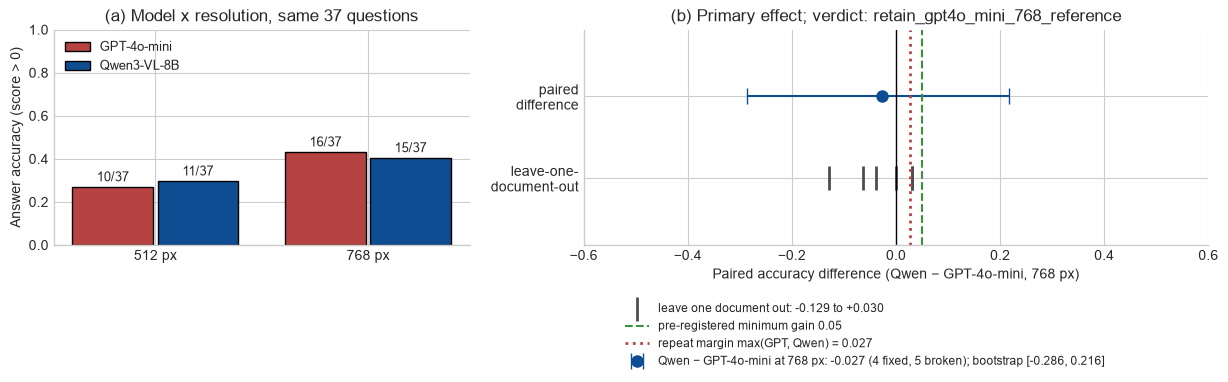

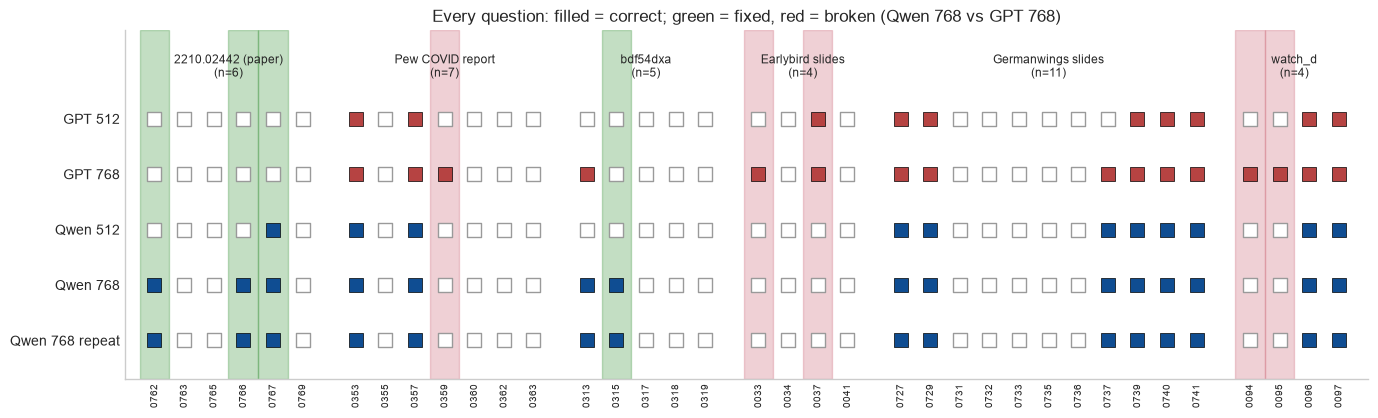

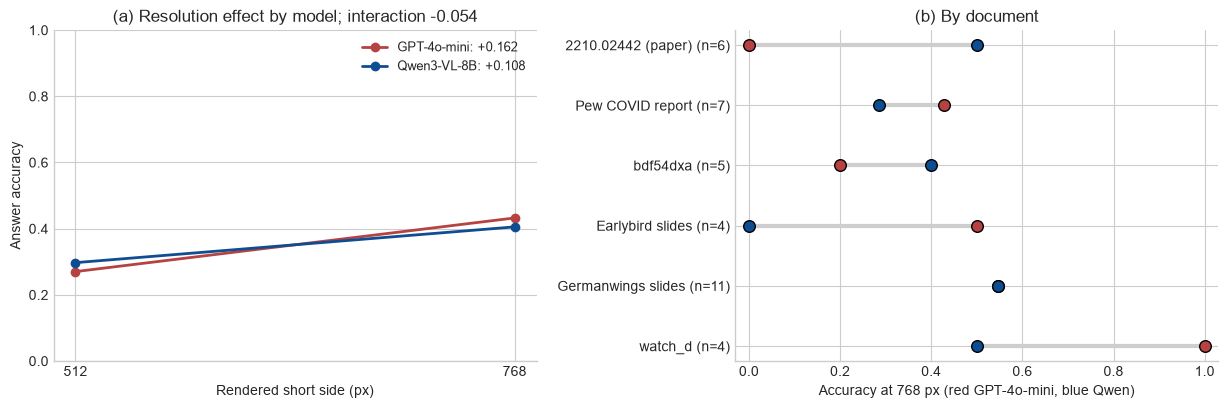

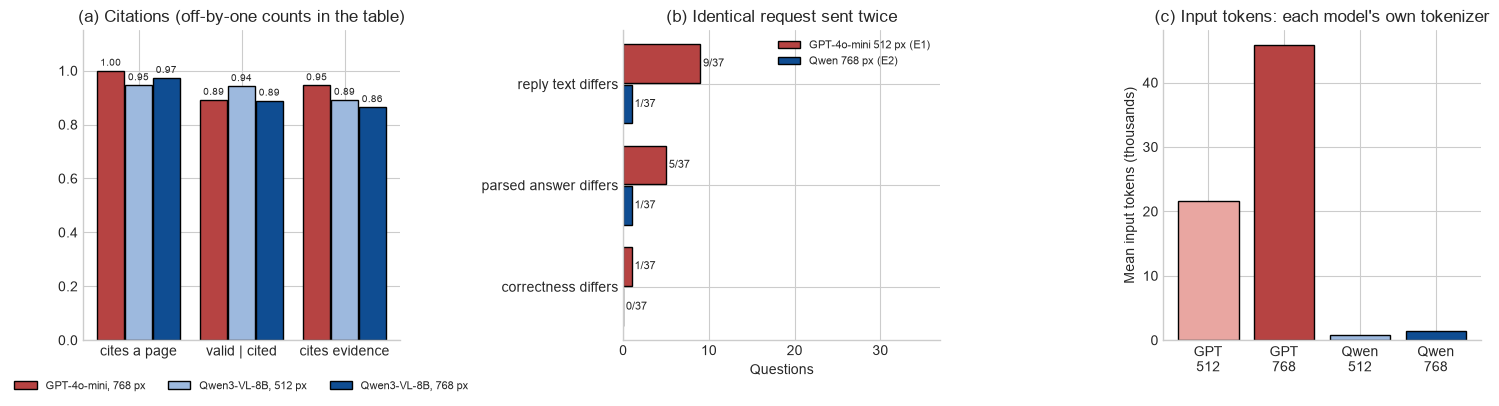

Frozen E2 result reproduced without any API call: checksums verified; 11/15/15 of 37 for Qwen (512, 768, 768 repeat) against 10/16/11 for GPT-4o-mini; 4 fixed / 5 broken; verdict retain_gpt4o_mini_768_reference; per-question table identical; independent audit 44/44.


In [32]:
# Evaluate E2: by default the frozen full run (experiments/frozen/e2/), or another saved run named by VISUALDOC_E2_RUN_DIR. No API call.
e2_run_value = os.getenv("VISUALDOC_E2_RUN_DIR", "").strip()
if not e2_run_value and not FROZEN_E2_RUN.is_dir():
    raise FileNotFoundError("E2 frozen run missing: restore experiments/frozen/e2/ from git or set VISUALDOC_E2_RUN_DIR.")
e2_run_dir = Path(e2_run_value or FROZEN_E2_RUN)
e2_run_dir = e2_run_dir if e2_run_dir.is_absolute() else PROJECT_ROOT / e2_run_dir
assert e2_run_dir.is_dir(), f"E2 run directory not found: {e2_run_dir}"
e2_is_frozen = e2_run_dir.resolve() == FROZEN_E2_RUN.resolve()
if e2_is_frozen:
    assert verify_sha256sums(FROZEN_E2_DIR), "experiments/frozen/e2/ does not match its SHA256SUMS"
e2_results, e2_table = evaluate_saved_e2_run(e2_run_dir, expected_spec_sha256=e2_spec_sha256, fig_dir=E2_DIR / "figures",
                                             table_path=E2_DIR / "per_question.csv", show=True)
e2_run_checks = e2_results["checks"]

if e2_is_frozen:
    # Regression references of the frozen E2 result (independent audit: experiments/frozen/e2/AUDIT.json, 44/44).
    e2_counts = {k: int(e2_table[f"correct_{k}"].sum()) for k in ("G512", "G768", "G512_r2", "Q512", "Q768", "Q768_r2")}
    assert e2_counts == {"G512": 10, "G768": 16, "G512_r2": 11, "Q512": 11, "Q768": 15, "Q768_r2": 15}, e2_counts
    assert (e2_results["primary"]["fixed"], e2_results["primary"]["broken"]) == (4, 5)
    assert e2_results["repeat"]["qwen_768"]["correctness_changed"] == 0 and e2_results["repeat"]["gpt4o_mini_512"]["correctness_changed"] == 1
    assert e2_results["decision"]["verdict"] == "retain_gpt4o_mini_768_reference"
    assert e2_results["execution"]["replied"] == 113 and e2_results["execution"]["rate_limited_responses"] == 3
    assert (E2_DIR / "per_question.csv").read_bytes() == (FROZEN_E2_DIR / "tables" / "per_question.csv").read_bytes(), "per-question table differs from the frozen one"
    e2_audit = json.loads((FROZEN_E2_DIR / "AUDIT.json").read_text())
    assert e2_audit["passed"] == e2_audit["total"] == 44 and e2_audit["recomputed"]["verdict"] == e2_results["decision"]["verdict"]
    print("Frozen E2 result reproduced without any API call: checksums verified; 11/15/15 of 37 for Qwen (512, 768, 768 repeat) against "
          "10/16/11 for GPT-4o-mini; 4 fixed / 5 broken; verdict retain_gpt4o_mini_768_reference; per-question table identical; "
          "independent audit 44/44.")
else:
    print("E2 evaluation of", e2_run_dir.name, "complete" + (": see the figures above." if e2_results["performance_reported"] else " (technical only)."))

**E2 result: retain GPT-4o-mini at 768 px.** On the same 37 questions and byte-identical page images, Qwen3-VL-8B at 768 px answered 15/37 against GPT-4o-mini's 16/37: 4 fixed, 5 broken, a paired difference of −0.027. The document-cluster bootstrap gives [−0.29, +0.22]. The gain is ≤ 0, so the pre-registered rule retains the reference, and none of the three adoption criteria holds. This is a tie within noise, not evidence that Qwen reads worse. One question is 0.027, and an exchange of four fixes for five breaks is the kind of shift the sample cannot resolve.

**What the evidence above shows.**

1. **Validation first.** Every run check passed, and the frozen package passed an independent audit (44/44, `experiments/frozen/e2/AUDIT.json`). That audit re-derived the plan, re-parsed every reply, recomputed costs and rescored all six cells outside this notebook. Every reply came from the pinned provider and matched the offline prompt-token expectation exactly, and OpenRouter's account total equals the recorded cost.
2. **Resolution helps Qwen too.** Qwen's 512 → 768-px change is +4 fixed, 0 broken (+0.108), against GPT-4o-mini's +0.162. The interaction (−0.054, [−0.24, +0.14]) is indistinguishable from zero, so E1's 768-px choice holds for both readers.
3. **Where the two models differ.** Qwen gains on the arXiv paper (3/6 against 0/6), where GPT-4o-mini fails at both resolutions. It loses small-print values on a slide and in a watch guidebook that GPT-4o-mini reads at 768 px (`0033`, `0094`).
4. **Answer formatting causes some breaks.** Two of the five broken questions are formatting rather than reading errors:
   - `0037`: a single string "The Economist and TIME" where the reference is a list;
   - `0095`: `2.5` where the reference is "2.5-3cm".

   Under strict accuracy (score = 1) the two readers tie exactly. The scorer is frozen; this is a lead for a future condition, not a correction.
5. **Stability.** Qwen's identical 768-px repeat changed no correctness and 1/37 reply texts; GPT-4o-mini's 512-px repeat changed 1 correctness and 9 texts. Provider caching is an unlikely explanation. Only 13 % of prompt tokens were cache reads, mostly the shared 128-token system prompt; 5 of the 111 main and repeat calls were at least 90 % cached. The "provider prompt-cache hits" row counts any call with a cached token.
6. **Citations.** Qwen cites an evidence page slightly less often (0.86 against 0.95 at 768 px). It also makes off-by-one citations (2 at 768 px, against 4 for GPT-4o-mini).
7. **Cost (descriptive; never part of the verdict).** Qwen at 768 px cost $0.014 for 37 questions (OpenRouter actual charge) against $0.255 (OpenAI list price), at similar median latency.

**Limits that this result does not remove.**

- 37 questions in 6 documents, so only large effects are detectable.
- Possible pretraining exposure: Qwen3-VL was released after the benchmark.
- No constrained JSON decoding for Qwen.
- The GPT-4o-mini repeat was measured only at 512 px.
- Hosted inference: the weight revision and image preprocessing behind the slug cannot be verified, and the slug may change later.
- Costs of different kinds: OpenRouter actual cost against OpenAI list price.

The verdict is an engineering choice of image reader for this pipeline and question set. It is not evidence that one model is better in general.

## Validation

In [33]:
# 1. Denominators: each condition covers its population minus protocol skips (D only), with no failed call.
assert len(A) == len(B) == 57 and len(C) == 40 and len(D) == 38 and set(D["qid"]) <= set(C["qid"])
assert all(frame["status"].isin(["ok", "parse_error"]).all() for frame in scored.values())
# 2. Paired comparisons are paired: identical question sets on both sides, one row per question.
for name, (a, b) in COMPARISONS.items():
    assert set(PAIRED[name]["qid"]) == set(a["qid"]) == set(b["qid"]) and PAIRED[name]["qid"].is_unique, name
# 3. A and B (and C and D) received exactly the same pages.
for x, y in (("A", "B"), ("C", "D")):
    pages_x = {r["qid"]: r["supplied_pages"] for r in records[x]}
    assert all(pages_x[r["qid"]] == r["supplied_pages"] for r in records[y]), (x, y)
# 4. Scores are in [0, 1] and 'correct' is exactly score > 0.
assert all(frame["score"].between(0, 1).all() and (frame["correct"] == (frame["score"] > 0)).all() for frame in scored.values())
# 5. Manual review: all 28 queued questions labelled, 29 cases in total, each with a known category.
assert (queue["manual_label"] != "pending").all() and set(queue["qid"]) <= set(MANUAL_REVIEW) and len(MANUAL_REVIEW) == 29
# 6. E1 protocol hash, required sections and decision boundaries are frozen and internally consistent.
assert e1_design["spec_sha256"] == e1_spec_sha256
assert {"hypotheses", "population", "evaluation_metrics", "decision_rule"} <= set(e1_spec)
assert "maximum_mean_input_token_ratio_768_over_512" not in e1_spec["decision_rule"]
assert {result["verdict"] for result in synthetic_decisions.values()} == {
    "adopt_768_for_this_model_and_population", "retain_512", "inconclusive"}
# 7. E1 frozen full run: integrity audit passed and regression references hold (sections 12-13).
assert all(value is not False for value in e1_audit.values())
assert (int(e1_metrics.loc["main_512", "correct"]), int(e1_metrics.loc["control_r2", "correct"]), int(e1_metrics.loc["main_768", "correct"])) == (10, 11, 16)
assert (primary["fixed"], primary["broken"], repeated_control["correctness_changed_questions"]) == (6, 0, 1)
# 8. E2: decision boundaries and mocked evaluation verified; an E2 result is reported only from a validated full run.
assert set(synthetic_e2.values()) == {"adopt_qwen3_vl_8b_768_for_this_pipeline", "retain_gpt4o_mini_768_reference", "inconclusive"}
assert e2_results is None or all(e2_run_checks.values())

evaluation_summary = {
    "predictions": prediction_manifest,
    "metrics": {LABELS.get(n, n): {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in condition_metrics(f).items()} for n, f in scored.items()},
    "paired": {name: paired_summary(p) for name, p in PAIRED.items()},
    "manual_review": MANUAL_REVIEW,
    "e1_readiness": {"design": e1_design, "cost_plan": e1_cost_plan.to_dict(orient="records"),
                         "empirical_results_loaded": e1_results is not None, "spec_sha256": e1_spec_sha256,
                     "evaluated_run": e1_settings["run_id"], "verdict": decision["verdict"]},
    "e2": {"spec_sha256": e2_spec_sha256, "spec_status": e2_spec["status"], "evaluated_run": (e2_results or {}).get("run_dir"),
           "performance_reported": bool(e2_results and e2_results.get("performance_reported")),
           "verdict": e2_results["decision"]["verdict"] if e2_results and e2_results.get("performance_reported") else None},
}
(PROCESSED_DIR / "evaluation_summary.json").write_text(json.dumps(evaluation_summary, indent=2, default=lambda v: v.item() if hasattr(v, "item") else str(v)))
assert len(json.loads((PROCESSED_DIR / "evaluation_summary.json").read_text())["manual_review"]) == 29
print("All validation checks passed. Summary saved to", (PROCESSED_DIR / "evaluation_summary.json").relative_to(PROJECT_ROOT))

All validation checks passed. Summary saved to data/processed/mmlongbench_doc/evaluation_summary.json


## Results and interpretation

*6 MMLongBench-Doc documents, 57 questions (40 answerable), gpt-4o-mini-2024-07-18, temperature 0, one run per condition; local rule-based scoring.*

| | A text, retrieved | B images, retrieved | C text, oracle | D images, oracle |
|---|---|---|---|---|
| correct, answerable | 7/40 (0.175) | 7/40 (0.175) | 9/40 (0.225); 9/38 (0.237) | 11/38 (0.289) |
| accuracy, all 57 / F1 | 0.263 / 0.165 | 0.228 / 0.156 | — | — |
| correct abstention (17 unanswerable) | 8/17 | 6/17 | — | — |
| citation validity | 1.000 | 0.895 | 1.000 | 0.921 |
| prompt tokens per question (mean) | ≈ 1.9k | ≈ 71k | ≈ 1.8k | ≈ 71k |

**Findings**

1. **Text reading, not retrieval, limits the text pipeline.** BM25 puts an evidence page in the top 5 for 32 of 40 questions (Hit@5 0.800), yet only 7 are answered correctly; giving the text model the evidence fixes 2.
2. **Images do not raise accuracy on the retrieved pages; they trade errors** (3 fixed, 3 broken, McNemar p = 1.00, 1 of 6 documents better). The fixes are in image-only slide decks where OCR misread or missed what the 512-px image shows (`mmlb-0729`: OCR read "42" for "12"); the breaks lose small detail (`mmlb-0033`, a small table; `mmlb-0313`, outlined text nearly illegible at 60 dpi; `mmlb-0096`, an irrelevant page cited).
3. **Images make the model answer more often, in both directions:** false abstentions fall from 4/40 to 1/40, but correct abstentions also fall from 8/17 to 6/17, so all-question accuracy and F1 drop slightly.
4. **A new citation failure.** Image replies cite pages that were not supplied (6 in B, 3 in D, none for text). In 7 of these 9 replies every invalid page is exactly one below a supplied page, consistent with citing the page number printed on the page.
5. **The image reader benefits more from correct pages** (4 fixed, 0 broken from retrieved to oracle, all on BM25 misses) than the text reader (2 fixed).
6. **Some errors are annotation or scoring artefacts** (4 of the 29 reviewed cases, below): a correct sentence-length answer scores 0 under the `Str` rule (`mmlb-0034`), two references cannot be scored under their declared `Int` format (`mmlb-0733`, `mmlb-0735`), and one reference is taken from a small caption ("Hour 3") rather than the slide text ("within the first 4 hours", `mmlb-0736`).

**Manual error review (29 cases).** One primary label per case for all 28 questions in the comparison-1 review queue (0 pending) and for `mmlb-0313`, a break outside the queue.

| primary label | queued (28) | all reviewed (29) |
|---|---|---|
| reasoning or aggregation | 11 | 11 |
| visual reading | 8 | 9 |
| annotation or scoring issue | 4 | 4 |
| text representation | 3 | 3 |
| retrieval | 2 | 2 |
| citation, abstention | 0 | 0 |

- **Most queued failures do not depend on the representation.** 23 queued questions are wrong for both readers (11 reasoning, 6 visual reading, 4 annotation, 2 retrieval), and 22 of them stay wrong in every oracle reply; only `mmlb-0359` is fixed (by text, on oracle pages). The reasoning failures are counts over a page or figure (`mmlb-0094`, `mmlb-0763`, `mmlb-0766`), differences of combined percentages (`mmlb-0360`, `mmlb-0362`, `mmlb-0363`), and a headline or title value taken instead of the chart (`mmlb-0355`, `mmlb-0041`).
- **Where the readers disagree, the labels match the mechanical diagnostic.** The 3 image fixes are text-representation failures: an OCR digit error (`mmlb-0729`) and two counts of visual items that the extracted text does not preserve (`mmlb-0732`, `mmlb-0739`; the mechanical check found the answer digit in the text, but not a countable structure). The 2 breaks (`mmlb-0033`, `mmlb-0096`) and `mmlb-0313` are visual-reading failures.
- **Visual reading fails on small detail at ≈ 60 dpi:** digits in small tables or infographics (`mmlb-0033`, `mmlb-0737`), labels and arrows in drawings (`mmlb-0095`, `mmlb-0315`, `mmlb-0317`), a ~12-px logo (`mmlb-0731`) and outlined text (`mmlb-0313`).
- **Retrieval is primary in only 2 cases** (`mmlb-0035`, `mmlb-0359`) because the queue requires some evidence in the top 5; of the 8 comparison-1 questions with none, only `mmlb-0313` was reviewed.

*Primary versus secondary.* The counts use primary labels only. Secondary factors are recorded in the explanations: partial retrieval misses where the oracle condition also failed (`mmlb-0362`, `mmlb-0762`, `mmlb-0765`, `mmlb-0766`, all labelled reasoning); an aggregation failure behind a retrieval miss (`mmlb-0035`, text oracle also wrong); small print (`mmlb-0733`, `mmlb-0763`); a scoring artefact (`mmlb-0041`, "300 million" would reject 300); and a citation of an unsupplied page (`mmlb-0317`). Citation and abstention errors occur, but are never primary.

*Uncertainty.* Five labels rest on evidence not fully verified: the reference of `mmlb-0318` (100 mm) still needs checking on the original high-resolution PDF; the reference counts of `mmlb-0762` and `mmlb-0763` were not independently verified on the low-resolution renders; `mmlb-0766` is ambiguous between figures and subplots; and `mmlb-0769` is a qualitative judgement, as the figure gives no variance values. A wrong reference would move a case to "annotation or scoring issue".

*Scope.* The cases were selected by the queue, not sampled, so these counts describe the reviewed selection, not error rates of the benchmark or of either reader.

**Hypotheses.** H1 (images > text on retrieved pages): **not supported** (0.175 = 0.175). H2 (larger image gain on chart/figure questions): **not supported**; the pattern follows the *document* (slide decks gain, low-resolution documents lose), which is confounded with evidence type and legibility. H3 (images > text on oracle pages): **direction consistent, not established** (+2 questions net, 6 fixed / 4 broken, p = 0.75).

**Synthesis.** With gpt-4o-mini and the ≈ 60-dpi images its token cost allows, swapping extracted text for page images changes *which* questions are answered rather than *how many*, at ≈ 37× the input tokens. Every statement rests on 38–57 questions in 6 documents and is a hypothesis to test, not a result to generalise.

**E1: image resolution (frozen full run `20261121T131525011829Z_29c92c8a`, sections 11–13).** On the 37 answerable questions whose annotated evidence pages fit the context at both resolutions, the same GPT-4o-mini snapshot answered **10/37 at 512 px and 16/37 at 768 px**: 6 fixed, 0 broken, paired difference 0.162. An identical second 512-px run gave 11/37 (one correctness flip, `mmlb-0313`, which is also one of the six fixes). The pre-registered rule (gain ≥ 0.05, gain > the 1/37 repeat flip rate, ≤ $0.10 per extra correct answer; observed $0.022) gives **adopt 768 px for this model and question set**. The fixes are small printed values: digits, counts and labels in slides, figures and charts. Questions that fail because of counting, aggregation or chart reasoning (21/37 wrong at both resolutions) are unaffected. Costs: 2.12× input tokens (1.79× or 2.59× by page shape), median latency 1.3 → 1.7 s, and two more off-by-one page citations (validity 94.4% → 89.2%). The integrity audit (section 12) confirms all 113 calls, replicate-isolated cache keys and no reused reply. The same requests are rebuilt byte for byte in 02. The 512-px repeat's agreement with run 1 is higher for requests served with OpenAI's prompt cache (18/20 vs 10/17 identical replies), so it probably understates cold-start variability.

**E2: Qwen3-VL-8B against GPT-4o-mini (section 14). Verdict: retain GPT-4o-mini at 768 px.** The design is a 2 × 2 of model × resolution on the same 37 questions and byte-identical E1 page images.

- **Accuracy:** Qwen answered 11/37 at 512 px and 15/37 at 768 px, against GPT-4o-mini's 10/37 and 16/37.
- **Primary 768-px comparison:** 4 fixed, 5 broken, −0.027, bootstrap [−0.29, +0.22]: a tie within noise.
- **Repeat:** Qwen's repeat changed no correctness.
- **Cost:** Qwen's 768-px cell cost $0.014 for 37 questions, against $0.255 for GPT-4o-mini.
- **Provenance:** the frozen run (`experiments/frozen/e2/`) passed an independent 44-check audit. The weight revision and image preprocessing behind the hosted API cannot be verified.

## Limitations

- **Small, clustered sample:** one question moves answerable accuracy by 0.025; McNemar p-values are optimistic; every subgroup result is exploratory.
- **Resolution set by cost:** the comparison is "text versus 512-px page images" (legibility proxy 0.05–0.06 on two documents).
- **Local scoring:** structured JSON answers replace the official GPT-4o extraction stage; scores are not leaderboard-comparable. Parity rests on hand-traced cases. 4 of 1,091 references can never score 1.0 (two in this subset: `mmlb-0733`, `mmlb-0735`).
- **Model variability:** at temperature 0, identical text runs changed 3–6 of 57 predictions. E1 full mode therefore reports every correctness flip between two 512-px controls (fixed, broken, total changed, percentage changed, and net accuracy difference). Adoption requires the 512-to-768 net gain to exceed the full control change rate, so opposite control changes cannot cancel. Two controls are only an observed sensitivity check, not a precise estimate of stochastic uncertainty. The pinned GPT-4o-mini snapshot is deprecated and scheduled for shutdown on 2027-01-14.
- **E1 is small and specific:** 37 questions in 6 documents, one model snapshot, oracle evidence pages only. One question moves accuracy by 0.027. The document-cluster bootstrap [0.081, 0.296] and McNemar p = 0.031 are descriptive (six clusters; McNemar ignores clustering). The result says nothing about retrieved pages, other models, or resolutions other than these two.
- **E1 code revision:** the full run was executed from uncommitted notebook code. It was committed afterwards in `4d202d5` together with the executed outputs that name the run. The executed source can therefore be identified with high, but not cryptographic, confidence (see `experiments/frozen/e1/README.md`).
- **E1 is answerable-only and context-limited:** correct abstention is not defined, and the three questions with 5–13 evidence pages are excluded from the matched 768-px population. A 1024-px render is downscaled to a 768-px short side by this model and is not a distinct information condition.
- **Citation validity is vacuous for empty citations** (abstentions cite `[]`): read it together with abstention counts.
- **Manual review covers a selection:** 29 queued or notable cases, one primary label each, no inter-annotator agreement measured; five labels rest on evidence not fully verified.

## Failure case to remember

`mmlb-0041`: the slide title says "exit values at around $350M"; both readers copied 350 while the chart shows about 300, and even 300 would score 0 against the reference string "300 million". A single wrong answer can mix a distractor, a reading error and a scoring artefact, which is why aggregate accuracy alone cannot explain the system.

## Next steps

1. Address the printed-page citation failure (state in the image prompt that printed page numbers are not the `[Page N]` tags, or stamp the tag into the image) as a **new condition**, compared with B.
2. Verify the uncertain references (`mmlb-0318`, `mmlb-0762`, `mmlb-0763`, `mmlb-0766`) on the original PDFs with `show_case(qid)`, and relabel a case if its reference is wrong; the scores and scoring rules stay as frozen.
3. Separate representation from resolution: repeat A–D with a model whose image tokens allow the default 768-px input, or test text + image together.
4. Measure image run-to-run variation (re-run B with the cache off, ≈ $0.56), then enlarge the sample (more documents or seeds).